In [1]:
%%capture
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Snake photo dataset: what do we actually have?

SerpentGuard AI, Group 5 (IIT Madras DS and AI Lab, 2026 T3), Milestone 2.

This notebook goes through the snake photos step by step: what is in the tables, how clean the data is, how the splits were made, what the images look like, and which extra sources could add something. Every number below is computed from the files when the notebook runs.

- Setup
- Where the data lives
- Helpers
- Loading the tables
- 1. Know the files
- 2. Labels
- 3. Splits and leakage
- 4. Images: every photo, from the metadata
- 5. Looking at the images
- 6. Context: where, when, who and under which licence
- 7. Safety lookalikes
- 9. Summary

## Setup
Imports first, then a few settings that the rest of the notebook uses.

In [2]:
import json
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from PIL import Image
from scipy.fft import dctn

warnings.filterwarnings("ignore")

In [3]:
ON_KAGGLE = Path("/kaggle/input").exists()
SMOKE = os.environ.get("SMOKE") == "1"
SEED = 42
SAMPLE_PER_CLASS = 3 if SMOKE else 30
print("on Kaggle:", ON_KAGGLE, "| quick test mode:", SMOKE)

on Kaggle: True | quick test mode: False


## Where the data lives
The team datasets are private on Kaggle. When the notebook runs on Kaggle they are attached as inputs, otherwise the helper below downloads them.

In [4]:
HANDLES = {
    "processed": "puneetbajajiitm/serpentguard-indian-snakes-processed",
    "splits": "puneetbajajiitm/serpentguard-m2-splits",
    "masks": "puneetbajajiitm/serpentguard-sam-masks",
}

In [5]:
def find(name):
    handle = HANDLES[name]
    owner, slug = handle.split("/")
    local = Path(os.environ.get("SERPENT_LOCAL", "no-local-copy")) / name
    for p in (Path("/kaggle/input/datasets") / owner / slug, Path("/kaggle/input") / slug, local):
        if p.exists():
            return p
    if ON_KAGGLE:
        raise FileNotFoundError(f"{handle} is not attached to this notebook")
    import kagglehub
    return Path(kagglehub.dataset_download(handle))

In [6]:
BASE, SPLITS, MASKS = find("processed"), find("splits"), find("masks")
for p in (BASE, SPLITS, MASKS):
    print(p)

/kaggle/input/datasets/puneetbajajiitm/serpentguard-indian-snakes-processed
/kaggle/input/datasets/puneetbajajiitm/serpentguard-m2-splits
/kaggle/input/datasets/puneetbajajiitm/serpentguard-sam-masks


In [7]:
WORK = Path("/kaggle/working") if ON_KAGGLE else Path(os.environ.get("SERPENT_WORK", "work_out"))
FIG = WORK / "figures"
FIG.mkdir(parents=True, exist_ok=True)

## Helpers
A few small helpers used all the way through. The colours stay the same in every chart: red for WHO category 1, orange for category 2 and grey for the rest.

In [8]:
WHO_COLORS = {"1": "#d62728", "2": "#ff7f0e", "not_listed": "#8a9bb0"}
WHO_LABEL = {"1": "WHO category 1", "2": "WHO category 2", "not_listed": "Not listed"}
SPLIT_ORDER = ["train", "val", "test", "test_extra", "unknown_pool"]
FMT = mticker.FuncFormatter(lambda x, _: f"{int(x):,}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

In [9]:
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=90, bbox_inches="tight")
    plt.show()

In [10]:
CHECKS = []

def check(label, ok, detail=""):
    CHECKS.append((label, bool(ok)))
    print(("PASS  " if ok else "FAIL  ") + label + (f"  ({detail})" if detail else ""))

In [11]:
def is_cc(license_code):
    return str(license_code).lower().startswith("cc")

def img_file(path):
    return BASE / "data" / path

In [12]:
def sample_ids(df, per_class, seed=SEED):
    if not ON_KAGGLE:
        df = df[df["path"].map(lambda p: img_file(p).exists())]
    shuffled = df.sample(frac=1, random_state=seed)
    return shuffled[shuffled.groupby("species").cumcount() < per_class]

In [13]:
# same perceptual hash as the dataset notebook: 32x32 grey, DCT, keep 8x8, median threshold
def phash64(image):
    gray = np.asarray(image.convert("L").resize((32, 32), Image.LANCZOS), dtype=np.float32)
    low = dctn(gray, norm="ortho")[:8, :8].flatten()
    bits = low > np.median(low[1:])
    return f"{int(''.join('1' if b else '0' for b in bits), 2):016x}"

In [14]:
def hamming(a, b):
    return bin(int(a, 16) ^ int(b, 16)).count("1")

## Loading the tables
Ids are read as text so they don't turn into floats. `created_at` carries a time-zone offset, so it is parsed as UTC.

In [15]:
ID_COLS = {"obs_id": str, "photo_id": str, "observer_id": str, "sha1": str, "phash": str, "who_category": str}
meta = pd.read_csv(BASE / "metadata.csv", dtype=ID_COLS)
meta.shape

(181231, 33)

In [16]:
meta["created_at"] = pd.to_datetime(meta["created_at"], utc=True)
meta["observed_on"] = pd.to_datetime(meta["observed_on"], errors="coerce")
meta["year"] = meta["observed_on"].dt.year
meta["month"] = meta["observed_on"].dt.month

In [17]:
classes = pd.read_csv(BASE / "classes.csv", dtype={"who_category": str})
splits_all = pd.read_csv(SPLITS / "splits.csv", dtype=ID_COLS)
excluded = pd.read_csv(SPLITS / "excluded.csv", dtype=ID_COLS)
mask_stats = pd.read_csv(MASKS / "mask_stats.csv", dtype={"photo_id": str, "who_category": str})
report = json.loads((BASE / "processing_report.json").read_text())

In [18]:
for name, d in [("metadata", meta), ("classes", classes), ("splits.csv", splits_all), ("excluded", excluded), ("mask_stats", mask_stats)]:
    print(f"{name:12s} {d.shape[0]:>8,} rows  {d.shape[1]:>2} columns")

metadata      181,231 rows  35 columns
classes           208 rows  13 columns
splits.csv    181,503 rows  31 columns
excluded          994 rows  25 columns
mask_stats    129,241 rows  17 columns


### Lookalike pairs
Some harmless snakes are easy to confuse with dangerous ones. These are the pairs from the Milestone 1 report (section 3.6, taken from iNaturalist's similar-species counts), plus two pairs where both snakes are dangerous. The WHO category of each species is always read from `classes.csv`, never typed in by hand.

In [19]:
LOOKALIKE_PAIRS = [
    ("Naja naja", "Ptyas mucosa", "spectacled cobra and oriental rat snake"),
    ("Bungarus caeruleus", "Lycodon aulicus", "common krait and Indian wolf snake"),
    ("Bungarus caeruleus", "Lycodon travancoricus", "common krait and Travancore wolf snake"),
    ("Bungarus caeruleus", "Lycodon fasciolatus", "common krait and Russell's wolf snake"),
    ("Daboia russelii", "Eryx conicus", "Russell's viper and rough-scaled sand boa"),
    ("Daboia russelii", "Python molurus", "Russell's viper and Indian rock python"),
    ("Echis carinatus", "Boiga trigonata", "saw-scaled viper and common cat snake"),
    ("Naja naja", "Fowlea piscator", "spectacled cobra and checkered keelback"),
    ("Craspedocephalus gramineus", "Rhabdophis plumbicolor", "bamboo pit viper and green keelback"),
]

In [20]:
DANGEROUS_PAIRS = [
    ("Hypnale hypnale", "Craspedocephalus malabaricus", "hump-nosed and Malabar pit viper"),
    ("Hypnale hypnale", "Echis carinatus", "hump-nosed pit viper and saw-scaled viper"),
]

In [21]:
who_of = classes.set_index("species")["who_category"].to_dict()
LOOKALIKES = [p for p in LOOKALIKE_PAIRS if p[0] in who_of and p[1] in who_of]
DANGEROUS = [p for p in DANGEROUS_PAIRS if p[0] in who_of and p[1] in who_of]
print(len(LOOKALIKES), "of", len(LOOKALIKE_PAIRS), "pairs found in classes.csv")

9 of 9 pairs found in classes.csv


## 1. Know the files
Before any charts, let's check what is in each file: the columns and their types, what is missing, whether the table matches the images on disk, and whether the counts agree between the files.

In [22]:
import time
import itertools
from scipy import stats

### 1.1 Columns and types
`metadata.csv` has one row per photo. Here is each column with its type, how many values are filled in and how many different values it has.

In [23]:
tab_schema = pd.DataFrame({"dtype": meta.dtypes.astype(str), "filled": meta.notna().sum(), "unique": meta.nunique()})
tab_schema

,dtype,filled,unique
file,object,181231,181231
source,object,181231,1
source_record_id,int64,181231,95787
obs_id,object,181231,95787
photo_id,object,181231,181231
photo_position,int64,181231,85
species,object,181231,289
genus,object,181231,77
taxon_id,int64,181231,289
record_taxon,object,181231,352


Ids such as `photo_id`, `obs_id` and `observer_id` are kept as text so they can't turn into floats. A few quick sanity checks on the table before going on.

In [24]:
check("photo_id is unique", meta["photo_id"].is_unique)
check("metadata.csv has the 33 raw columns", meta.shape[1] - 2 == 33, f"{meta.shape[1]} columns including year and month")
check("who_category holds the strings 1, 2 and not_listed", set(meta["who_category"]) == {"1", "2", "not_listed"})
check("every photo comes from iNaturalist", set(meta["source"]) == {"inaturalist"})

PASS  photo_id is unique
PASS  metadata.csv has the 33 raw columns  (35 columns including year and month)
PASS  who_category holds the strings 1, 2 and not_listed
PASS  every photo comes from iNaturalist


### 1.2 Missing values

In [25]:
tab_missing = meta.isna().sum()
tab_missing = tab_missing[tab_missing > 0].to_frame("missing")
tab_missing["share of rows %"] = (100 * tab_missing["missing"] / len(meta)).round(2)
tab_missing

,missing,share of rows %
latitude,1488,0.82
longitude,1488,0.82


In [26]:
check("only latitude and longitude have gaps", list(tab_missing.index) == ["latitude", "longitude"])
check("1,488 rows have no coordinates", tab_missing["missing"].tolist() == [1488, 1488])

PASS  only latitude and longitude have gaps
PASS  1,488 rows have no coordinates


The only gaps are in the two coordinate columns. Let's see what the rows without coordinates have in common.

In [27]:
tab_nocoord = meta[meta["latitude"].isna()]
print(f"{len(tab_nocoord):,} photos have no coordinates")
print("obscured:", tab_nocoord["obscured"].value_counts().to_dict())
print("inside India:", tab_nocoord["in_india"].value_counts().to_dict())
print("by split:", tab_nocoord["split"].value_counts().to_dict())
check("every photo without coordinates is marked obscured", tab_nocoord["obscured"].all())

1,488 photos have no coordinates
obscured: {True: 1488}
inside India: {False: 1488}
by split: {'train': 1084, 'test_extra': 239, 'val': 153, 'unknown_pool': 12}
PASS  every photo without coordinates is marked obscured


So a missing coordinate is not random: the observer hid the location. Maps and any location feature have to live with that, and the `in_india` flag is still filled for these rows.

### 1.3 Metadata rows against image files on disk
Each row has a `path` under `data/<split>/<species>/`. On Kaggle we list the folders and compare the names with the table. This is skipped in the quick test mode.

In [28]:
tab_disk, tab_t0 = set(), time.time()
if ON_KAGGLE and not SMOKE:
    try:
        for tab_split in os.scandir(BASE / "data"):
            for tab_sp in os.scandir(tab_split.path):
                tab_disk.update(f"{tab_split.name}/{tab_sp.name}/{f.name}" for f in os.scandir(tab_sp.path))
        print(f"listed {len(tab_disk):,} files in {time.time() - tab_t0:.0f} s")
    except OSError as err:
        print("could not list the image folders:", err)
else:
    print("skipped: the image folders are only listed in a full run on Kaggle")

listed 181,231 files in 0 s


In [29]:
if tab_disk:
    tab_no_file, tab_no_row = set(meta["path"]) - tab_disk, tab_disk - set(meta["path"])
    check("every metadata row has an image file", not tab_no_file, f"{len(tab_no_file):,} rows without a file")
    check("every image file has a metadata row", not tab_no_row, f"{len(tab_no_row):,} files without a row")
else:
    print("nothing to compare in this run")

PASS  every metadata row has an image file  (0 rows without a file)
PASS  every image file has a metadata row  (0 files without a row)


The `bytes` column should also match the real file size. Checking all 181k sizes would be slow on a network mount, so we look at 1,000 random photos.

In [30]:
def tab_size(p):
    try:
        return img_file(p).stat().st_size
    except OSError:
        return -1

if tab_disk:
    tab_pick = meta.sample(1000, random_state=SEED)
    tab_bad = int((tab_pick["path"].map(tab_size).values != tab_pick["bytes"].values).sum())
    check("file size on disk equals the bytes column (1,000 random photos)", tab_bad == 0, f"{tab_bad} differ")
else:
    print("skipped")

PASS  file size on disk equals the bytes column (1,000 random photos)  (0 differ)


### 1.4 `classes.csv` against the metadata
`classes.csv` has one row per class with the photo count in every split. Let's count the same thing from the metadata and compare.

In [31]:
tab_cols = ["train", "val", "test", "test_extra"]
tab_cls = classes.set_index("species")
tab_pivot = pd.crosstab(meta["species"], meta["split"]).reindex(index=tab_cls.index, columns=tab_cols, fill_value=0)
tab_diff = (tab_cls[tab_cols] - tab_pivot).abs()
print(f"classes.csv: {len(tab_cls)} classes, metadata: {meta['species'].nunique()} species")
print("classes where a split count differs:", int((tab_diff.sum(axis=1) > 0).sum()))
check("classes.csv counts equal the metadata counts for every class and split", tab_diff.values.sum() == 0)
check("classes.csv total equals the sum of its split columns", (tab_cls["total"] == tab_cls[tab_cols].sum(axis=1)).all())

classes.csv: 208 classes, metadata: 289 species
classes where a split count differs: 0
PASS  classes.csv counts equal the metadata counts for every class and split
PASS  classes.csv total equals the sum of its split columns


The metadata has more species than `classes.csv`. Let's see whether the extra ones are the unknown pool.

In [32]:
tab_extra_sp = set(meta["species"]) - set(tab_cls.index)
tab_unk_sp = set(meta.loc[meta["tier"] == "unknown_pool", "species"])
print(f"{len(tab_extra_sp)} species are in the metadata but not in classes.csv")
check("those species are exactly the unknown pool", tab_extra_sp == tab_unk_sp)

81 species are in the metadata but not in classes.csv
PASS  those species are exactly the unknown pool


In [33]:
tab_split_n = pd.DataFrame({"metadata.csv": meta["split"].value_counts(), "classes.csv": classes[tab_cols].sum()}).reindex(SPLIT_ORDER)
tab_split_n["share of photos %"] = (100 * tab_split_n["metadata.csv"] / len(meta)).round(1)
tab_split_n

,metadata.csv,classes.csv,share of photos %
train,129241,129241.0,71.3
val,25639,25639.0,14.1
test,7305,7305.0,4.0
test_extra,18390,18390.0,10.1
unknown_pool,656,NaN,0.4


The unknown pool has no row in `classes.csv`, which is why its column is empty. For every other split the two files agree.

### 1.5 What `processing_report.json` says
The report was written by the cleaning notebook. Let's compare its main numbers with what we can count ourselves.

In [34]:
tab_rows = [
    ("photos kept", report["status"]["kept"], len(meta)),
    ("near-duplicates dropped", report["status"]["near_duplicate"], int((~splits_all["photo_id"].isin(meta["photo_id"])).sum())),
    ("classes", report["classes"], len(classes)),
    ("tier1 classes", report["classes_by_tier"]["tier1"], int((classes["tier"] == "tier1").sum())),
    ("tier2 classes", report["classes_by_tier"]["tier2"], int((classes["tier"] == "tier2").sum())),
]
tab_rows += [(f"{s} photos", n, int((meta["split"] == s).sum())) for s, n in report["kept_by_split"].items()]
tab_rep = pd.DataFrame(tab_rows, columns=["what", "report says", "computed here"])
tab_rep

,what,report says,computed here
0,photos kept,181231,181231
1,near-duplicates dropped,272,272
2,classes,208,208
3,tier1 classes,68,68
4,tier2 classes,140,140
5,train photos,129241,129241
6,val photos,25639,25639
7,test_extra photos,18390,18390
8,test photos,7305,7305
9,unknown_pool photos,656,656


In [35]:
for what, said, got in tab_rows:
    check(f"processing_report: {what}", said == got, f"report {said:,}, computed {got:,}")
check("processing_report: no sha1 mismatches among kept photos", report["sha1_mismatches_among_kept"] == 0)

PASS  processing_report: photos kept  (report 181,231, computed 181,231)
PASS  processing_report: near-duplicates dropped  (report 272, computed 272)
PASS  processing_report: classes  (report 208, computed 208)
PASS  processing_report: tier1 classes  (report 68, computed 68)
PASS  processing_report: tier2 classes  (report 140, computed 140)
PASS  processing_report: train photos  (report 129,241, computed 129,241)
PASS  processing_report: val photos  (report 25,639, computed 25,639)
PASS  processing_report: test_extra photos  (report 18,390, computed 18,390)
PASS  processing_report: test photos  (report 7,305, computed 7,305)
PASS  processing_report: unknown_pool photos  (report 656, computed 656)
PASS  processing_report: no sha1 mismatches among kept photos


The report also lists the leakage counts it measured. We repeat that measurement ourselves in section 3.

In [36]:
tab_split_rep = json.loads((SPLITS / "split_report.json").read_text()) if (SPLITS / "split_report.json").exists() else {}
print("split_report.json found:", bool(tab_split_rep))
pd.Series(report["leakage"], name="overlap reported by the cleaning notebook").to_frame()

split_report.json found: True


,overlap reported by the cleaning notebook
observer_id_in_more_than_one_of_train_val_testfold,0
obs_id_in_more_than_one_of_train_val_testfold,0
sha1_in_more_than_one_of_train_val_testfold,0
phash_in_more_than_one_of_train_val_testfold,0


## 2. Labels
The task is to name the species, so the labels come first: how many photos each species has, how the species group into families, and how the WHO safety categories are spread.

### 2.1 Species long tail
The unknown-pool species are not classes, so this section counts only the classes listed in `classes.csv`. Let's rank the classes by photo count.

In [37]:
tab_in = meta[meta["tier"] != "unknown_pool"]
tab_n = tab_in.groupby("species").size().sort_values(ascending=False)
tab_rank = np.arange(1, len(tab_n) + 1)
print(f"{len(tab_n)} classes, {len(tab_in):,} photos; the unknown pool adds {len(meta) - len(tab_in):,} photos that are not used as classes")
tab_cum = 100 * tab_n.cumsum() / tab_n.sum()
print(f"top 10 classes hold {tab_n.head(10).sum() / tab_n.sum():.1%} of the photos, the 50 smallest hold {tab_n.tail(50).sum() / tab_n.sum():.1%}")
print(f"{int((tab_cum < 50).sum()) + 1} classes are enough to cover half of the photos")

208 classes, 180,575 photos; the unknown pool adds 656 photos that are not used as classes
top 10 classes hold 45.0% of the photos, the 50 smallest hold 1.0%
13 classes are enough to cover half of the photos


In [38]:
def tab_who_legend(ax, **kw):
    from matplotlib.lines import Line2D
    hs = [Line2D([], [], marker="o", ls="", color=c, label=WHO_LABEL[k]) for k, c in WHO_COLORS.items()]
    ax.legend(handles=hs, **kw)

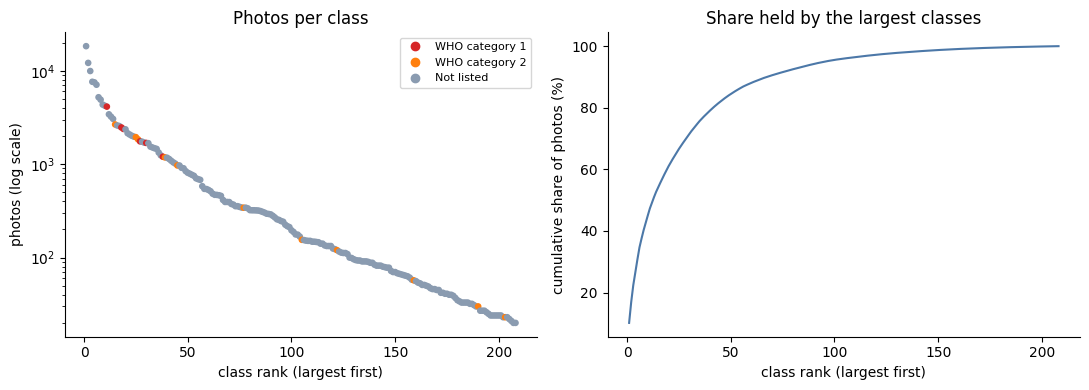

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(tab_rank, tab_n.values, c=[WHO_COLORS[who_of[s]] for s in tab_n.index], s=14)
ax[0].set(yscale="log", xlabel="class rank (largest first)", ylabel="photos (log scale)", title="Photos per class")
tab_who_legend(ax[0], loc="upper right", fontsize=8)
ax[1].plot(tab_rank, tab_cum.values, color="#4c78a8")
ax[1].set(xlabel="class rank (largest first)", ylabel="cumulative share of photos (%)", title="Share held by the largest classes")
savefig("02_long_tail"); plt.close()

On a log axis the classes fall along a long, fairly straight slope, which is what a long tail looks like. The dots are coloured by WHO category, so we can see where the dangerous species sit in the ranking. The quantiles below put numbers on it.

In [40]:
tab_q = tab_n.quantile([0, 0.1, 0.25, 0.5, 0.75, 0.9, 1]).round(0).astype(int).to_frame("photos per class")
tab_q.index = [f"{int(q * 100)}th percentile" for q in tab_q.index]
tab_q

,photos per class
0th percentile,20
10th percentile,32
25th percentile,62
50th percentile,162
75th percentile,755
90th percentile,2097
100th percentile,18328


### 2.2 Class imbalance
Three numbers describe how uneven the classes are: the ratio between the largest and smallest class, the Gini coefficient of the counts (0 means all equal, 1 means one class has everything) and the effective number of classes (how many equally sized classes would give the same spread).

In [41]:
def tab_gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    return float((2 * np.arange(1, len(x) + 1) - len(x) - 1).dot(x) / (len(x) * x.sum()))

def tab_imbalance(counts):
    p = counts / counts.sum()
    return pd.Series({"classes": len(counts), "largest class": counts.max(), "median class": counts.median(), "smallest class": counts.min(),
                      "imbalance ratio (largest / smallest)": counts.max() / counts.min(), "Gini of class counts": tab_gini(counts),
                      "effective classes (1 / sum p^2)": 1 / (p ** 2).sum(), "effective classes (exp of entropy)": np.exp(-(p * np.log(p)).sum())})

In [42]:
tab_imb = pd.DataFrame({"all splits": tab_imbalance(tab_n), "train only": tab_imbalance(classes.set_index("species")["train"])})
tab_imb.round(2)

,all splits,train only
classes,208.00,208.00
largest class,18328.00,13311.00
median class,161.50,117.00
smallest class,20.00,13.00
imbalance ratio (largest / smallest),916.40,1023.92
Gini of class counts,0.76,0.76
effective classes (1 / sum p^2),32.76,32.48
effective classes (exp of entropy),62.79,62.62


Now the tiny classes. Let's count how many classes fall under a few photo-count cut-offs.

In [43]:
tab_trn = classes.set_index("species")["train"]
tab_tiny = pd.DataFrame({"classes below": [(tab_n < c).sum() for c in (30, 50, 100, 200)], "train photos below": [(tab_trn < c).sum() for c in (30, 50, 100, 200)]}, index=[30, 50, 100, 200])
tab_tiny.index.name = "photo cut-off"
tab_tiny

,classes below,train photos below
photo cut-off,,
30,18,32
50,43,57
100,80,93
200,109,117


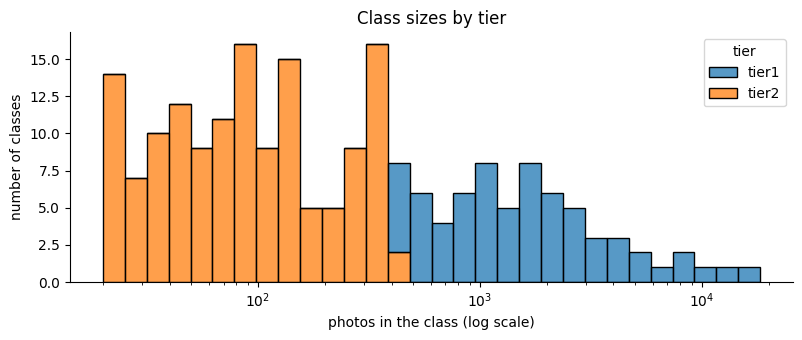

In [44]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(data=classes, x="total", hue="tier", multiple="stack", log_scale=True, bins=30, ax=ax)
ax.set(xlabel="photos in the class (log scale)", ylabel="number of classes", title="Class sizes by tier")
savefig("02_class_sizes"); plt.close()

The tiers are cut by class size, at about the same point, so the stacked histogram shows the same long tail from another side. The smallest classes are listed next, since a model is likely to struggle most with these.

In [45]:
tab_small = classes.sort_values("total").head(12)[["species", "family", "who_category", "tier", "train", "val", "test", "test_extra", "total"]]
tab_small.set_index("species")

,family,who_category,tier,train,val,test,test_extra,total
species,,,,,,,,
Platyceps ladacensis,Colubridae,not_listed,tier2,17,2,1,0,20
Boiga gocool,Colubridae,not_listed,tier2,14,3,2,1,20
Bungarus lividus,Elapidae,not_listed,tier2,13,6,1,1,21
Oligodon juglandifer,Colubridae,not_listed,tier2,14,6,2,0,22
Bungarus sindanus,Elapidae,2,tier2,17,2,2,2,23
Oligodon venustus,Colubridae,not_listed,tier2,15,5,3,0,23
Uropeltis shorttii,Uropeltidae,not_listed,tier2,20,1,1,1,23
Wallaceophis gujaratensis,Colubridae,not_listed,tier2,24,0,0,0,24
Hebius clerki,Colubridae,not_listed,tier2,19,2,3,0,24


### 2.3 Taxonomy
`family` and `genus` come with the metadata. Let's see how the species spread over the families, and over the genera inside each family.

In [46]:
tab_fam = meta.groupby("family").agg(photos=("photo_id", "size"), species=("species", "nunique"), genera=("genus", "nunique"))
tab_fam["classes"] = classes.groupby("family").size().reindex(tab_fam.index).fillna(0).astype(int)
tab_fam = tab_fam.sort_values("photos", ascending=False)
check("14 families in the metadata", len(tab_fam) == 14, f"{len(tab_fam)} found")
check("genus is the first word of the species name", (meta["species"].str.split().str[0] == meta["genus"]).all())
tab_fam

PASS  14 families in the metadata  (14 found)
PASS  genus is the first word of the species name


,photos,species,genera,classes
family,,,,
Colubridae,91495,148,33,112
Viperidae,22674,31,9,22
Typhlopidae,18898,4,4,4
Elapidae,18594,37,8,29
Pythonidae,9874,3,2,3
Psammodynastidae,7086,1,1,1
Homalopsidae,2726,7,7,7
Xenopeltidae,2560,1,1,1
Boidae,2387,4,1,3


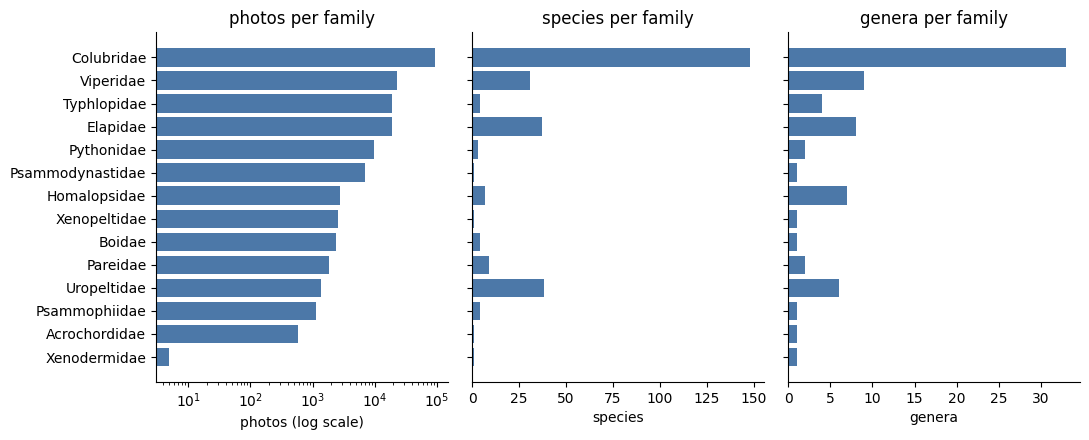

In [47]:
fig, ax = plt.subplots(1, 3, figsize=(11, 4.5), sharey=True)
for a, col, title in zip(ax, ["photos", "species", "genera"], ["photos (log scale)", "species", "genera"]):
    a.barh(tab_fam.index, tab_fam[col], color="#4c78a8")
    a.set(xlabel=title, title=f"{col} per family")
ax[0].set_xscale("log"); ax[0].invert_yaxis()
savefig("02_families"); plt.close()

A few families hold most of the photos and species, while the smallest families have only a handful. The family with the fewest photos has no class of its own: all of its photos sit in the unknown pool. Next, the genera with the most species.

In [48]:
tab_gen = meta.groupby(["family", "genus"]).agg(species=("species", "nunique"), photos=("photo_id", "size")).reset_index()
print(f"{meta['genus'].nunique()} genera in {meta['family'].nunique()} families, {tab_gen['species'].eq(1).sum()} of them with a single species")
tab_gen.sort_values(["species", "photos"], ascending=False).head(10).set_index("genus")

77 genera in 14 families, 29 of them with a single species


,family,species,photos
genus,,,
Lycodon,Colubridae,19,5816
Uropeltis,Uropeltidae,18,825
Boiga,Colubridae,17,5405
Oligodon,Colubridae,16,3703
Ahaetulla,Colubridae,13,16494
Dendrelaphis,Colubridae,12,4533
Hydrophis,Elapidae,12,3255
Trimeresurus,Viperidae,11,960
Craspedocephalus,Viperidae,8,5332


### 2.4 WHO categories
The WHO SEARO 2016 list marks medically important snakes: category 1 is the highest concern, category 2 the next. Everything else is "not listed". The category of each species comes from `classes.csv`.

In [49]:
tab_who = pd.DataFrame({"photos": meta["who_category"].value_counts(), "species": meta.groupby("who_category")["species"].nunique(),
                        "classes": classes["who_category"].value_counts()}).reindex(["1", "2", "not_listed"])
tab_who["share of photos %"] = (100 * tab_who["photos"] / tab_who["photos"].sum()).round(1)
tab_who["median photos per class"] = tab_in.groupby(["who_category", "species"]).size().groupby("who_category").median()
tab_who

,photos,species,classes,share of photos %,median photos per class
who_category,,,,,
1,13630,6,6,7.5,2069.0
2,9339,12,11,5.2,342.0
not_listed,158262,271,191,87.3,151.0


In [50]:
check("each species has a single WHO category in the metadata", (meta.groupby("species")["who_category"].nunique() == 1).all())
check("metadata and classes.csv give the same WHO category", (tab_in.drop_duplicates("species").set_index("species")["who_category"].reindex(tab_cls.index) == tab_cls["who_category"]).all())
check("6 classes in category 1 and 11 in category 2", classes["who_category"].value_counts().reindex(["1", "2"]).tolist() == [6, 11])

PASS  each species has a single WHO category in the metadata
PASS  metadata and classes.csv give the same WHO category
PASS  6 classes in category 1 and 11 in category 2


Let's put photos and classes side by side, and compare how many photos a class gets in each category.

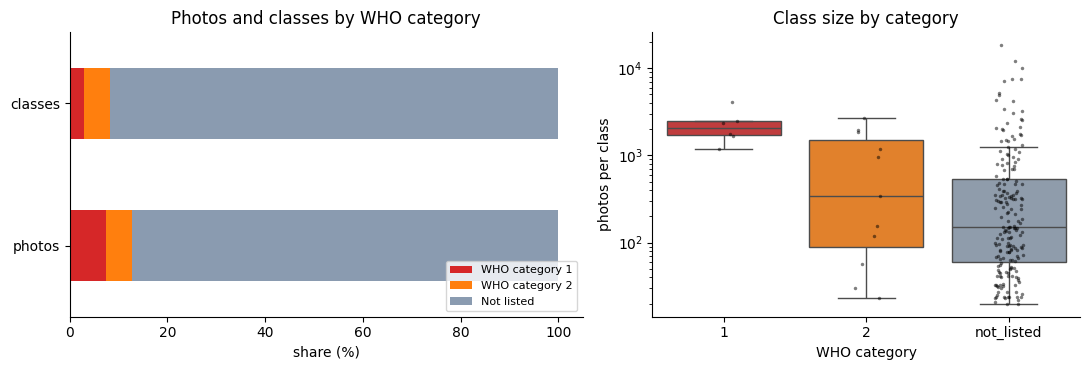

In [51]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
tab_pc = pd.DataFrame({"photos": tab_who["photos"], "classes": tab_who["classes"]})
(100 * tab_pc / tab_pc.sum()).T.plot.barh(stacked=True, color=[WHO_COLORS[c] for c in tab_pc.index], ax=ax[0], legend=False)
ax[0].set(xlabel="share (%)", title="Photos and classes by WHO category")
ax[0].legend([WHO_LABEL[c] for c in tab_pc.index], loc="lower right", fontsize=8)
sns.boxplot(data=classes, x="who_category", y="total", order=["1", "2", "not_listed"], palette=WHO_COLORS, ax=ax[1], fliersize=0)
sns.stripplot(data=classes, x="who_category", y="total", order=["1", "2", "not_listed"], color="black", size=2.5, alpha=0.5, ax=ax[1])
ax[1].set(yscale="log", xlabel="WHO category", ylabel="photos per class", title="Class size by category")
savefig("02_who"); plt.close()

The dangerous categories are a small part of the classes, and category 1 snakes are rather well photographed. The listed species themselves are in the table below, with their photos in each split.

In [52]:
tab_listed = classes[classes["who_category"] != "not_listed"].sort_values(["who_category", "total"], ascending=[True, False])
tab_listed.set_index("species")[["who_category", "tier", "train", "val", "test", "test_extra", "total"]]

,who_category,tier,train,val,test,test_extra,total
species,,,,,,,
Naja naja,1,tier1,2955,586,385,204,4130
Echis carinatus,1,tier1,1766,354,113,240,2473
Daboia russelii,1,tier1,1704,338,225,116,2383
Bungarus caeruleus,1,tier1,1253,251,192,59,1755
Hypnale hypnale,1,tier1,1206,241,176,65,1688
Naja kaouthia,1,tier1,858,172,24,147,1201
Craspedocephalus malabaricus,2,tier1,1892,377,330,62,2661
Bungarus fasciatus,2,tier1,1392,277,21,257,1947
Craspedocephalus gramineus,2,tier1,1206,238,339,64,1847


### 2.5 Tiers, the milestone-1 core 27 and the unknown pool
`tier1` classes have plenty of photos, `tier2` classes have fewer, and the unknown pool holds species that are too rare to be a class. `m1_core27` marks the 27 classes used in milestone 1.

In [53]:
tab_tier = meta.groupby("tier").agg(photos=("photo_id", "size"), species=("species", "nunique"))
tab_tier["median photos per species"] = meta.groupby(["tier", "species"]).size().groupby("tier").median()
tab_tier["category 1 or 2 species"] = meta[meta["who_category"] != "not_listed"].groupby("tier")["species"].nunique()
tab_tier.fillna(0).astype(int)

,photos,species,median photos per species,category 1 or 2 species
tier,,,,
tier1,162770,68,1468,11
tier2,17805,140,88,6
unknown_pool,656,81,7,1


In [54]:
tab_core = classes[classes["m1_core27"]]
print(f"core set: {len(tab_core)} classes, {tab_core['total'].sum():,} photos ({tab_core['total'].sum() / classes['total'].sum():.1%} of the class photos)")
print("tiers:", tab_core["tier"].value_counts().to_dict(), "| WHO:", tab_core["who_category"].value_counts().to_dict())
check("27 classes are in the milestone-1 core set", len(tab_core) == 27)
check("the unknown pool has 656 photos from 81 species", (len(meta[meta["tier"] == "unknown_pool"]), len(tab_unk_sp)) == (656, 81))

core set: 27 classes, 77,044 photos (42.7% of the class photos)
tiers: {'tier1': 27} | WHO: {'not_listed': 20, '1': 5, '2': 2}
PASS  27 classes are in the milestone-1 core set
PASS  the unknown pool has 656 photos from 81 species


PASS  every unknown-pool species has fewer photos than the smallest class  (19 vs 20)


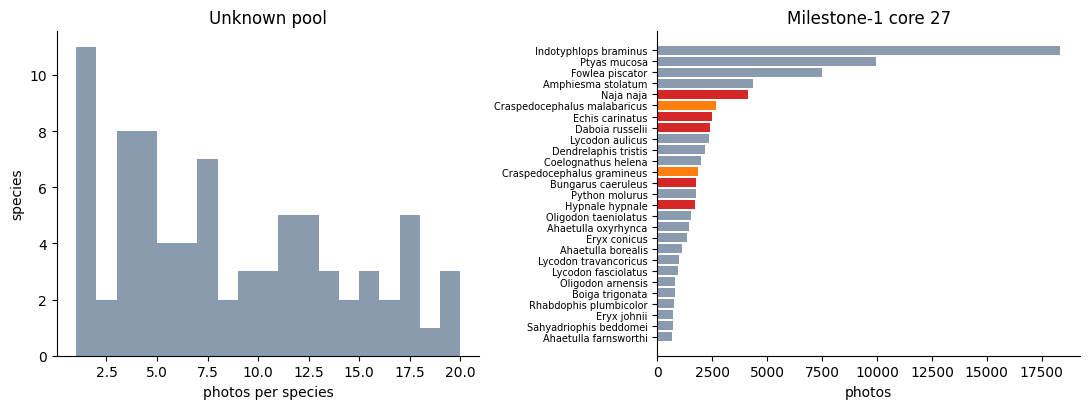

In [55]:
tab_unk_n = meta[meta["tier"] == "unknown_pool"].groupby("species").size()
check("every unknown-pool species has fewer photos than the smallest class", tab_unk_n.max() < classes["total"].min(), f"{tab_unk_n.max()} vs {classes['total'].min()}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].hist(tab_unk_n, bins=range(1, int(tab_unk_n.max()) + 2), color="#8a9bb0")
ax[0].set(xlabel="photos per species", ylabel="species", title="Unknown pool")
tab_c = tab_core.sort_values("total")
ax[1].barh(tab_c["species"], tab_c["total"], color=[WHO_COLORS[w] for w in tab_c["who_category"]])
ax[1].set(xlabel="photos", title="Milestone-1 core 27"); ax[1].tick_params(axis="y", labelsize=7)
savefig("02_tiers"); plt.close()

Unknown-pool species have only a few photos each, so they can't be trained as classes, but they are useful later as examples of snakes the model has never been taught. The core 27 are all well covered.

## 3. Splits and leakage
The photos are split into train, val, test, test_extra and the unknown pool. Let's check that the split is balanced per class, and that no observer, observation or image shows up on both sides of a split.

### 3.1 Per-class split balance
For every class we take its share of photos in each split. If the split was done evenly, these shares should be similar from class to class.

In [56]:
tab_share = tab_cls[tab_cols].div(tab_cls[tab_cols].sum(axis=1), axis=0)
tab_share_long = tab_share.reset_index().melt(id_vars="species", var_name="split", value_name="share").merge(classes[["species", "who_category", "total"]], on="species")
print("median share of a class's photos in each split:", (100 * tab_share.median()).round(1).to_dict())
tab_share.describe().loc[["mean", "std", "min", "max"]].round(3)

median share of a class's photos in each split: {'train': 71.5, 'val': 14.2, 'test': 7.4, 'test_extra': 6.0}


,train,val,test,test_extra
mean,0.720,0.142,0.067,0.071
std,0.049,0.038,0.052,0.054
min,0.500,0.000,0.000,0.000
max,1.000,0.381,0.301,0.267


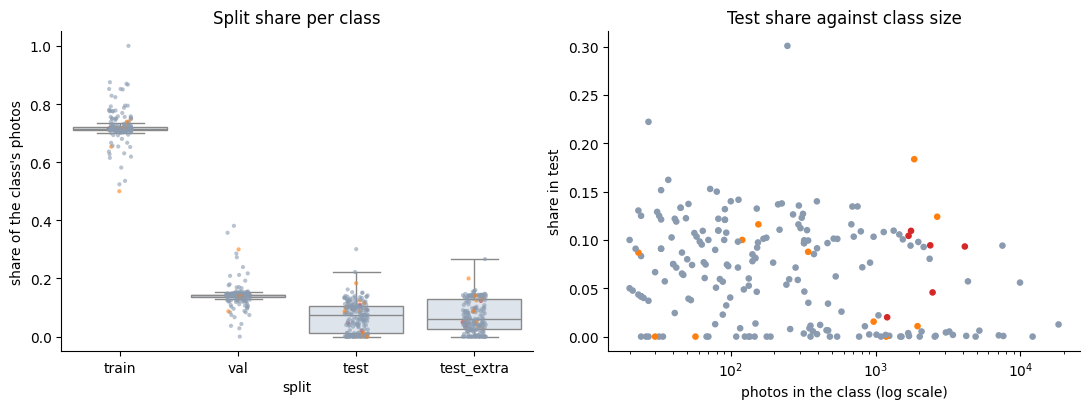

In [57]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
sns.boxplot(data=tab_share_long, x="split", y="share", color="#dbe4ee", fliersize=0, ax=ax[0])
sns.stripplot(data=tab_share_long, x="split", y="share", hue="who_category", palette=WHO_COLORS, size=3, alpha=0.6, legend=False, ax=ax[0])
ax[0].set(ylabel="share of the class's photos", title="Split share per class")
tab_t = tab_share_long[tab_share_long["split"] == "test"]
ax[1].scatter(tab_t["total"], tab_t["share"], c=[WHO_COLORS[w] for w in tab_t["who_category"]], s=14)
ax[1].set(xscale="log", xlabel="photos in the class (log scale)", ylabel="share in test", title="Test share against class size")
savefig("03_split_balance"); plt.close()

The train share is steady for big classes and varies more only for small ones. The test share jumps around at every class size: some classes get about a tenth of their photos in test and many get none. That fits the test rule in 3.4: only India photos uploaded in 2022 or later can go to test, so a class with few such photos ends up with little or no test data.

### 3.2 WHO share per split

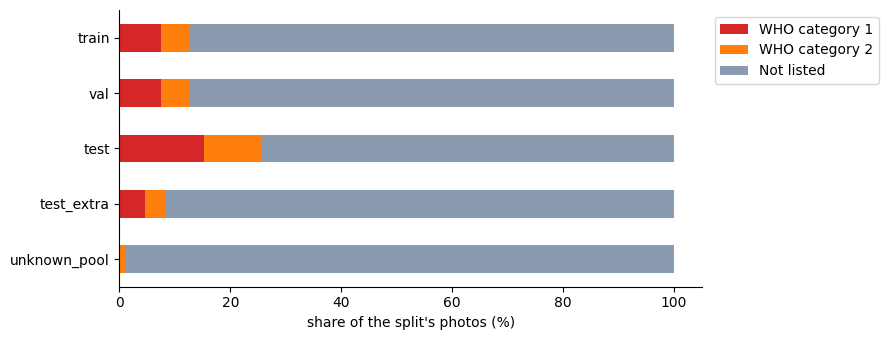

who_category,1,2,not_listed
split,,,
train,7.54,5.09,87.37
val,7.57,5.02,87.41
test,15.26,10.50,74.24
test_extra,4.52,3.80,91.68
unknown_pool,0.00,1.07,98.93


In [58]:
tab_ws = pd.crosstab(meta["split"], meta["who_category"], normalize="index").reindex(SPLIT_ORDER)[["1", "2", "not_listed"]] * 100
ax = tab_ws.plot.barh(stacked=True, color=[WHO_COLORS[c] for c in tab_ws.columns], figsize=(9, 3.5))
ax.set(xlabel="share of the split's photos (%)", ylabel=""); ax.invert_yaxis(); ax.legend([WHO_LABEL[c] for c in tab_ws.columns], bbox_to_anchor=(1.01, 1), loc="upper left")
savefig("03_who_per_split"); plt.close()
tab_ws.round(2)

Train and val have almost the same WHO mix. Test has a clearly larger share of category 1 and 2 photos than train, because India is where those snakes are most photographed, and test_extra has a smaller share. So a test score weighs the dangerous snakes more than a val score does.

### 3.3 Classes with no test photos

In [59]:
tab_zero = classes[classes["test"] == 0]
print(f"{len(tab_zero)} of {len(classes)} classes have no test photos; {(tab_zero['who_category'] != 'not_listed').sum()} of them are in WHO category 1 or 2")
print(f"{((classes['test'] == 0) & (classes['test_extra'] == 0)).sum()} classes have neither test nor test_extra photos, {(classes['val'] == 0).sum()} has no val photos")
check("28 classes have no test photos", len(tab_zero) == 28, f"{len(tab_zero)} found")
check("split_report.json gives the same number", tab_split_rep.get("classes_with_zero_test") == len(tab_zero))
tab_zero.sort_values("total", ascending=False).set_index("species")[["who_category", "tier", "train", "val", "test_extra"]]

28 of 208 classes have no test photos; 3 of them are in WHO category 1 or 2
1 classes have neither test nor test_extra photos, 1 has no val photos
PASS  28 classes have no test photos  (28 found)
PASS  split_report.json gives the same number


,who_category,tier,train,val,test_extra
species,,,,,
Ahaetulla prasina,not_listed,tier1,8693,1724,1718
Malayopython reticulatus,not_listed,tier1,3510,701,693
Xenopeltis unicolor,not_listed,tier1,1831,364,365
Gonyosoma oxycephalum,not_listed,tier1,1440,289,286
Pareas carinatus,not_listed,tier1,1080,215,214
Xenochrophis trianguligerus,not_listed,tier1,1060,210,210
Macrovipera lebetinus,2,tier1,883,151,147
Laticauda laticaudata,not_listed,tier1,778,155,156
Euprepiophis mandarinus,not_listed,tier1,549,110,110


For these classes the test score cannot be computed. Most of them still have val and test_extra photos, so they can be checked there, with the caveat that those photos don't follow the test rule.

### 3.4 The test rule: India, uploaded 2022-01-01 or later

In [60]:
tab_cut = pd.Timestamp("2022-01-01", tz="UTC")
tab_rule = meta.groupby("split").agg(photos=("photo_id", "size"), in_india=("in_india", "mean"), uploaded_2022_or_later=("created_at", lambda s: (s >= tab_cut).mean()))
tab_rule = (100 * tab_rule[["in_india", "uploaded_2022_or_later"]]).round(1).join(tab_rule["photos"]).reindex(SPLIT_ORDER)
tab_test = meta[meta["split"] == "test"]
tab_viol = (~tab_test["in_india"]) | (tab_test["created_at"] < tab_cut)
check("every test photo is in India and uploaded 2022-01-01 or later", tab_viol.sum() == 0, f"{int(tab_viol.sum())} violations in {len(tab_test):,} photos")
tab_rule.rename(columns={"in_india": "in India %", "uploaded_2022_or_later": "uploaded 2022+ %"})

PASS  every test photo is in India and uploaded 2022-01-01 or later  (0 violations in 7,305 photos)


,in India %,uploaded 2022+ %,photos
split,,,
train,37.6,82.9,129241
val,37.2,81.8,25639
test,100.0,100.0,7305
test_extra,12.7,68.9,18390
unknown_pool,83.8,85.5,656


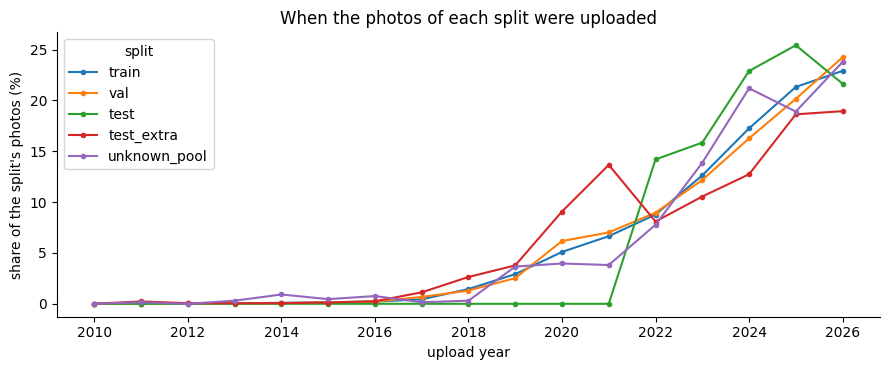

In [61]:
tab_up = pd.crosstab(meta["created_at"].dt.year, meta["split"], normalize="columns").reindex(columns=SPLIT_ORDER) * 100
ax = tab_up.plot(figsize=(9, 3.8), marker="o", ms=3)
ax.set(xlabel="upload year", ylabel="share of the split's photos (%)", title="When the photos of each split were uploaded")
savefig("03_upload_year"); plt.close()

Uploads grow fast over the years in every split, so most photos everywhere are recent. The difference is that test is cut at 2022 and holds India only, while train and val also hold older uploads and many photos from outside India. test_extra does not follow the rule, which is why it is kept apart.

### 3.5 Overlap between splits
A photo, an observation or an observer must not appear on both sides of a split. We count the shared values of four keys for every pair among train, val and test.

In [62]:
def tab_overlap(col, splits):
    sets = {s: set(meta.loc[meta["split"] == s, col]) for s in splits}
    return {f"{a} and {b}": len(sets[a] & sets[b]) for a, b in itertools.combinations(splits, 2)}

tab_leak = pd.DataFrame({col: tab_overlap(col, ["train", "val", "test"]) for col in ["observer_id", "obs_id", "sha1", "phash"]})
tab_leak

,observer_id,obs_id,sha1,phash
train and val,0,0,0,0
train and test,0,0,0,0
val and test,0,0,0,0


In [63]:
for col in tab_leak.columns:
    check(f"no {col} shared between train, val and test", tab_leak[col].sum() == 0, f"{tab_leak[col].sum()} shared")

PASS  no observer_id shared between train, val and test  (0 shared)
PASS  no obs_id shared between train, val and test  (0 shared)
PASS  no sha1 shared between train, val and test  (0 shared)
PASS  no phash shared between train, val and test  (0 shared)


For information, the same count when test_extra and the unknown pool are included. Only the pairs with a shared value are listed. These two splits are not part of the leakage rule.

In [64]:
tab_leak_all = pd.DataFrame({col: tab_overlap(col, ["train", "val", "test", "test_extra", "unknown_pool"]) for col in ["observer_id", "obs_id", "sha1", "phash"]})
tab_leak_all[tab_leak_all.sum(axis=1) > 0]

,observer_id,obs_id,sha1,phash
train and unknown_pool,143,0,0,0
val and unknown_pool,29,0,0,0
test and test_extra,122,0,0,0
test and unknown_pool,20,0,0,0
test_extra and unknown_pool,9,0,0,0


### 3.6 Beyond the split rule
The splits share no observer, observation, file hash or exact picture hash. That is a strict test, but it only catches identical copies. Two more questions: are there near-copies of training photos in val and test, and does the test set look like the training set in other ways such as country, photo shape and number of photographers?

#### Near-copies across splits
For every val, test and test_extra photo I look for the closest training photo by picture hash. Distance 0 is an identical hash. A few bits apart usually means the same scene, cropped or resized.

In [65]:
tab_hash = meta["phash"].map(lambda h: int(h, 16)).to_numpy(dtype=np.uint64)
tab_is_train = (meta["split"] == "train").to_numpy()
tab_train_hash = tab_hash[tab_is_train]
tab_train_species = meta.loc[tab_is_train, "species"].to_numpy()
len(tab_train_hash)

129241

In [66]:
def popcount(x):
    if hasattr(np, "bitwise_count"):
        return np.bitwise_count(x)
    bytes_view = np.ascontiguousarray(x).view(np.uint8).reshape(*x.shape, 8)
    return np.unpackbits(bytes_view, axis=-1).sum(axis=-1)

In [67]:
def nearest_train(query, step=128):
    best = np.zeros(len(query), dtype=int)
    arg = np.zeros(len(query), dtype=int)
    for i in range(0, len(query), step):
        d = popcount(query[i:i + step, None] ^ tab_train_hash[None, :])
        best[i:i + step], arg[i:i + step] = d.min(axis=1), d.argmin(axis=1)
    return best, arg

In [68]:
tab_near_rows = []
for name in ["val", "test", "test_extra"]:
    q = meta[meta["split"] == name]
    q = q.sample(min(len(q), 1500), random_state=SEED) if SMOKE else q
    qh = q["phash"].map(lambda h: int(h, 16)).to_numpy(dtype=np.uint64)
    dist, arg = nearest_train(qh)
    same = q["species"].to_numpy() == tab_train_species[arg]
    tab_near_rows.append({"split": name, "photos": len(q), "identical": int((dist == 0).sum()),
                          "within 2 bits": int((dist <= 2).sum()), "within 4 bits": int((dist <= 4).sum()),
                          "within 4 bits, same species": int(((dist <= 4) & same).sum())})
tab_near = pd.DataFrame(tab_near_rows).set_index("split")
tab_near

,photos,identical,within 2 bits,within 4 bits,"within 4 bits, same species"
split,,,,,
val,25639,0,13,23,14
test,7305,0,1,1,1
test_extra,18390,0,5,11,8


In [69]:
check("no val/test photo has an identical hash in train", tab_near["identical"].sum() == 0)
close = int(tab_near["within 2 bits"].sum())
print(f"{close} val/test photos are not identical to a training photo but sit within 2 bits of one")

PASS  no val/test photo has an identical hash in train
19 val/test photos are not identical to a training photo but sit within 2 bits of one


The dataset notebook dropped a val or test photo only when its hash was identical to a photo in an earlier split (that is the 272). Photos a few bits apart were kept. The table counts them. They are a tiny share of each split, but they are the ones that can quietly raise a score, and removing everything within 2 bits would be cheap. I'd flag this for the team rather than re-split now.

#### Country and danger level
The test set is India only by rule, but training photos also come from other countries. If danger level and country are linked in training, a model can read the scenery as a hint, and that hint is useless on an all-India test set.

In [70]:
tab_india = (meta[meta["split"].isin(SPLIT_ORDER[:4])].groupby(["split", "who_category"])["in_india"]
             .mean().unstack().mul(100).round(1).reindex(SPLIT_ORDER[:4]))
tab_india.rename(columns=WHO_LABEL)

who_category,WHO category 1,WHO category 2,Not listed
split,,,
train,77.7,55.5,33.1
val,78.2,59.6,32.3
test,100.0,100.0,100.0
test_extra,46.5,20.2,10.7


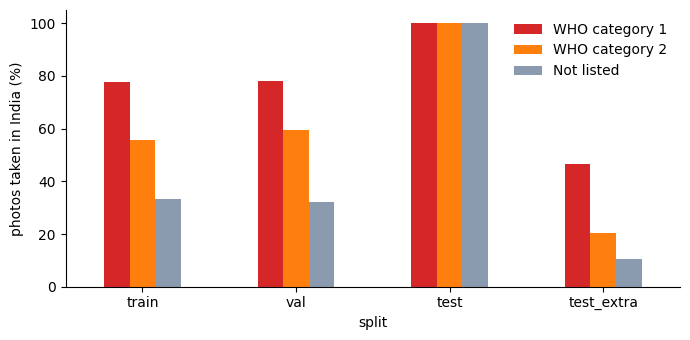

In [71]:
tab_india.plot(kind="bar", color=[WHO_COLORS[c] for c in tab_india.columns], figsize=(7, 3.5))
plt.ylabel("photos taken in India (%)")
plt.xticks(rotation=0)
plt.legend([WHO_LABEL[c] for c in tab_india.columns], frameon=False)
savefig("03b_india_share")
plt.close()

In training, 78% of category 1 photos and 56% of category 2 photos were taken in India, but only 33% of the not-listed ones. So in training, "looks like India" is a weak hint for "dangerous". The test set is all India, so that hint cannot help there. test_extra is the opposite and is mostly non-India.

#### Photo shape
Phones and cameras produce different shapes. If test photos are mostly portrait and training photos mostly landscape, random crops and flips in training will not cover what the test set looks like.

In [72]:
tab_shape = np.select([meta["height"] > meta["width"], meta["height"] < meta["width"]], ["portrait", "landscape"], "square")
tab_shape_share = pd.crosstab(meta["split"], tab_shape, normalize="index").mul(100).round(1)
tab_shape_share.reindex(SPLIT_ORDER[:4])

col_0,landscape,portrait,square
split,,,
train,57.2,40.7,2.1
val,57.9,40.0,2.1
test,42.4,55.8,1.8
test_extra,61.6,36.4,2.0


Training is mostly landscape (57%), test is mostly portrait (56%). Flips do not change that. Rotating by 90 degrees or cropping so that both shapes are covered would help, and validation accuracy should be reported for portrait photos on their own.

#### Photographers per class
Every photographer has a style, a camera and favourite places. When a class has only a few photographers a model can learn the person instead of the snake, and a test class with few photographers gives a noisy score.

In [73]:
tab_obs_train = meta[meta["split"] == "train"].groupby("species")["observer_id"].nunique()
tab_obs_test = meta[meta["split"] == "test"].groupby("species")["observer_id"].nunique()
tab_n_le5 = int((tab_obs_train <= 5).sum())
tab_n_test_le3 = int((tab_obs_test <= 3).sum())
print(f"{tab_n_le5} of {len(tab_obs_train)} classes have 5 or fewer training photographers")
print(f"{tab_n_test_le3} of {len(tab_obs_test)} classes with test photos have 3 or fewer test photographers")

3 of 208 classes have 5 or fewer training photographers
82 of 180 classes with test photos have 3 or fewer test photographers


In [74]:
tab_test_view = pd.DataFrame({"test photos": meta[meta["split"] == "test"].groupby("species").size(),
                              "test photographers": tab_obs_test}).sort_values(["test photographers", "test photos"])
tab_test_view.head(10)

,test photos,test photographers
species,,
Argyrophis diardii,1,1
Boiga multomaculata,1,1
Boiga stoliczkae,1,1
Bungarus lividus,1,1
Craspedocephalus peltopelor,1,1
Hebius khasiensis,1,1
Lycodon fasciatus,1,1
Melanophidium bilineatum,1,1
Oligodon cinereus,1,1


Only 3 of the 208 classes have five photographers or fewer in training, so photographer style is not a big worry on that side. The test side is thinner: 82 of the 180 classes with test photos have three photographers or fewer, and the ten smallest have one photo from one person. A test score for those classes says something about a single photo, so confidence intervals should be built by photographer and not by photo.

#### Several photos of the same sighting
One observation can carry up to five photos. They show the same animal, so they are not independent. The split keeps all photos of an observation together, which is why the observation overlap above is zero.

In [75]:
tab_per_obs = meta.groupby("obs_id").size()
tab_multi = tab_per_obs[tab_per_obs > 1]
print(f"{len(tab_per_obs):,} observations, {len(tab_multi):,} with more than one photo")
print(f"{100 * tab_multi.sum() / len(meta):.1f}% of photos belong to a multi-photo observation")

95,787 observations, 37,545 with more than one photo
67.9% of photos belong to a multi-photo observation


About two thirds of the photos come from observations with several photos, so they are far from independent. Because the split groups by observer, they stay on one side. Any validation split made inside the training set has to group by observation or observer as well, never by photo.

#### Subspecies and renamed species
The label is `species`. The column `record_taxon` keeps what the observer's identification said, which can be a subspecies or an older name.

In [76]:
tab_renamed = meta[meta["record_taxon"].notna() & (meta["record_taxon"] != meta["species"])]
print(f"{len(tab_renamed):,} photos ({100 * len(tab_renamed) / len(meta):.1f}%) have a record_taxon that differs from the label")
tab_renamed.groupby(["record_taxon", "species"]).size().sort_values(ascending=False).head(10)

8,578 photos (4.7%) have a record_taxon that differs from the label


record_taxon                             species                     
Coelognathus helena helena               Coelognathus helena             959
Echis carinatus sochureki                Echis carinatus                 793
Elaphe taeniura friesi                   Elaphe taeniura                 636
Oreocryptophis porphyraceus kawakamii    Oreocryptophis porphyraceus     622
Coelognathus helena monticollaris        Coelognathus helena             616
Macrovipera lebetinus obtusa             Macrovipera lebetinus           552
Oreocryptophis porphyraceus vaillanti    Oreocryptophis porphyraceus     459
Echis carinatus carinatus                Echis carinatus                 440
Psammodynastes pulverulentus papenfussi  Psammodynastes pulverulentus    392
Rhabdophis plumbicolor plumbicolor       Rhabdophis plumbicolor          275
dtype: int64

About one photo in twenty carries a subspecies name, for example *Coelognathus helena helena* and *Echis carinatus sochureki*. Folding subspecies into the species is right for a 208-class model, but it means a few classes mix forms that look quite different, so errors inside those classes need a second look before we blame the model.

## 4. Images: every photo, from the metadata
The table stores width, height and file size for all 181k photos, so we can describe the images without opening them. Looking at pixels comes in the next section, on a sample.

### 4.1 Width, height and file size

In [77]:
tab_img = meta[["photo_id", "species", "split", "who_category", "width", "height", "bytes", "url", "license", "cc_licensed"]].copy()
tab_img["short"] = tab_img[["width", "height"]].min(axis=1)
tab_img["long"] = tab_img[["width", "height"]].max(axis=1)
tab_img["aspect"] = tab_img["width"] / tab_img["height"]
tab_img["pixels"] = tab_img["width"] * tab_img["height"]
tab_img["bpp"] = tab_img["bytes"] / tab_img["pixels"]
tab_img["host"] = tab_img["url"].str.extract(r"//([^/]+)/")[0]
tab_img["url_ext"] = tab_img["url"].str.extract(r"\.(\w+)$")[0].str.lower()
tab_img.drop(columns=["url", "license"]).describe(percentiles=[0.01, 0.5, 0.99]).T.round(2)[["min", "1%", "50%", "99%", "max"]]

,min,1%,50%,99%,max
width,116.00,225.00,500.00,500.00,500.00
height,100.00,225.00,375.00,500.00,500.00
bytes,5003.00,22565.80,127956.00,318474.80,26155648.00
short,100.00,225.00,375.00,500.00,500.00
long,121.00,500.00,500.00,500.00,500.00
aspect,0.24,0.45,1.33,2.22,5.00
pixels,13794.00,112500.00,187500.00,250000.00,250000.00
bpp,0.03,0.13,0.75,1.75,154.71


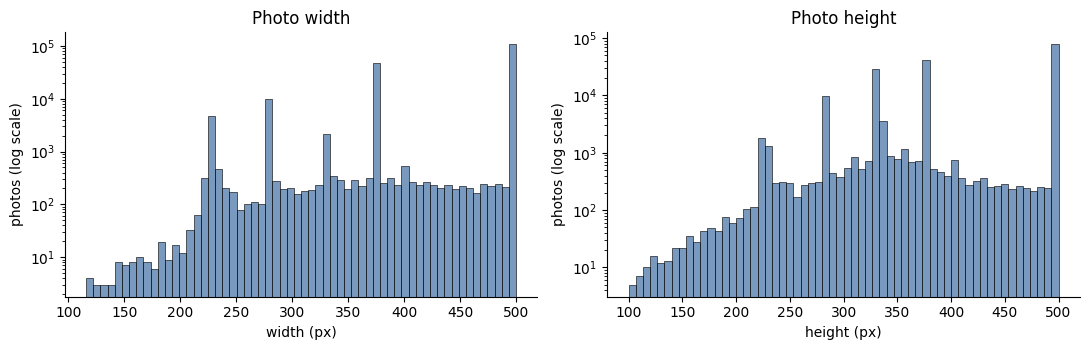

In [78]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, col in zip(ax, ["width", "height"]):
    sns.histplot(tab_img[col], bins=60, color="#4c78a8", ax=a)
    a.set(yscale="log", xlabel=f"{col} (px)", ylabel="photos (log scale)", title=f"Photo {col}")
savefig("04_width_height"); plt.close()

Both width and height pile up at 500, with the rest spread below it: landscape photos are 500 wide and portrait photos are 500 tall. The y-axis is logarithmic so that the small bars stay visible. This looks like a resize that caps the long side.

### 4.2 Aspect ratio and orientation

orientation share %: {'landscape': 57.0, 'portrait': 40.5, 'square': 2.5}


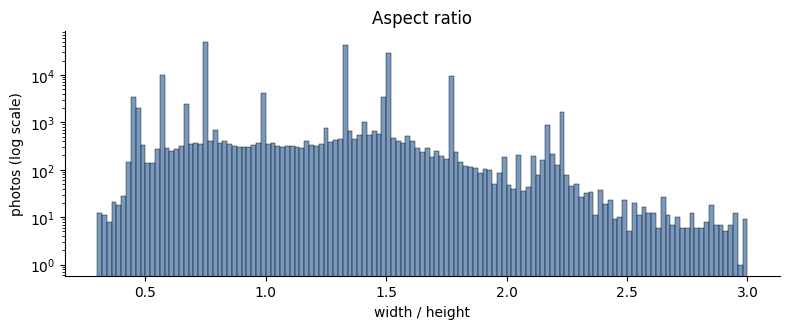

In [79]:
tab_ori = np.where(tab_img["aspect"] > 1.02, "landscape", np.where(tab_img["aspect"] < 0.98, "portrait", "square"))
print("orientation share %:", (100 * pd.Series(tab_ori).value_counts(normalize=True)).round(1).to_dict())
fig, ax = plt.subplots(figsize=(8, 3.4))
sns.histplot(tab_img["aspect"], bins=np.arange(0.3, 3.01, 0.02), color="#4c78a8", ax=ax)
ax.set(yscale="log", xlabel="width / height", ylabel="photos (log scale)", title="Aspect ratio")
savefig("04_aspect"); plt.close()

In [80]:
tab_asp = tab_img["aspect"].round(2).value_counts().head(8).to_frame("photos")
tab_asp["share %"] = (100 * tab_asp["photos"] / len(tab_img)).round(1)
tab_asp

,photos,share %
aspect,,
0.75,47802,26.4
1.33,41093,22.7
1.50,30108,16.6
0.56,9963,5.5
1.78,8869,4.9
1.00,3980,2.2
0.45,2913,1.6
0.67,2173,1.2


Camera shapes show up as spikes: a ratio of 1.33 is 4:3, 1.5 is 3:2 and 1.78 is 16:9, while 0.75, 0.67 and 0.56 are the same shapes held upright. A model has to deal with both landscape and portrait photos, so a plain square resize would distort many of them.

### 4.3 How many photos are small?
Many models take 224 px inputs, so let's count the photos whose short side is below 224, 256 and 320.

In [81]:
tab_small_share = pd.Series({t: (tab_img["short"] < t).mean() for t in (224, 256, 320)})
print("share of photos with the short side below each size (%):", (100 * tab_small_share).round(1).to_dict())
check("short side under 224 px for 0.7% of photos", round(100 * tab_small_share[224], 1) == 0.7)
check("short side under 256 px for 6.0% of photos", round(100 * tab_small_share[256], 1) == 6.0)
check("short side under 320 px for 19.7% of photos", round(100 * tab_small_share[320], 1) == 19.7)

share of photos with the short side below each size (%): {224: 0.7, 256: 6.0, 320: 19.7}
PASS  short side under 224 px for 0.7% of photos
PASS  short side under 256 px for 6.0% of photos
PASS  short side under 320 px for 19.7% of photos


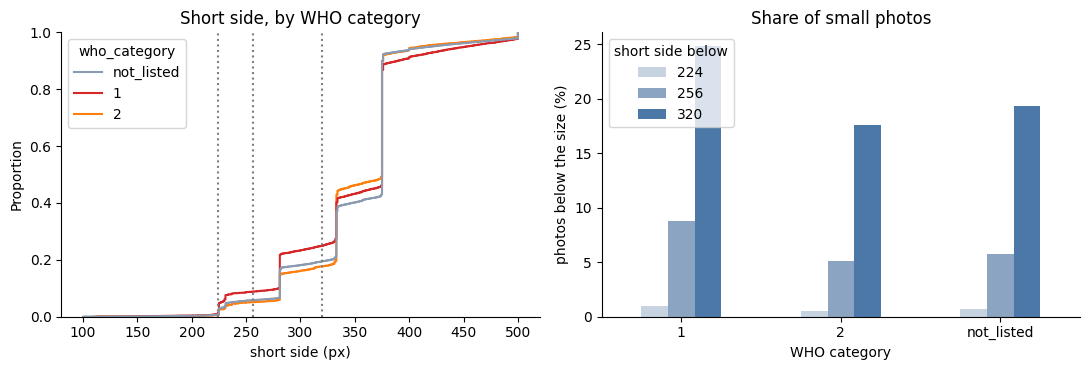

In [82]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.ecdfplot(data=tab_img, x="short", hue="who_category", palette=WHO_COLORS, ax=ax[0])
for t in (224, 256, 320):
    ax[0].axvline(t, color="grey", ls=":")
ax[0].set(xlabel="short side (px)", title="Short side, by WHO category")
tab_by = pd.DataFrame({t: tab_img.groupby("who_category")["short"].apply(lambda s, t=t: 100 * (s < t).mean()) for t in (224, 256, 320)})
tab_by.reindex(["1", "2", "not_listed"]).plot.bar(ax=ax[1], rot=0, color=["#c7d3e0", "#8aa4c1", "#4c78a8"])
ax[1].set(xlabel="WHO category", ylabel="photos below the size (%)", title="Share of small photos"); ax[1].legend(title="short side below", loc="upper left")
savefig("04_short_side"); plt.close()

The three curves have the same stair shape, with steps at the common camera sizes. Category 1 sits a little above the other two, so it has a somewhat larger share of small photos, but the gap is a few points. The dotted lines mark the three cut-offs used above.

### 4.4 The long side

In [83]:
tab_ls = tab_img["long"].value_counts()
print(f"long side exactly 500 px: {(tab_img['long'] == 500).mean():.2%}; below 500: {(tab_img['long'] < 500).sum():,}; above 500: {(tab_img['long'] > 500).sum():,}")
check("99.7% of photos have a long side of exactly 500 px", round(100 * (tab_img["long"] == 500).mean(), 1) == 99.7)
tab_img[tab_img["long"] < 500].groupby("url_ext").agg(photos=("photo_id", "size"), median_long_side=("long", "median"), median_short_side=("short", "median"))

long side exactly 500 px: 99.66%; below 500: 618; above 500: 0
PASS  99.7% of photos have a long side of exactly 500 px


,photos,median_long_side,median_short_side
url_ext,,,
gif,16,426.0,240.0
jpeg,224,400.5,329.0
jpg,358,418.0,310.0
png,20,423.0,246.0


Every address in the `url` column points to iNaturalist's "medium" size, which caps the long side at 500 px, so the few photos below that are smaller originals that were not enlarged. No photo is bigger than 500 px, which is small compared with what many models take as input.

### 4.5 File size

{'count': 181231.0, 'mean': 131.3, 'std': 128.4, 'min': 4.9, '1%': 22.0, '50%': 125.0, '99%': 311.0, 'max': 25542.6}
all photos together: 24.4 GB; the 100 largest files hold 1.1% of the bytes
PASS  the largest file is about 26 MB  (26.2 MB)


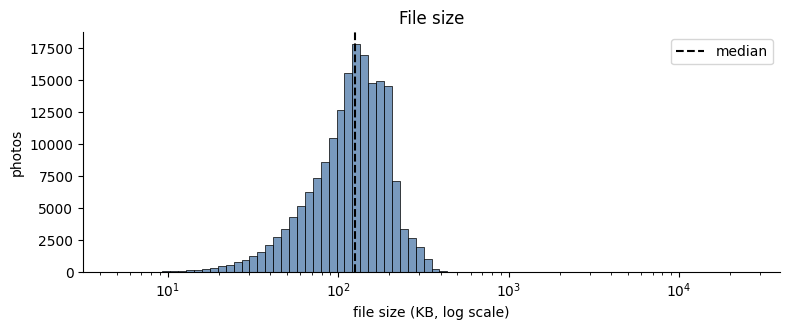

In [84]:
tab_kb = tab_img["bytes"] / 1024
print(tab_kb.describe(percentiles=[0.01, 0.5, 0.99]).round(1).to_dict())
print(f"all photos together: {tab_img['bytes'].sum() / 1e9:.1f} GB; the 100 largest files hold {tab_img['bytes'].nlargest(100).sum() / tab_img['bytes'].sum():.1%} of the bytes")
check("the largest file is about 26 MB", round(tab_img["bytes"].max() / 1e6) == 26, f"{tab_img['bytes'].max() / 1e6:.1f} MB")
fig, ax = plt.subplots(figsize=(8, 3.4))
sns.histplot(tab_kb, bins=80, log_scale=True, color="#4c78a8", ax=ax)
ax.axvline(tab_kb.median(), color="k", ls="--", label="median"); ax.legend()
ax.set(xlabel="file size (KB, log scale)", ylabel="photos", title="File size")
savefig("04_file_size"); plt.close()

Most files are around a hundred KB, but the right tail reaches far beyond what a 500 px JPEG should need. Let's look at bytes per pixel, which takes the image size out of the picture.

### 4.6 Bytes per pixel and the outliers

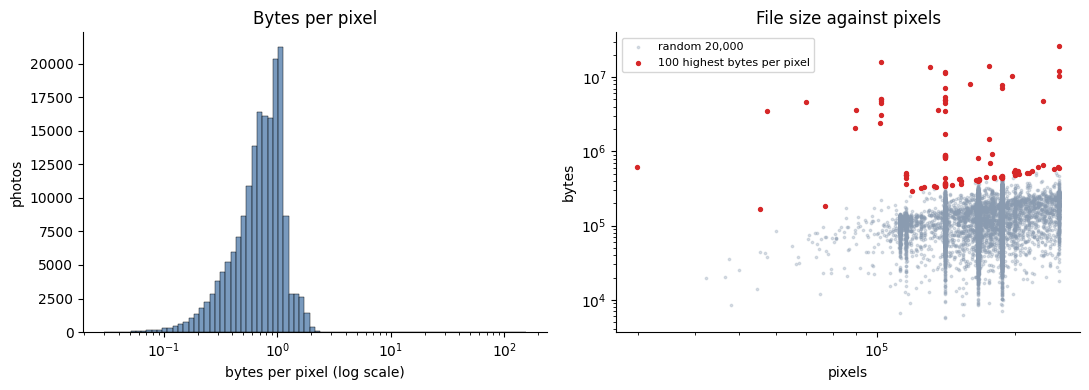

In [85]:
tab_s = tab_img.sample(20000, random_state=SEED)
tab_worst = tab_img.nlargest(100, "bpp")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(tab_img["bpp"], bins=80, log_scale=True, color="#4c78a8", ax=ax[0])
ax[0].set(xlabel="bytes per pixel (log scale)", ylabel="photos", title="Bytes per pixel")
ax[1].scatter(tab_s["pixels"], tab_s["bytes"], s=3, alpha=0.3, color="#8a9bb0", label="random 20,000")
ax[1].scatter(tab_worst["pixels"], tab_worst["bytes"], s=8, color="#d62728", label="100 highest bytes per pixel")
ax[1].set(xscale="log", yscale="log", xlabel="pixels", ylabel="bytes", title="File size against pixels"); ax[1].legend(fontsize=8)
savefig("04_bytes_per_pixel"); plt.close()

A normal JPEG sits in a tight band. The red points are far above that band: very large files for their size. Here are the worst ones.

In [86]:
tab_top = tab_img.nlargest(15, "bpp")
tab_top = tab_top.assign(MB=(tab_top["bytes"] / 1e6).round(1), bpp=tab_top["bpp"].round(1), size=tab_top["width"].astype(str) + " x " + tab_top["height"].astype(str))
tab_top[["photo_id", "species", "split", "size", "MB", "bpp", "url_ext", "host"]].set_index("photo_id")

,species,split,size,MB,bpp,url_ext,host
photo_id,,,,,,,
529154484,Elaphe taeniura,train,426 x 240,15.8,154.7,gif,inaturalist-open-data.s3.amazonaws.com
722159475,Python bivittatus,val,360 x 363,13.7,105.0,gif,inaturalist-open-data.s3.amazonaws.com
358893076,Indotyphlops braminus,val,500 x 500,26.2,104.6,gif,inaturalist-open-data.s3.amazonaws.com
420144884,Psammodynastes pulverulentus,train,500 x 282,11.6,82.2,gif,inaturalist-open-data.s3.amazonaws.com
420144851,Psammodynastes pulverulentus,train,500 x 282,11.5,81.4,gif,inaturalist-open-data.s3.amazonaws.com
336529607,Python bivittatus,val,500 x 352,14.2,80.7,gif,inaturalist-open-data.s3.amazonaws.com
267830672,Boiga cyanea,train,240 x 292,4.6,65.2,gif,inaturalist-open-data.s3.amazonaws.com
579667824,Protobothrops jerdonii,val,239 x 240,3.4,60.1,gif,inaturalist-open-data.s3.amazonaws.com
623670240,Ahaetulla prasina,train,445 x 444,10.4,52.6,gif,inaturalist-open-data.s3.amazonaws.com


Almost all of these point to a different file type in the `url` column. Every photo was saved with a `.jpg` name, but the address it was fetched from can end in `.gif` or `.png`. Let's group by the type in the address.

In [87]:
tab_ext = tab_img.groupby("url_ext").agg(photos=("photo_id", "size"), median_KB=("bytes", lambda s: s.median() / 1024), max_MB=("bytes", lambda s: s.max() / 1e6), median_bpp=("bpp", "median"))
tab_ext.round(2)
print("types among the 100 highest bytes-per-pixel files:", tab_worst["url_ext"].value_counts().to_dict())
print("type of the largest file:", tab_img.loc[tab_img["bytes"].idxmax(), "url_ext"])

types among the 100 highest bytes-per-pixel files: {'png': 62, 'gif': 35, 'jpg': 3}
type of the largest file: gif


So the largest file is a GIF, and the other extreme files are mostly PNG or GIF as well. A GIF can be an animation with many frames, which would explain the size. These files are few and make up a small part of the total bytes, but each one is slow to read. We'll keep this in mind for the image checks and for any model that reads files from disk.

### 4.7 The two image hosts
The `url` column points to two hosts: iNaturalist's open-data S3 bucket and `static.inaturalist.org`. These are two different sources of photos, so let's see whether they differ.

In [88]:
tab_host = pd.crosstab(tab_img["host"], tab_img["cc_licensed"])
tab_host["share of photos %"] = (100 * tab_host.sum(axis=1) / len(tab_img)).round(1)
tab_host

cc_licensed,False,True,share of photos %
host,,,
inaturalist-open-data.s3.amazonaws.com,0,124565,68.7
static.inaturalist.org,56662,4,31.3


In [89]:
tab_hg = tab_img.groupby("host").agg(photos=("photo_id", "size"), median_width=("width", "median"), median_height=("height", "median"), median_KB=("bytes", lambda s: s.median() / 1024),
                                      median_bpp=("bpp", "median"), under_224_pct=("short", lambda s: 100 * (s < 224).mean()), non_jpg_pct=("url_ext", lambda s: 100 * (~s.isin(["jpg", "jpeg"])).mean()))
tab_hg.round(2)

,photos,median_width,median_height,median_KB,median_bpp,under_224_pct,non_jpg_pct
host,,,,,,,
inaturalist-open-data.s3.amazonaws.com,124565,500.0,375.0,124.07,0.74,0.70,0.33
static.inaturalist.org,56666,500.0,375.0,126.79,0.76,0.59,0.22


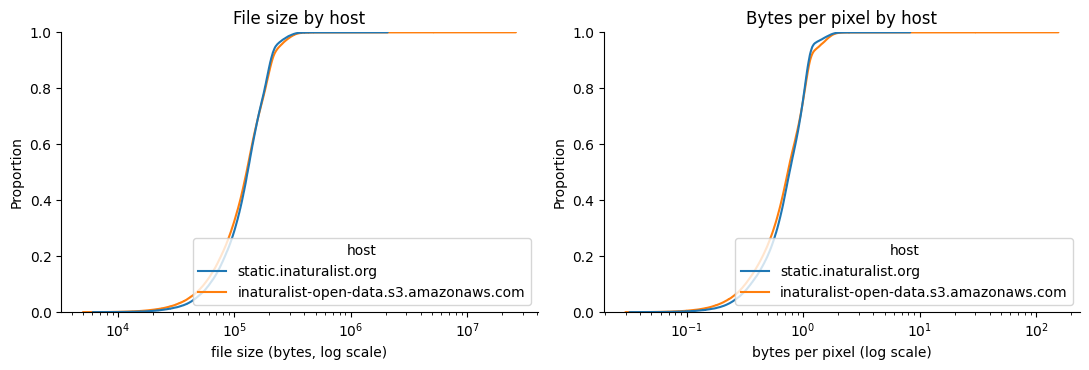

In [90]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.ecdfplot(data=tab_img, x="bytes", hue="host", log_scale=True, ax=ax[0])
sns.ecdfplot(data=tab_img, x="bpp", hue="host", log_scale=True, ax=ax[1])
ax[0].set(xlabel="file size (bytes, log scale)", title="File size by host"); ax[1].set(xlabel="bytes per pixel (log scale)", title="Bytes per pixel by host")
savefig("04_hosts"); plt.close()

If the two hosts had different image processing, the curves would separate. They lie close together, so the host mostly tells us which licence a photo has, not how it looks.

In [91]:
tab_a, tab_b = [g["bytes"].values for _, g in tab_img.groupby("host")]
tab_u = stats.mannwhitneyu(tab_a, tab_b, alternative="two-sided")
print(f"probability that a photo from the first host is larger than one from the second: {tab_u.statistic / (len(tab_a) * len(tab_b)):.3f} (0.5 means no difference)")
print(f"median file size: {np.median(tab_a) / 1024:.0f} KB against {np.median(tab_b) / 1024:.0f} KB")

probability that a photo from the first host is larger than one from the second: 0.488 (0.5 means no difference)
median file size: 124 KB against 127 KB


### 4.8 CC-licensed against other photos
`cc_licensed` is true for photos under any Creative Commons licence. Let's make the same comparison and see how much it overlaps with the host split.

In [92]:
tab_cg = tab_img.groupby("cc_licensed").agg(photos=("photo_id", "size"), median_width=("width", "median"), median_height=("height", "median"), median_KB=("bytes", lambda s: s.median() / 1024),
                                             median_bpp=("bpp", "median"), under_224_pct=("short", lambda s: 100 * (s < 224).mean()))
tab_cg.round(2)

,photos,median_width,median_height,median_KB,median_bpp,under_224_pct
cc_licensed,,,,,,
False,56662,500.0,375.0,126.79,0.76,0.59
True,124569,500.0,375.0,124.07,0.74,0.70


In [93]:
tab_agree = ((tab_img["host"] == "inaturalist-open-data.s3.amazonaws.com") == tab_img["cc_licensed"]).mean()
print(f"the host and the cc_licensed flag agree for {tab_agree:.3%} of the photos")
print("cc share by split (%):", (100 * tab_img.groupby("split")["cc_licensed"].mean()).round(1).to_dict())

the host and the cc_licensed flag agree for 99.998% of the photos
cc share by split (%): {'test': 72.3, 'test_extra': 74.3, 'train': 67.7, 'unknown_pool': 69.4, 'val': 69.1}


The two groupings describe almost the same photos, so the host comparison and the licence comparison give the same answer. The photos we can show in this notebook (CC only) look just like the rest in size and compression, so what we see in the grids is representative of the files.

## 5. Looking at the images
So far we only used the tables. Now we open real photos and measure them. Reading all 181k files would take far too long, so we work with a sample: up to 30 photos per species, drawn at random with a fixed seed.

For each photo we measure size, brightness, contrast, colourfulness, sharpness, saturation, orientation and the number of faces. We also recompute the perceptual hash and compare it with the stored one.

Every picture in this section is a CC0 or CC BY photo, with the photographer credit in a table under the grid. CC BY-NC is only a fallback when there are too few of those, and the table says so. Photos with a detected person are not shown: the grids pick photos without a detected face, and a note is printed if that is not possible.

### 5.1 The sample
`sample_ids` takes the same number of photos from every species, so rare species are much better represented than in the full table. That suits a per-class look at image quality, but it also means shares in the sample are not the shares in the dataset.

In [94]:
img_sample = sample_ids(meta, SAMPLE_PER_CLASS).copy()
print(f"{len(img_sample):,} photos from {img_sample['species'].nunique()} species")
img_sample["split"].value_counts()

6,784 photos from 289 species


split
train           4402
val              911
unknown_pool     656
test_extra       410
test             405
Name: count, dtype: int64

Let's compare the WHO mix of the sample with the mix of the whole dataset.

In [95]:
mix = pd.DataFrame({
    "sample": img_sample["who_category"].value_counts(normalize=True),
    "all photos": meta["who_category"].value_counts(normalize=True),
})
mix.round(3)

,sample,all photos
who_category,,
1,0.027,0.075
2,0.049,0.052
not_listed,0.925,0.873


### 5.2 Measuring each photo
What we compute for every photo:

| measure | how |
|---|---|
| width, height | pixels, read from the file itself |
| brightness | mean of the grey image (0 is black, 255 is white) |
| contrast | standard deviation of the grey image |
| colourfulness | Hasler and Süsstrunk measure, built from the red-green and yellow-blue differences |
| sharpness | variance of the Laplacian of the grey image, after resizing the long side to 256 px so big and small photos can be compared |
| saturation | mean HSV saturation, from 0 to 1 |
| orientation | landscape, portrait or square, from width and height |
| faces | number of faces found on a copy with a 320 px long side |
| pHash | recomputed with the same function the dataset notebook used |

In [96]:
import io
import time
import threading
from concurrent.futures import ThreadPoolExecutor

import cv2
import requests
from scipy.stats import kruskal
from tqdm import tqdm
from PIL import ImageDraw, ImageFont
from IPython.display import Image as ShowImage, Markdown, display

cv2.setNumThreads(1)

First the plain pixel measures. Colourfulness follows the Hasler and Süsstrunk formula. For sharpness every photo is brought to a 256 px long side first, because the Laplacian variance grows with resolution.

In [97]:
def img_fit(pic, side):
    scale = side / max(pic.shape[:2])
    how = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    return cv2.resize(pic, None, fx=scale, fy=scale, interpolation=how)

def img_colourfulness(arr):
    r, g, b = [arr[:, :, i].astype(np.float32) for i in range(3)]
    rg, yb = r - g, 0.5 * (r + g) - b
    spread = np.hypot(rg.std(), yb.std())
    centre = np.hypot(rg.mean(), yb.mean())
    return float(spread + 0.3 * centre)

def img_sharpness(grey):
    return float(cv2.Laplacian(img_fit(grey, 256), cv2.CV_64F).var())

In [98]:
def img_stats(arr):
    grey = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
    hsv = cv2.cvtColor(arr, cv2.COLOR_RGB2HSV)
    return {
        "brightness": float(grey.mean()),
        "contrast": float(grey.std()),
        "colorfulness": img_colourfulness(arr),
        "sharpness": img_sharpness(grey),
        "saturation": float(hsv[:, :, 1].mean() / 255),
    }

People holding snakes are common in this kind of dataset, so I also count faces. The classic OpenCV Haar cascade is fast but gives many false alarms on textured scenes like scales, bark and leaves, so the first choice here is the small YuNet face detector from the OpenCV model zoo (a download of about 230 KB). If YuNet cannot be loaded, the code falls back to the Haar cascade for frontal faces. The method that was used is stored with the results.

In [99]:
IMG_HAAR_URL = "https://raw.githubusercontent.com/opencv/opencv/4.10.0/data/haarcascades/haarcascade_frontalface_default.xml"
IMG_YUNET_URL = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"

def img_download(url, name):
    path = WORK / name
    if not path.exists():
        try:
            reply = requests.get(url, timeout=30)
            reply.raise_for_status()
            path.write_bytes(reply.content)
        except Exception as err:
            print("download failed:", name, str(err)[:60])
    return path if path.exists() else None

In [100]:
def img_yunet_ok(path):
    try:
        return path is not None and cv2.FaceDetectorYN.create(str(path), "", (320, 240)) is not None
    except Exception:
        return False

def img_face_setup():
    onnx = img_download(IMG_YUNET_URL, "yunet_face.onnx") if hasattr(cv2, "FaceDetectorYN") else None
    if img_yunet_ok(onnx):
        return "yunet", onnx
    if hasattr(cv2, "CascadeClassifier"):
        xml = Path(cv2.data.haarcascades) / "haarcascade_frontalface_default.xml"
        xml = xml if xml.exists() else img_download(IMG_HAAR_URL, "haar_frontalface.xml")
        if xml and not cv2.CascadeClassifier(str(xml)).empty():
            return "haar", xml
    return "none", None

In [101]:
img_face_method, img_face_file = img_face_setup()
print("OpenCV", cv2.__version__, "| face detector:", img_face_method)
if img_face_method == "none":
    print("warning: no face detector could be loaded, so face counts are all 0 and grids cannot be screened for people")

OpenCV 4.14.0 | face detector: yunet


In [102]:
img_local = threading.local()

def img_face_model():
    if not hasattr(img_local, "model"):
        if img_face_method == "haar":
            img_local.model = cv2.CascadeClassifier(str(img_face_file))
        else:
            img_local.model = cv2.FaceDetectorYN.create(str(img_face_file), "", (320, 240), 0.9, 0.3, 5000)
    return img_local.model

In [103]:
def img_face_count(arr):
    if img_face_method == "none":
        return 0
    small, model = img_fit(arr, 320), img_face_model()
    if img_face_method == "haar":
        return len(model.detectMultiScale(cv2.cvtColor(small, cv2.COLOR_RGB2GRAY), 1.1, 8, minSize=(40, 40)))
    model.setInputSize((small.shape[1], small.shape[0]))
    found = model.detect(cv2.cvtColor(small, cv2.COLOR_RGB2BGR))[1]
    return 0 if found is None else len(found)

Now one function that does everything for one photo. A photo that cannot be read is reported instead of stopping the whole run.

In [104]:
def img_measure(row):
    try:
        pic = Image.open(img_file(row.path)).convert("RGB")
        arr = np.asarray(pic)
        out = {"photo_id": row.photo_id, "width": pic.width, "height": pic.height}
        out.update(img_stats(arr))
        out.update(face_count=img_face_count(arr), phash_new=phash64(pic))
        return out
    except Exception as err:
        return {"photo_id": row.photo_id, "error": str(err)[:80]}

A quick test on the first photo of the sample before the big run.

In [105]:
img_first = next(img_sample.itertuples())
print(img_first.species, img_first.path)
{k: round(v, 2) if isinstance(v, float) else v for k, v in img_measure(img_first).items()}

Ptyas mucosa train/ptyas_mucosa/inaturalist_161852356.jpg


{'photo_id': '161852356',
 'width': 500,
 'height': 281,
 'brightness': 153.38,
 'contrast': 48.99,
 'colorfulness': 11.3,
 'sharpness': 402.95,
 'saturation': 0.1,
 'face_count': 0,
 'phash_new': 'b376968b48365569'}

### 5.3 Running it on the sample
Where does the time go? Each step is timed on its own for 60 photos, one thread, so we know what to expect from the full run.

In [106]:
def img_clock(fn, items):
    start = time.perf_counter()
    for item in items:
        fn(item)
    return (time.perf_counter() - start) / len(items) * 1000

img_paths = [img_file(p) for p in img_sample["path"].head(60)]
img_pics = [Image.open(p).convert("RGB") for p in img_paths]
img_arrs = [np.asarray(p) for p in img_pics]

In [107]:
img_steps = pd.Series({
    "open and decode": img_clock(lambda p: Image.open(p).convert("RGB"), img_paths),
    "pixel measures": img_clock(img_stats, img_arrs),
    "face detection": img_clock(img_face_count, img_arrs),
    "perceptual hash": img_clock(phash64, img_pics),
})
img_steps.round(1).rename("ms per photo")

open and decode     3.4
pixel measures      4.1
face detection     10.5
perceptual hash     1.7
Name: ms per photo, dtype: float64

Now the real run: 4 worker threads, plain progress bar.

In [108]:
img_rows = list(img_sample.itertuples())
img_start = time.time()
with ThreadPoolExecutor(max_workers=4) as pool:
    img_out = list(tqdm(pool.map(img_measure, img_rows), total=len(img_rows), mininterval=10))
img_secs = time.time() - img_start
img_failed = [o for o in img_out if "error" in o]
img_done = pd.DataFrame([o for o in img_out if "error" not in o])
print(f"{len(img_done):,} photos measured in {img_secs:.0f} s, {len(img_failed)} could not be read")

100%|██████████| 6784/6784 [01:45<00:00, 64.31it/s]

6,784 photos measured in 106 s, 0 could not be read


Time per 1,000 photos, and what that means for the full sample of 30 photos per species.

In [109]:
per_1000 = img_secs / len(img_out) * 1000
full_sample = len(classes) * 30
print(f"{per_1000:.0f} s per 1,000 photos with 4 threads")
print(f"a full sample of {full_sample:,} photos (30 per species) would take about {per_1000 * full_sample / 1000 / 60:.1f} min")
check("image sample finished well inside the time budget", img_secs < 900, f"{img_secs:.0f} s")

16 s per 1,000 photos with 4 threads
a full sample of 6,240 photos (30 per species) would take about 1.6 min
PASS  image sample finished well inside the time budget  (106 s)


### 5.4 The `quality` table
One row per photo: the measures plus the columns from `metadata.csv` that we want to group by. It is also saved to `quality.csv`.

In [110]:
img_cols = ["photo_id", "species", "who_category", "split", "family", "year", "license", "cc_licensed",
            "path", "attribution", "bytes", "phash", "width", "height"]
img_names = {"phash": "phash_stored", "width": "meta_width", "height": "meta_height"}
quality = img_sample[img_cols].rename(columns=img_names).merge(img_done, on="photo_id").reset_index(drop=True)
quality.shape

(6784, 23)

In [111]:
quality["orientation"] = np.select(
    [quality["width"] > quality["height"], quality["width"] < quality["height"]], ["landscape", "portrait"], "square")
quality["short_side"] = quality[["width", "height"]].min(axis=1)
quality["phash_dist"] = [hamming(a, b) for a, b in zip(quality["phash_stored"], quality["phash_new"])]
quality["phash_ok"] = quality["phash_dist"] <= 2
quality["face_method"] = img_face_method
quality.to_csv(WORK / "quality.csv", index=False)
print(quality.shape, "saved to quality.csv")

(6784, 28) saved to quality.csv


In [112]:
img_need = ["photo_id", "species", "who_category", "split", "family", "year", "license", "cc_licensed", "width", "height",
            "brightness", "contrast", "colorfulness", "sharpness", "saturation", "orientation", "phash_ok", "face_count"]
check("quality has all the agreed columns", set(img_need) <= set(quality.columns))
check("one row per photo that could be read", quality["photo_id"].is_unique and len(quality) == len(img_done))
same_size = (quality["width"] == quality["meta_width"]) & (quality["height"] == quality["meta_height"])
check("width and height read from the files match metadata.csv", same_size.mean() >= 0.99, f"{same_size.mean():.1%}")

PASS  quality has all the agreed columns
PASS  one row per photo that could be read
PASS  width and height read from the files match metadata.csv  (100.0%)


A first look at the numbers.

In [113]:
IMG_COLS = ["brightness", "contrast", "colorfulness", "sharpness", "saturation", "short_side"]
quality[IMG_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
brightness,6784.0,110.59,37.12,0.87,88.81,116.00,136.05,241.41
contrast,6784.0,45.09,13.60,2.11,35.48,44.93,54.36,102.97
colorfulness,6784.0,29.09,15.88,0.00,17.15,26.46,37.89,126.40
sharpness,6784.0,2204.65,1996.19,6.01,741.43,1633.33,3025.97,17808.27
saturation,6784.0,0.30,0.18,0.00,0.15,0.26,0.41,0.96
short_side,6784.0,346.48,56.03,100.00,333.00,375.00,375.00,500.00


Most photos should have a long side of exactly 500 px, since the dataset was resized. Let's compare the sample with the full table, so we know the sample does not hide anything odd about sizes.

In [114]:
long_all = meta[["width", "height"]].max(axis=1)
long_smp = quality[["width", "height"]].max(axis=1)
short_all = meta[["width", "height"]].min(axis=1)
print(f"long side exactly 500 px: sample {(long_smp == 500).mean():.1%}, all photos {(long_all == 500).mean():.1%}")
print(f"short side under 224 px: sample {(quality['short_side'] < 224).mean():.1%}, all photos {(short_all < 224).mean():.1%}")
print(quality["orientation"].value_counts(normalize=True).round(3).to_dict())

long side exactly 500 px: sample 99.7%, all photos 99.7%
short side under 224 px: sample 0.7%, all photos 0.7%
{'landscape': 0.598, 'portrait': 0.376, 'square': 0.025}


### 5.5 Is the stored pHash the one we get back?
The hash was computed when the dataset was built. If the files on Kaggle are the same files, the recomputed hash should be almost identical. A few bits can differ because JPEG decoders round slightly differently, so the gate is a Hamming distance of 2 or less.

In [115]:
share = quality["phash_ok"].mean()
check("recomputed pHash is within Hamming 2 of the stored one for at least 99% of the sample", share >= 0.99, f"{share:.2%}")
quality["phash_dist"].value_counts().sort_index().head(8)

PASS  recomputed pHash is within Hamming 2 of the stored one for at least 99% of the sample  (100.00%)


phash_dist
0    6784
Name: count, dtype: int64

### 5.6 Near-duplicates inside the sample
The splits were cleaned so that no pHash is shared between train, val and test. Within the sample we can still look for pairs of different photos with a Hamming distance of 2 or less, using the recomputed hashes.

In [116]:
def img_near_pairs(hashes, limit=2):
    bits = np.array([int(h, 16) for h in hashes], dtype=np.uint64)
    pairs = []
    for start in range(0, len(bits), 500):
        dist = np.bitwise_count(bits[start:start + 500, None] ^ bits[None, :])
        i, j = np.nonzero(dist <= limit)
        keep = (i + start) < j
        pairs += list(zip(i[keep] + start, j[keep]))
    return pairs

In [117]:
img_pairs = img_near_pairs(quality["phash_new"])
img_a = quality.iloc[[a for a, b in img_pairs]].reset_index(drop=True)
img_b = quality.iloc[[b for a, b in img_pairs]].reset_index(drop=True)
print(f"{len(img_pairs)} near-duplicate pairs among {len(quality):,} photos")
print(f"same species: {(img_a['species'] == img_b['species']).sum()}, same split: {(img_a['split'] == img_b['split']).sum()}")
img_dups = pd.DataFrame({"photo_a": img_a["photo_id"], "photo_b": img_b["photo_id"], "species_a": img_a["species"],
                         "species_b": img_b["species"], "split_a": img_a["split"], "split_b": img_b["split"],
                         "distance": [hamming(x, y) for x, y in zip(img_a["phash_new"], img_b["phash_new"])]})
img_dups.head(10)

14 near-duplicate pairs among 6,784 photos
same species: 14, same split: 13


,photo_a,photo_b,species_a,species_b,split_a,split_b,distance
0,48746944,651160950,Boiga wallachi,Boiga wallachi,unknown_pool,unknown_pool,0
1,586283084,586283195,Uropeltis ocellata,Uropeltis ocellata,train,train,0
2,408044234,408044304,Calliophis melanurus,Calliophis melanurus,train,train,0
3,718387839,718387802,Uropeltis myhendrae,Uropeltis myhendrae,train,train,2
4,325250134,325250082,Lycodon zawi,Lycodon zawi,train,train,2
5,327314698,327314727,Lycodon flavicollis,Lycodon flavicollis,val,val,2
6,389348796,389348726,Rhinophis sanguineus,Rhinophis sanguineus,unknown_pool,unknown_pool,2
7,325249969,325249952,Lycodon zawi,Lycodon zawi,train,train,2
8,693875746,693875665,Dendrelaphis biloreatus,Dendrelaphis biloreatus,unknown_pool,unknown_pool,2
9,160051137,177411969,Spalerosophis arenarius,Spalerosophis arenarius,unknown_pool,unknown_pool,2


### 5.7 Distributions of the measures
One histogram per measure. Sharpness is drawn on a log scale because a few very busy photos have a Laplacian variance far above the rest. The last panel is the short side in pixels, which shows the small photos.

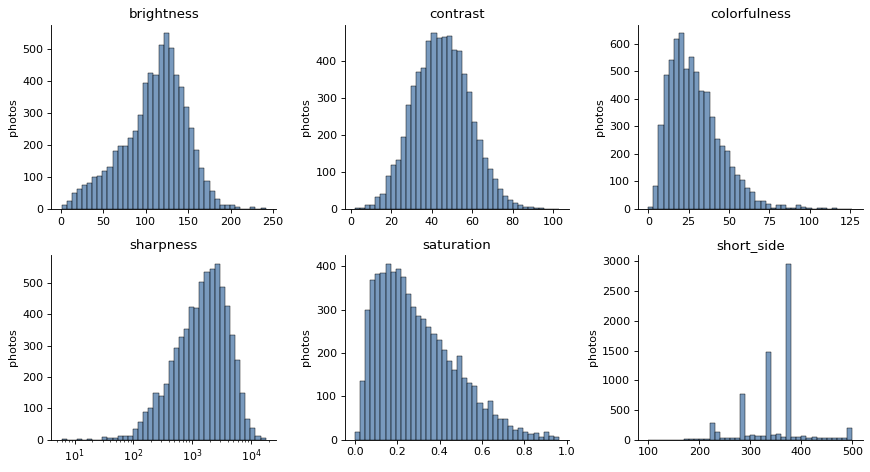

brightness    median  116.00   1% to 99%:   16.78 to  183.65
contrast      median   44.93   1% to 99%:   15.55 to   77.32
colorfulness  median   26.46   1% to 99%:    5.77 to   78.95
sharpness     median 1633.33   1% to 99%:  105.58 to 9276.65
saturation    median    0.26   1% to 99%:    0.04 to    0.81


In [118]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6), dpi=80)
for ax, col in zip(axes.flat, IMG_COLS):
    data = quality[col].clip(lower=0.1) if col == "sharpness" else quality[col]
    sns.histplot(data, bins=40, color="#4c78a8", log_scale=(col == "sharpness"), ax=ax)
    ax.set(title=col, xlabel="", ylabel="photos")
savefig("img_distributions")
plt.close()
for col in IMG_COLS[:5]:
    low, high = quality[col].quantile([0.01, 0.99])
    print(f"{col:13s} median {quality[col].median():7.2f}   1% to 99%: {low:7.2f} to {high:7.2f}")

Do the measures move together? A Spearman correlation tells us whether, for example, dark photos are also the blurry ones.

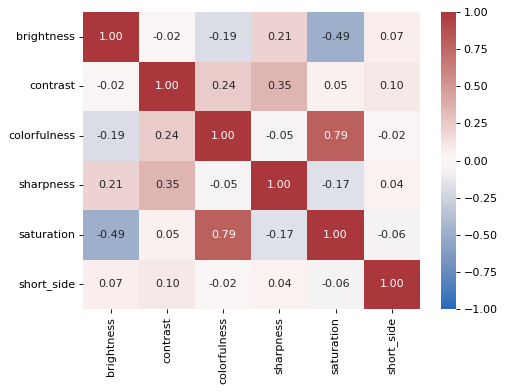

In [119]:
fig, ax = plt.subplots(figsize=(6.5, 5), dpi=80)
sns.heatmap(quality[IMG_COLS].corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
savefig("img_correlations")
plt.close()

### 5.8 Comparing groups
The question behind these charts: does image quality differ between the safety categories, between the splits, or over the years? If the splits differed a lot, a model evaluated on test would be judged on a different kind of photo than it was trained on. Boxes show the middle half of the photos and the line is the median.

In [120]:
def img_year_label(year):
    if pd.isna(year):
        return None
    return "<=2014" if year <= 2014 else str(int(year))

img_plot = quality.assign(
    who_label=quality["who_category"].map(WHO_LABEL),
    year_group=quality["year"].map(img_year_label),
)
img_plot["who_label"].value_counts()

who_label
Not listed        6274
WHO category 2     330
WHO category 1     180
Name: count, dtype: int64

In [121]:
def img_box_grid(x, order, palette, cols, shape, name):
    fig, axes = plt.subplots(*shape, figsize=(11, 3.3 * shape[0]), dpi=80)
    for ax, col in zip(axes.flat, cols):
        sns.boxplot(data=img_plot, x=x, y=col, order=order, hue=x, hue_order=order, palette=palette,
                    showfliers=False, legend=False, ax=ax)
        ax.set(title=col, xlabel="", ylabel="", yscale="log" if col == "sharpness" else "linear")
        plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
    savefig(name)
    plt.close()

In [122]:
def img_kruskal(values):
    try:
        return kruskal(*values).pvalue
    except ValueError:
        return np.nan

def img_median_table(by):
    groups = img_plot.groupby(by)
    table = groups[IMG_COLS].median().T
    table["p (Kruskal-Wallis)"] = [img_kruskal([g[c].dropna() for _, g in groups]) for c in IMG_COLS]
    return table.round(3)

#### By WHO category
With thousands of photos even a tiny shift gives a very small p-value, so the medians in the table matter more than the p-values.

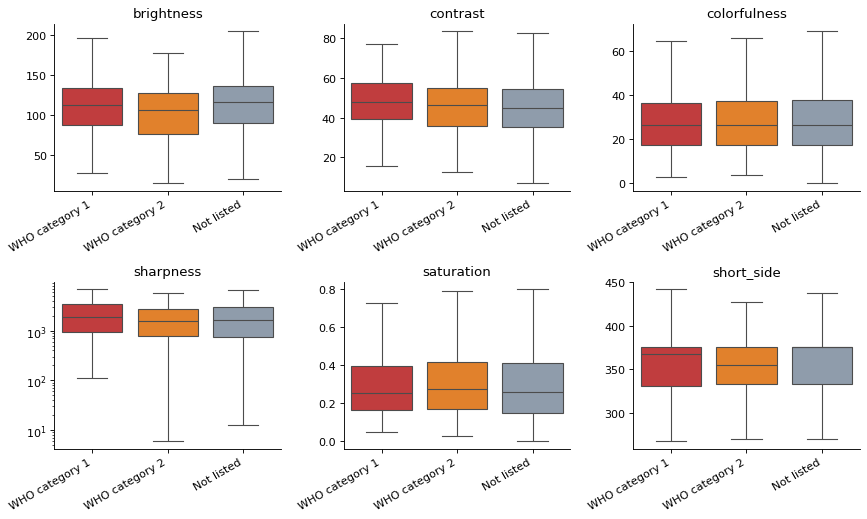

who_label,Not listed,WHO category 1,WHO category 2,p (Kruskal-Wallis)
brightness,116.468,112.170,105.823,0.000
contrast,44.778,47.634,46.168,0.007
colorfulness,26.457,26.563,26.487,0.823
sharpness,1633.714,1846.055,1570.149,0.090
saturation,0.258,0.252,0.272,0.510
short_side,375.000,367.000,355.000,0.620


In [123]:
img_who_order = [WHO_LABEL[k] for k in ["1", "2", "not_listed"]]
img_who_palette = {WHO_LABEL[k]: v for k, v in WHO_COLORS.items()}
img_box_grid("who_label", img_who_order, img_who_palette, IMG_COLS, (2, 3), "img_by_who")
img_median_table("who_label")

#### By split

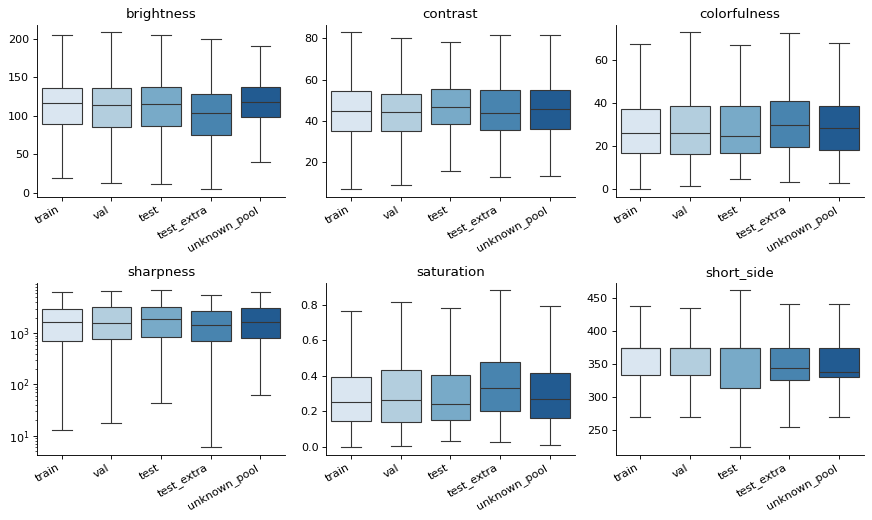

{'train': 4402, 'val': 911, 'test': 405, 'test_extra': 410, 'unknown_pool': 656}


split,test,test_extra,train,unknown_pool,val,p (Kruskal-Wallis)
brightness,115.459,104.006,116.904,118.158,114.067,0.000
contrast,46.676,43.681,44.893,45.857,44.116,0.031
colorfulness,24.551,29.844,26.150,28.365,26.001,0.000
sharpness,1929.565,1441.505,1627.634,1670.260,1567.574,0.040
saturation,0.242,0.331,0.253,0.267,0.263,0.000
short_side,375.000,344.500,375.000,337.500,374.000,0.027


In [124]:
img_split_order = [s for s in SPLIT_ORDER if s in set(quality["split"])]
img_box_grid("split", img_split_order, "Blues", IMG_COLS, (2, 3), "img_by_split")
print(quality["split"].value_counts().reindex(img_split_order).to_dict())
img_median_table("split")

#### By year the photo was taken
Years up to 2014 are put in one group because there are few photos in each of them.

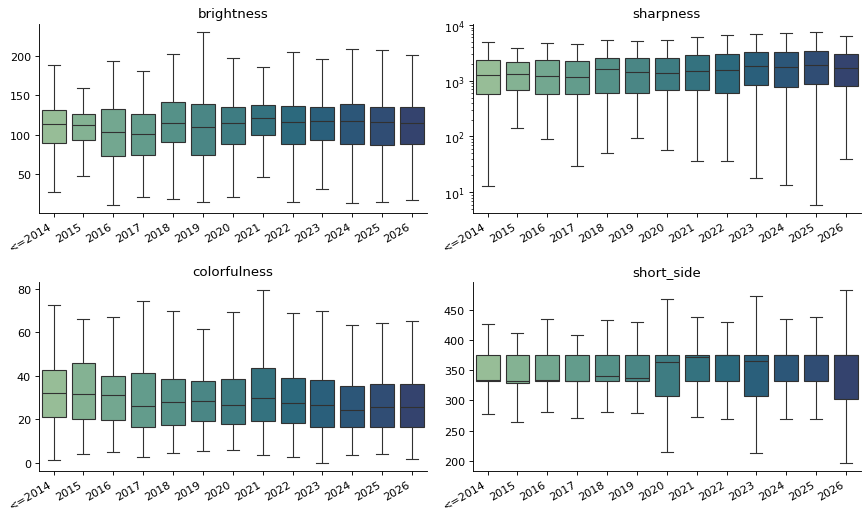

{'<=2014': 398, '2015': 103, '2016': 106, '2017': 157, '2018': 164, '2019': 236, '2020': 272, '2021': 354, '2022': 600, '2023': 829, '2024': 1104, '2025': 1169, '2026': 1292}


year_group,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,<=2014,p (Kruskal-Wallis)
brightness,111.900,103.972,101.097,115.127,110.416,115.304,121.689,116.932,117.047,117.482,115.999,115.607,113.986,0.000
contrast,43.704,41.777,40.249,42.292,43.565,43.535,42.041,45.447,47.217,44.746,46.192,45.435,42.807,0.000
colorfulness,31.460,30.996,26.165,27.718,28.342,26.370,29.548,27.309,26.591,24.135,25.430,25.669,32.144,0.000
sharpness,1335.880,1238.547,1169.508,1605.777,1426.415,1357.427,1476.936,1565.225,1842.140,1740.146,1880.583,1718.650,1259.569,0.000
saturation,0.375,0.322,0.301,0.302,0.274,0.276,0.296,0.270,0.246,0.244,0.242,0.236,0.334,0.000
short_side,333.000,334.000,333.000,340.500,337.000,363.500,372.000,375.000,366.000,375.000,375.000,375.000,334.000,0.001


In [125]:
img_years = ["<=2014"] + [str(y) for y in range(2015, 2027)]
img_year_order = [y for y in img_years if y in set(img_plot["year_group"])]
img_box_grid("year_group", img_year_order, "crest", ["brightness", "sharpness", "colorfulness", "short_side"], (2, 2), "img_by_year")
print(img_plot["year_group"].value_counts().reindex(img_year_order).to_dict())
img_median_table("year_group")

### 5.9 Photos with faces
Photos where someone holds the snake are a problem for a classifier, because the person is not the label. A face detector can also fire on patterns that only look like a face, so a count is a rough flag. This chart counts every sampled photo. Photos with a detected face are not shown as thumbnails anywhere in this notebook.

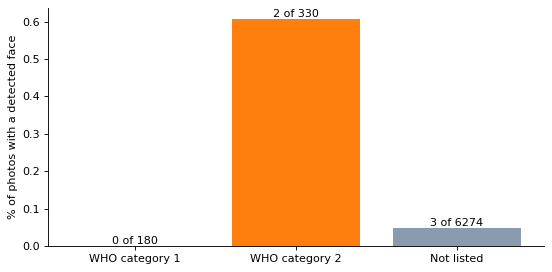

0.1% of the sampled photos have at least one detected face (yunet)


In [126]:
img_faces = quality.assign(has_face=quality["face_count"] > 0).groupby("who_category")["has_face"].agg(["mean", "sum", "size"])
img_faces = img_faces.reindex(["1", "2", "not_listed"])
fig, ax = plt.subplots(figsize=(7, 3.5), dpi=80)
ax.bar([WHO_LABEL[k] for k in img_faces.index], img_faces["mean"] * 100, color=[WHO_COLORS[k] for k in img_faces.index])
for i, (share, hits, total) in enumerate(zip(img_faces["mean"], img_faces["sum"], img_faces["size"])):
    ax.text(i, share * 100, f"{hits:.0f} of {total:.0f}", ha="center", va="bottom")
ax.set(ylabel="% of photos with a detected face")
savefig("img_faces_by_who")
plt.close()
print(f"{(quality['face_count'] > 0).mean():.1%} of the sampled photos have at least one detected face ({img_face_method})")

### 5.10 Outliers
First the numbers for the most extreme photos of the whole sample, including the photos with most faces. Only photos with a CC0 or CC BY licence can be shown, and photos with a detected face are never shown, so the thumbnails after this table are the most extreme of the photos that can be shown.

In [127]:
img_extremes = pd.concat([
    quality.nsmallest(3, "brightness").assign(why="darkest"),
    quality.nlargest(3, "brightness").assign(why="brightest"),
    quality.nsmallest(3, "sharpness").assign(why="blurriest"),
    quality.nlargest(3, "face_count").assign(why="most faces"),
])
img_extremes[["why", "photo_id", "species", "license", "brightness", "sharpness", "face_count"]].round(1).reset_index(drop=True)

,why,photo_id,species,license,brightness,sharpness,face_count
0,darkest,330764418,Xenopeltis unicolor,cc-by-nc,0.9,17.8,0
1,darkest,126905602,Craspedocephalus peltopelor,cc-by,1.1,12.8,0
2,darkest,684722145,Dendrelaphis tristis,cc-by-nc,2.7,39.4,0
3,brightest,112964644,Pseudoindotyphlops porrectus,cc-by-nc,241.4,672.5,0
4,brightest,45411163,Uropeltis ceylanica,all-rights-reserved,238.1,476.3,0
5,brightest,273261793,Ahaetulla malabarica,cc-by-nc,235.6,671.7,0
6,blurriest,610393202,Bungarus sindanus,cc-by-nc,94.5,6.0,0
7,blurriest,126905602,Craspedocephalus peltopelor,cc-by,1.1,12.8,0
8,blurriest,424181097,Ahaetulla borealis,all-rights-reserved,16.1,13.3,0
9,most faces,600535809,Laticauda colubrina,all-rights-reserved,71.4,1170.6,1


#### Helpers for the picture grids
Pictures are small JPEG thumbnails (quality 70, at most 224 px wide) stitched into one grid per figure, so the notebook stays small. All photos come from the measured sample, so we know their face count. `img_pick` takes CC0 and CC BY photos without a detected face first, then CC BY-NC without a face, and only if there are still too few does it use photos with a face.

In [128]:
IMG_OK = ["cc0", "cc-by", "cc-by-nc"]
img_pool = quality[quality["license"].isin(IMG_OK)]
print(f"{len(img_pool):,} sampled photos with a licence we can show, {(img_pool['face_count'] == 0).sum():,} without a detected face")

4,325 sampled photos with a licence we can show, 4,321 without a detected face


In [129]:
def img_tier(d, n, order, shift):
    if order is None:
        d = d.sample(frac=1, random_state=SEED + shift)
        d = d.assign(r=d.groupby("species").cumcount()).sort_values("r", kind="stable")
    else:
        d = d.sort_values(order[0], ascending=order[1])
    return d.head(max(n, 0))

def img_pick(df, n, order=None, shift=0):
    got = []
    for faces in (False, True):
        for tier in (["cc0", "cc-by"], ["cc-by-nc"]):
            part = df[df["license"].isin(tier) & ((df["face_count"] > 0) == faces)]
            got.append(img_tier(part, n - sum(map(len, got)), order, shift))
    return pd.concat(got)

In [130]:
IMG_WHO_TEXT = {"1": "WHO 1", "2": "WHO 2", "not_listed": "not listed"}

def img_label(rows, prefix=""):
    return rows.assign(label=[f"{prefix}{i}" for i in range(1, len(rows) + 1)])

def img_short(name):
    genus, *rest = name.split()
    return f"{genus[0]}. {' '.join(rest)}"

def img_entries(rows, col=None, pad=4):
    tail = (lambda r: IMG_WHO_TEXT[r.who_category]) if col is None else (lambda r: f"{getattr(r, col):.0f}")
    out = [(r.path, f"{r.label}. {img_short(r.species)} | {tail(r)}") for r in rows.itertuples()]
    return out + [None] * (-len(out) % pad)

In [131]:
try:
    IMG_FONT = ImageFont.load_default(size=12)
except (TypeError, OSError):
    IMG_FONT = ImageFont.load_default()

def img_tile(entry, w=224, h=186):
    tile = Image.new("RGB", (w, h + 16), (238, 238, 238))
    if entry is not None:
        try:
            pic = (entry[0] if isinstance(entry[0], Image.Image) else Image.open(img_file(entry[0]))).convert("RGB")
            pic.thumbnail((w - 4, h - 4))
            tile.paste(pic, ((w - pic.width) // 2, (h - pic.height) // 2))
        except Exception:
            pass
        ImageDraw.Draw(tile).text((3, h + 2), entry[1], fill=(20, 20, 20), font=IMG_FONT)
    return tile

In [132]:
IMG_BYTES = []

def img_grid(entries, cols=4):
    tiles = [img_tile(e) for e in entries]
    w, h = tiles[0].size
    sheet = Image.new("RGB", (cols * w, -(-len(tiles) // cols) * h), (238, 238, 238))
    for i, tile in enumerate(tiles):
        sheet.paste(tile, (i % cols * w, i // cols * h))
    return sheet

def img_show(sheet):
    buf = io.BytesIO()
    sheet.save(buf, format="JPEG", quality=70)
    IMG_BYTES.append(buf.tell())
    display(ShowImage(data=buf.getvalue(), format="jpeg", width=sheet.width))

In [133]:
def img_credits(rows, extra=()):
    table = pd.DataFrame({
        "species": rows["species"].values,
        "WHO": rows["who_category"].map(WHO_LABEL).values,
        **{c: rows[c].values for c in extra},
        "licence": rows["license"].values,
        "credit": rows["attribution"].values,
    }, index=rows["label"].values)
    with pd.option_context("display.max_colwidth", 120):
        display(table.round(2))
    if (rows["license"] == "cc-by-nc").any():
        print("note: too few CC0 / CC BY photos here, so some CC BY-NC photos were added (marked in the licence column)")
    if (rows["face_count"] > 0).any():
        print("note: too few photos without a detected face here, so some photos with a face are shown")

The outliers, four per row: darkest (brightness), brightest (brightness) and blurriest (sharpness) of the photos that can be shown. The number after the species is the value of that measure.

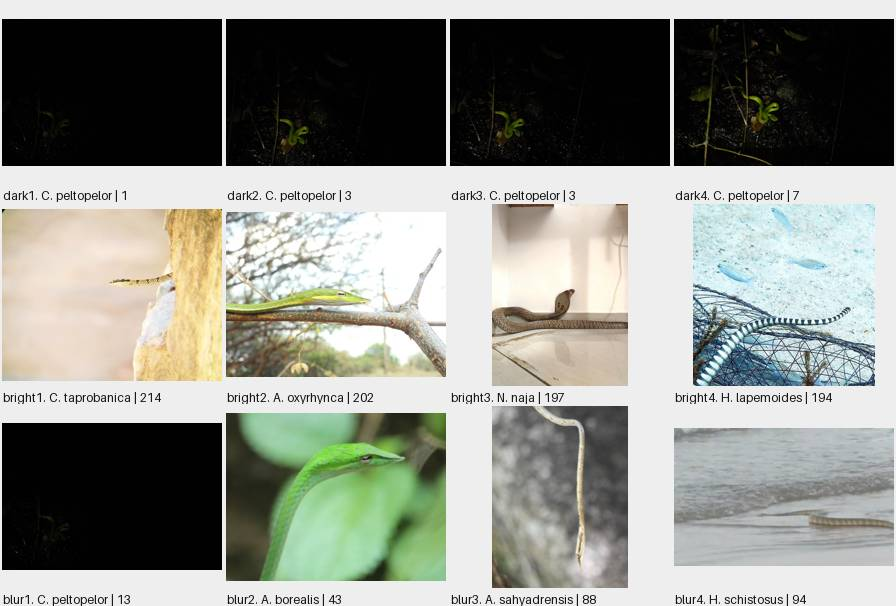

,species,WHO,licence,credit
dark1,Craspedocephalus peltopelor,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
dark2,Craspedocephalus peltopelor,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
dark3,Craspedocephalus peltopelor,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
dark4,Craspedocephalus peltopelor,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
bright1,Chrysopelea taprobanica,Not listed,cc-by,"(c) Viral joshi, some rights reserved (CC BY)"
bright2,Ahaetulla oxyrhynca,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
bright3,Naja naja,WHO category 1,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
bright4,Hydrophis lapemoides,Not listed,cc-by,"(c) Robin White, some rights reserved (CC BY)"
blur1,Craspedocephalus peltopelor,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
blur2,Ahaetulla borealis,Not listed,cc0,no rights reserved


In [134]:
img_specs = [("dark", "brightness", True), ("bright", "brightness", False), ("blur", "sharpness", True)]
img_groups = [img_label(img_pick(img_pool, 4, (col, asc)), name) for name, col, asc in img_specs]
img_show(img_grid(sum([img_entries(g, col) for g, (name, col, asc) in zip(img_groups, img_specs)], [])))
img_credits(pd.concat(img_groups))

### 5.11 A look at the photos
Pictures say more than numbers. These come from the sample, CC0 and CC BY first, one photo per species until we run out of species.

**WHO category 1**

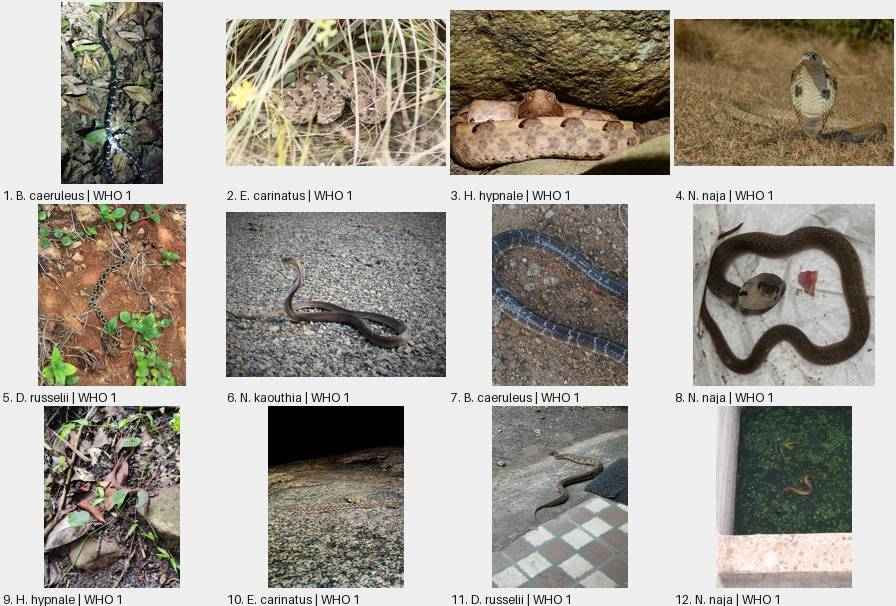

,species,WHO,licence,credit
1,Bungarus caeruleus,WHO category 1,cc-by,"(c) Harsha Jayaramaiah, some rights reserved (CC BY)"
2,Echis carinatus,WHO category 1,cc-by,"(c) Ramesh Shenai, some rights reserved (CC BY)"
3,Hypnale hypnale,WHO category 1,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
4,Naja naja,WHO category 1,cc-by,"(c) Ramit Singal, some rights reserved (CC BY)"
5,Daboia russelii,WHO category 1,cc-by,"(c) Aadi Kulkarni, some rights reserved (CC BY)"
6,Naja kaouthia,WHO category 1,cc-by,"(c) Utain Pummarin, some rights reserved (CC BY)"
7,Bungarus caeruleus,WHO category 1,cc-by,"(c) Pranav Chandra Bose, some rights reserved (CC BY)"
8,Naja naja,WHO category 1,cc0,no rights reserved
9,Hypnale hypnale,WHO category 1,cc-by,"(c) Ashwin Viswanathan, some rights reserved (CC BY)"
10,Echis carinatus,WHO category 1,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"


**WHO category 2**

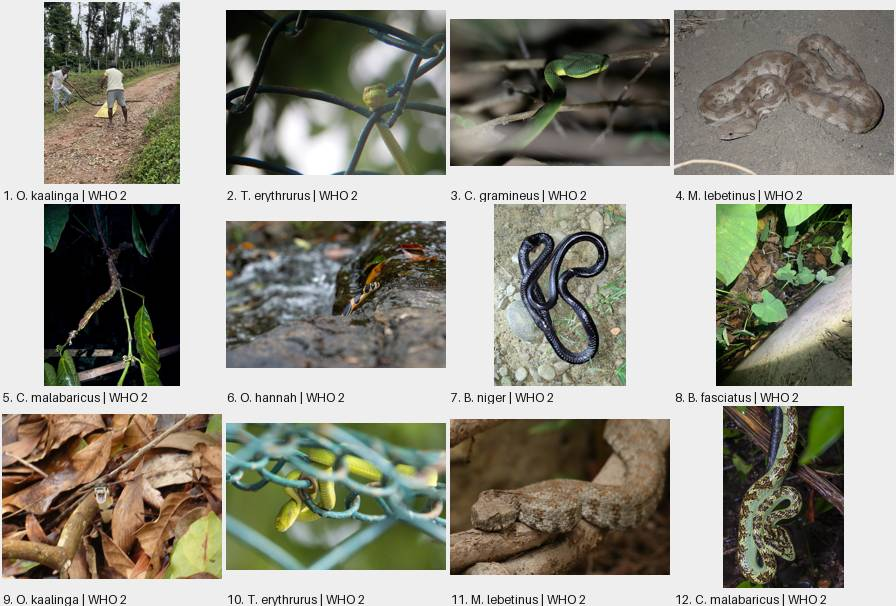

,species,WHO,licence,credit
1,Ophiophagus kaalinga,WHO category 2,cc0,no rights reserved
2,Trimeresurus erythrurus,WHO category 2,cc-by,"(c) Jigu, some rights reserved (CC BY)"
3,Craspedocephalus gramineus,WHO category 2,cc-by,"(c) Tom Field, some rights reserved (CC BY)"
4,Macrovipera lebetinus,WHO category 2,cc-by,"(c) Kian, some rights reserved (CC BY)"
5,Craspedocephalus malabaricus,WHO category 2,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
6,Ophiophagus hannah,WHO category 2,cc-by,"(c) Lawrence Hylton, some rights reserved (CC BY)"
7,Bungarus niger,WHO category 2,cc0,no rights reserved
8,Bungarus fasciatus,WHO category 2,cc-by,"(c) 灯管儿, some rights reserved (CC BY)"
9,Ophiophagus kaalinga,WHO category 2,cc-by,"(c) Ashwin Viswanathan, some rights reserved (CC BY)"
10,Trimeresurus erythrurus,WHO category 2,cc-by,"(c) Ramesh Shenai, some rights reserved (CC BY)"


**Not listed**

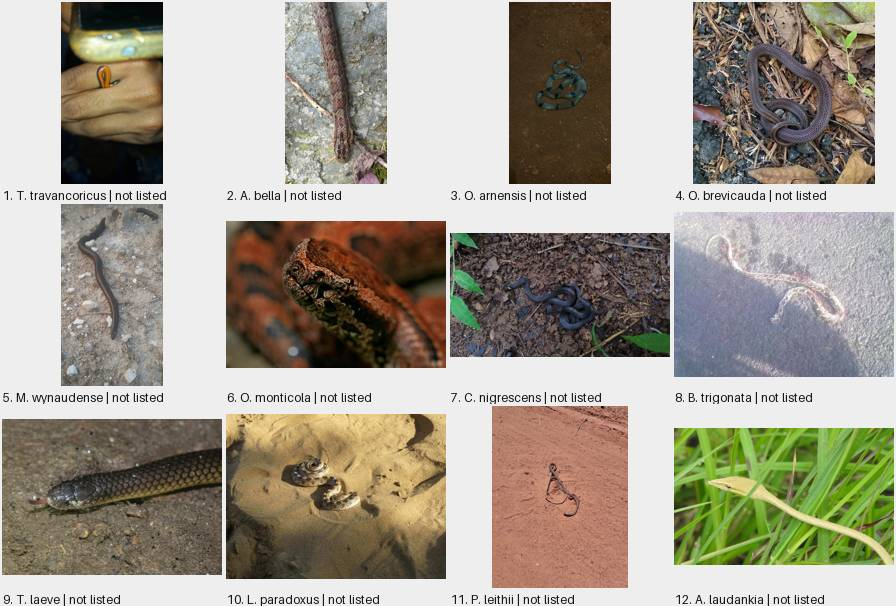

,species,WHO,licence,credit
1,Teretrurus travancoricus,Not listed,cc-by,"(c) Ronith Urs, some rights reserved (CC BY)"
2,Archelaphe bella,Not listed,cc-by,"(c) Harsha Jayaramaiah, some rights reserved (CC BY)"
3,Oligodon arnensis,Not listed,cc-by,"(c) Ronith Urs, some rights reserved (CC BY)"
4,Oligodon brevicauda,Not listed,cc-by,"(c) Karthik Thrikkadeeri, some rights reserved (CC BY)"
5,Melanophidium wynaudense,Not listed,cc-by,"(c) Kishore, some rights reserved (CC BY)"
6,Ovophis monticola,Not listed,cc0,no rights reserved
7,Calliophis nigrescens,Not listed,cc-by,"(c) Manu M, some rights reserved (CC BY)"
8,Boiga trigonata,Not listed,cc-by,"(c) Viral joshi, some rights reserved (CC BY)"
9,Trachischium laeve,Not listed,cc-by,"(c) Ramnarayan K, some rights reserved (CC BY)"
10,Lytorhynchus paradoxus,Not listed,cc-by,"(c) Mittal Gala, some rights reserved (CC BY)"


In [135]:
def img_category_grid(cat):
    rows = img_label(img_pick(img_pool[img_pool["who_category"] == cat], 12))
    display(Markdown(f"**{WHO_LABEL[cat]}**"))
    img_show(img_grid(img_entries(rows)))
    img_credits(rows)

for cat in ["1", "2", "not_listed"]:
    img_category_grid(cat)

#### Sharpest and blurriest photos
Sharpness is measured on the photos in the sample, and the number after the species is the sharpness. Let's see what a high and a low value really look like: a high Laplacian variance can also come from a busy background, so it is not automatically a well-focused snake.

**Sharpest photos**

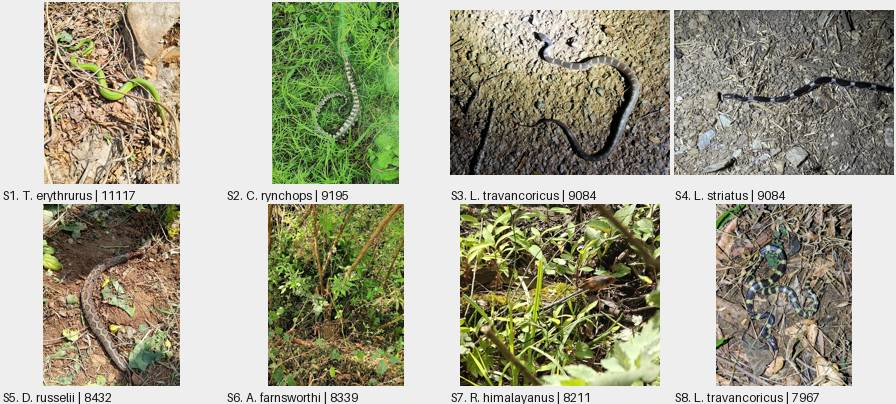

,species,WHO,licence,credit
S1,Trimeresurus erythrurus,WHO category 2,cc-by,"(c) Ankur Nandi, some rights reserved (CC BY)"
S2,Cerberus rynchops,Not listed,cc-by,"(c) Afsar Nayakkan, some rights reserved (CC BY)"
S3,Lycodon travancoricus,Not listed,cc-by,"(c) Rohit Naniwadekar, some rights reserved (CC BY)"
S4,Lycodon striatus,Not listed,cc-by,"(c) Teja Yantrapalli, some rights reserved (CC BY)"
S5,Daboia russelii,WHO category 1,cc-by,"(c) parithi, some rights reserved (CC BY)"
S6,Ahaetulla farnsworthi,Not listed,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
S7,Rhabdophis himalayanus,Not listed,cc-by,"(c) Jigu, some rights reserved (CC BY)"
S8,Lycodon travancoricus,Not listed,cc-by,"(c) Paulmathi Vinod, some rights reserved (CC BY)"


**Blurriest photos**

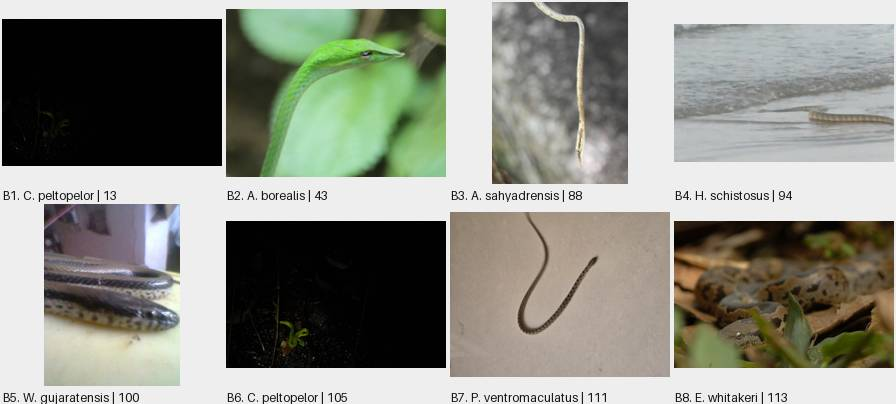

,species,WHO,licence,credit
B1,Craspedocephalus peltopelor,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
B2,Ahaetulla borealis,Not listed,cc0,no rights reserved
B3,Ahaetulla sahyadrensis,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
B4,Hydrophis schistosus,Not listed,cc-by,"(c) Surabhi Srivastava, some rights reserved (CC BY)"
B5,Wallaceophis gujaratensis,Not listed,cc-by,"(c) Viral joshi, some rights reserved (CC BY)"
B6,Craspedocephalus peltopelor,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
B7,Platyceps ventromaculatus,Not listed,cc-by,"(c) Abhinav Thakur, some rights reserved (CC BY)"
B8,Eryx whitakeri,Not listed,cc-by,"(c) kalyanvarma, some rights reserved (CC BY)"


In [136]:
for tag, asc, text in [("S", False, "Sharpest photos"), ("B", True, "Blurriest photos")]:
    rows = img_label(img_pick(img_pool, 8, ("sharpness", asc)), tag)
    display(Markdown(f"**{text}**"))
    img_show(img_grid(img_entries(rows, "sharpness")))
    img_credits(rows)

#### Lookalike pairs
Dangerous species on the top row (D1 to D4), the harmless species they get mixed up with on the bottom row (H1 to H4). The caption shows the WHO category. If a species has no usable photo in the sample, the pair is skipped with a note.

In [137]:
def img_pair(top_sp, bottom_sp, text, shift=0, tags="DH"):
    top = img_label(img_pick(img_pool[img_pool["species"] == top_sp], 4, None, shift), tags[0])
    bottom = img_label(img_pick(img_pool[img_pool["species"] == bottom_sp], 4, None, shift), tags[1])
    if top.empty or bottom.empty:
        print(f"skipped {top_sp} / {bottom_sp}: no usable photo for one of them")
        return
    display(Markdown(f"**{top_sp}** (WHO {who_of[top_sp]}) on top, **{bottom_sp}** (WHO {who_of[bottom_sp]}) below: {text}"))
    img_show(img_grid(img_entries(top) + img_entries(bottom)))
    img_credits(pd.concat([top, bottom]))

**Naja naja** (WHO 1) on top, **Ptyas mucosa** (WHO not_listed) below: spectacled cobra and oriental rat snake

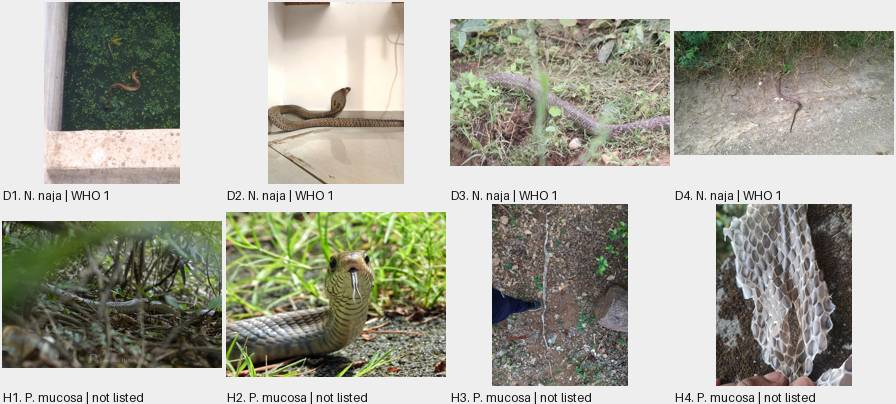

,species,WHO,licence,credit
D1,Naja naja,WHO category 1,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
D2,Naja naja,WHO category 1,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
D3,Naja naja,WHO category 1,cc0,no rights reserved
D4,Naja naja,WHO category 1,cc-by,"(c) Viral joshi, some rights reserved (CC BY)"
H1,Ptyas mucosa,Not listed,cc-by,"(c) Lawrence Hylton, some rights reserved (CC BY)"
H2,Ptyas mucosa,Not listed,cc-by,"(c) 卢江离, some rights reserved (CC BY)"
H3,Ptyas mucosa,Not listed,cc-by,"(c) Swarochi Tathagath, some rights reserved (CC BY)"
H4,Ptyas mucosa,Not listed,cc-by,"(c) Navaneeth Sini George, some rights reserved (CC BY)"


**Bungarus caeruleus** (WHO 1) on top, **Lycodon aulicus** (WHO not_listed) below: common krait and Indian wolf snake

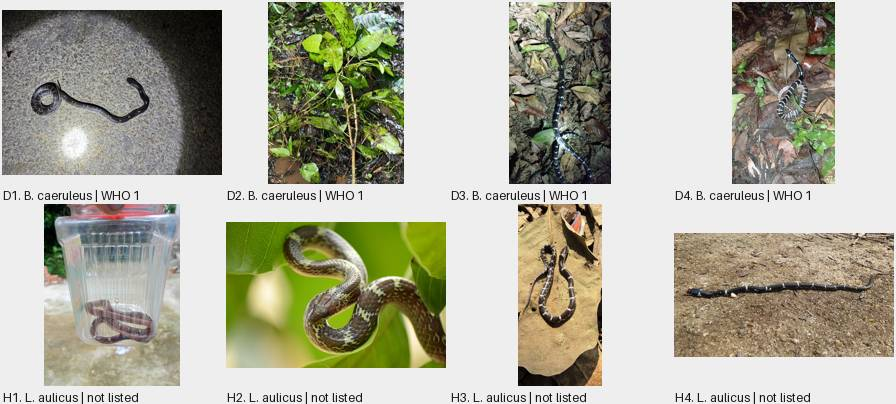

,species,WHO,licence,credit
D1,Bungarus caeruleus,WHO category 1,cc-by,"(c) Teja Yantrapalli, some rights reserved (CC BY)"
D2,Bungarus caeruleus,WHO category 1,cc-by,"(c) Ashwin A, some rights reserved (CC BY)"
D3,Bungarus caeruleus,WHO category 1,cc-by,"(c) Harsha Jayaramaiah, some rights reserved (CC BY)"
D4,Bungarus caeruleus,WHO category 1,cc-by,"(c) wildlife photography, some rights reserved (CC BY)"
H1,Lycodon aulicus,Not listed,cc-by,"(c) HM Emon, some rights reserved (CC BY)"
H2,Lycodon aulicus,Not listed,cc-by,"(c) Harshjeet Singh Bal, some rights reserved (CC BY)"
H3,Lycodon aulicus,Not listed,cc-by-nc,"(c) Rajendra Kamble, some rights reserved (CC BY-NC)"
H4,Lycodon aulicus,Not listed,cc-by-nc,"(c) karle pranav, some rights reserved (CC BY-NC)"


note: too few CC0 / CC BY photos here, so some CC BY-NC photos were added (marked in the licence column)


**Bungarus caeruleus** (WHO 1) on top, **Lycodon travancoricus** (WHO not_listed) below: common krait and Travancore wolf snake

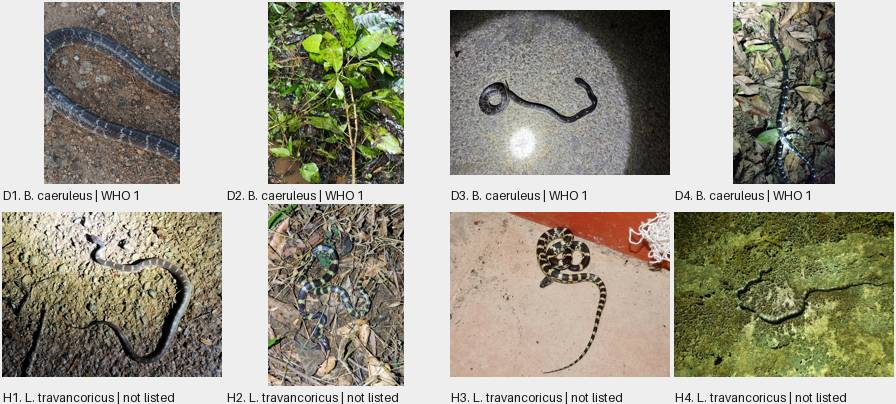

,species,WHO,licence,credit
D1,Bungarus caeruleus,WHO category 1,cc-by,"(c) Pranav Chandra Bose, some rights reserved (CC BY)"
D2,Bungarus caeruleus,WHO category 1,cc-by,"(c) Ashwin A, some rights reserved (CC BY)"
D3,Bungarus caeruleus,WHO category 1,cc-by,"(c) Teja Yantrapalli, some rights reserved (CC BY)"
D4,Bungarus caeruleus,WHO category 1,cc-by,"(c) Harsha Jayaramaiah, some rights reserved (CC BY)"
H1,Lycodon travancoricus,Not listed,cc-by,"(c) Rohit Naniwadekar, some rights reserved (CC BY)"
H2,Lycodon travancoricus,Not listed,cc-by,"(c) Paulmathi Vinod, some rights reserved (CC BY)"
H3,Lycodon travancoricus,Not listed,cc-by,"(c) Seema Merchant, some rights reserved (CC BY)"
H4,Lycodon travancoricus,Not listed,cc-by,"(c) Siya ul haque, some rights reserved (CC BY)"


**Bungarus caeruleus** (WHO 1) on top, **Lycodon fasciolatus** (WHO not_listed) below: common krait and Russell's wolf snake

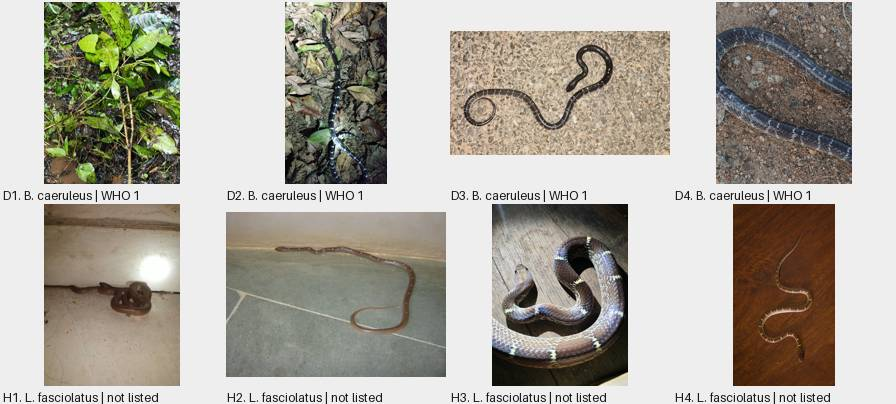

,species,WHO,licence,credit
D1,Bungarus caeruleus,WHO category 1,cc-by,"(c) Ashwin A, some rights reserved (CC BY)"
D2,Bungarus caeruleus,WHO category 1,cc-by,"(c) Harsha Jayaramaiah, some rights reserved (CC BY)"
D3,Bungarus caeruleus,WHO category 1,cc-by,"(c) Neelavathi, some rights reserved (CC BY)"
D4,Bungarus caeruleus,WHO category 1,cc-by,"(c) Pranav Chandra Bose, some rights reserved (CC BY)"
H1,Lycodon fasciolatus,Not listed,cc-by,"(c) Navaneeth Sini George, some rights reserved (CC BY)"
H2,Lycodon fasciolatus,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
H3,Lycodon fasciolatus,Not listed,cc-by,"(c) Suhas Saya, some rights reserved (CC BY)"
H4,Lycodon fasciolatus,Not listed,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"


**Daboia russelii** (WHO 1) on top, **Eryx conicus** (WHO not_listed) below: Russell's viper and rough-scaled sand boa

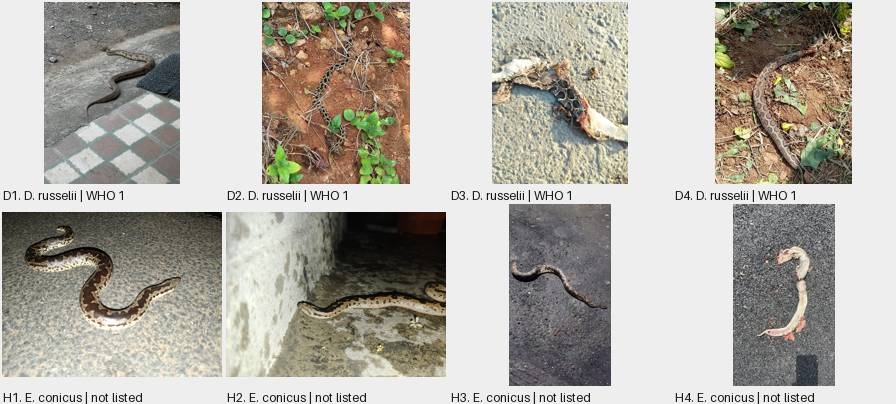

,species,WHO,licence,credit
D1,Daboia russelii,WHO category 1,cc-by,"(c) phiroza, some rights reserved (CC BY)"
D2,Daboia russelii,WHO category 1,cc-by,"(c) Aadi Kulkarni, some rights reserved (CC BY)"
D3,Daboia russelii,WHO category 1,cc-by,"(c) Aryan K, some rights reserved (CC BY)"
D4,Daboia russelii,WHO category 1,cc-by,"(c) parithi, some rights reserved (CC BY)"
H1,Eryx conicus,Not listed,cc-by,"(c) Siva Naturewild, some rights reserved (CC BY)"
H2,Eryx conicus,Not listed,cc-by-nc,"(c) jaichand, some rights reserved (CC BY-NC)"
H3,Eryx conicus,Not listed,cc-by-nc,"(c) Chandramani Jadhav, some rights reserved (CC BY-NC)"
H4,Eryx conicus,Not listed,cc-by-nc,"(c) Dhaivat Hathi, some rights reserved (CC BY-NC)"


note: too few CC0 / CC BY photos here, so some CC BY-NC photos were added (marked in the licence column)


**Daboia russelii** (WHO 1) on top, **Python molurus** (WHO not_listed) below: Russell's viper and Indian rock python

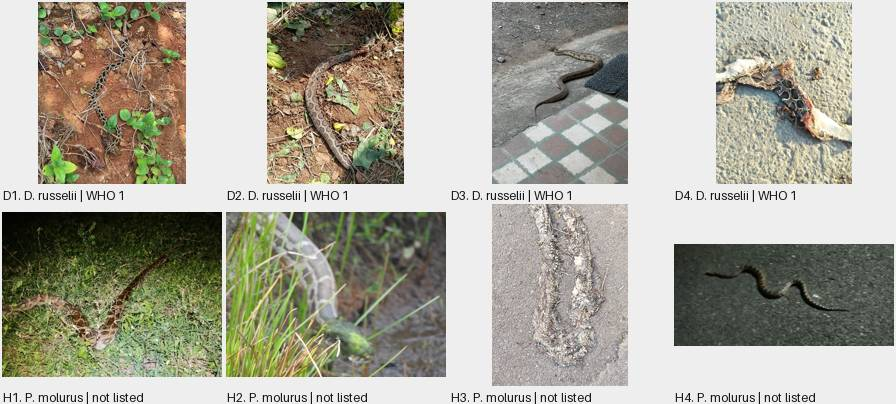

,species,WHO,licence,credit
D1,Daboia russelii,WHO category 1,cc-by,"(c) Aadi Kulkarni, some rights reserved (CC BY)"
D2,Daboia russelii,WHO category 1,cc-by,"(c) parithi, some rights reserved (CC BY)"
D3,Daboia russelii,WHO category 1,cc-by,"(c) phiroza, some rights reserved (CC BY)"
D4,Daboia russelii,WHO category 1,cc-by,"(c) Aryan K, some rights reserved (CC BY)"
H1,Python molurus,Not listed,cc-by,"(c) Suhas Saya, some rights reserved (CC BY)"
H2,Python molurus,Not listed,cc-by-nc,"(c) karle pranav, some rights reserved (CC BY-NC)"
H3,Python molurus,Not listed,cc-by-nc,"(c) Bikash Kumar Sahoo, some rights reserved (CC BY-NC)"
H4,Python molurus,Not listed,cc-by-nc,"(c) Russell Cardozo, some rights reserved (CC BY-NC)"


note: too few CC0 / CC BY photos here, so some CC BY-NC photos were added (marked in the licence column)


**Echis carinatus** (WHO 1) on top, **Boiga trigonata** (WHO not_listed) below: saw-scaled viper and common cat snake

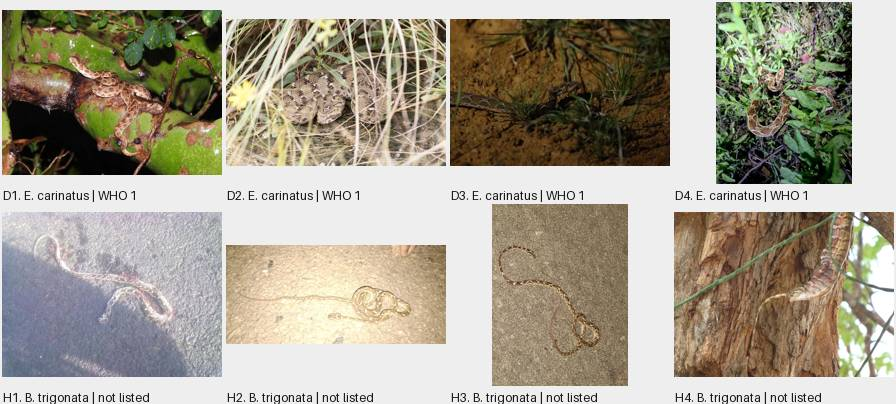

,species,WHO,licence,credit
D1,Echis carinatus,WHO category 1,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
D2,Echis carinatus,WHO category 1,cc-by,"(c) Ramesh Shenai, some rights reserved (CC BY)"
D3,Echis carinatus,WHO category 1,cc-by,"(c) Teja Yantrapalli, some rights reserved (CC BY)"
D4,Echis carinatus,WHO category 1,cc-by,"(c) Ashwin Viswanathan, some rights reserved (CC BY)"
H1,Boiga trigonata,Not listed,cc-by,"(c) Viral joshi, some rights reserved (CC BY)"
H2,Boiga trigonata,Not listed,cc-by-nc,"(c) Dr. Chinmay kishor Pathak, some rights reserved (CC BY-NC)"
H3,Boiga trigonata,Not listed,cc-by-nc,"(c) Harshil Mehta, some rights reserved (CC BY-NC)"
H4,Boiga trigonata,Not listed,cc-by-nc,"(c) Avinash Hindupur, some rights reserved (CC BY-NC)"


note: too few CC0 / CC BY photos here, so some CC BY-NC photos were added (marked in the licence column)


**Naja naja** (WHO 1) on top, **Fowlea piscator** (WHO not_listed) below: spectacled cobra and checkered keelback

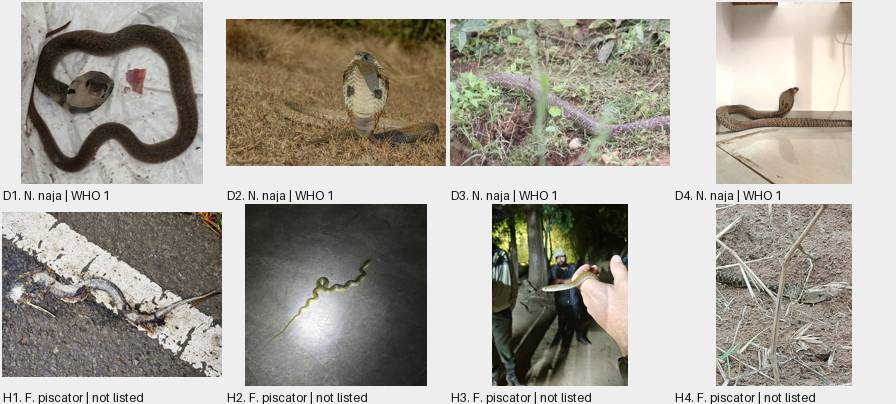

,species,WHO,licence,credit
D1,Naja naja,WHO category 1,cc0,no rights reserved
D2,Naja naja,WHO category 1,cc-by,"(c) Ramit Singal, some rights reserved (CC BY)"
D3,Naja naja,WHO category 1,cc0,no rights reserved
D4,Naja naja,WHO category 1,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
H1,Fowlea piscator,Not listed,cc-by,"(c) renjus box, some rights reserved (CC BY)"
H2,Fowlea piscator,Not listed,cc-by-nc,"(c) Adwaitha G, some rights reserved (CC BY-NC)"
H3,Fowlea piscator,Not listed,cc-by-nc,"(c) Rahul, some rights reserved (CC BY-NC)"
H4,Fowlea piscator,Not listed,cc-by-nc,"(c) simply789, some rights reserved (CC BY-NC)"


note: too few CC0 / CC BY photos here, so some CC BY-NC photos were added (marked in the licence column)


**Craspedocephalus gramineus** (WHO 2) on top, **Rhabdophis plumbicolor** (WHO not_listed) below: bamboo pit viper and green keelback

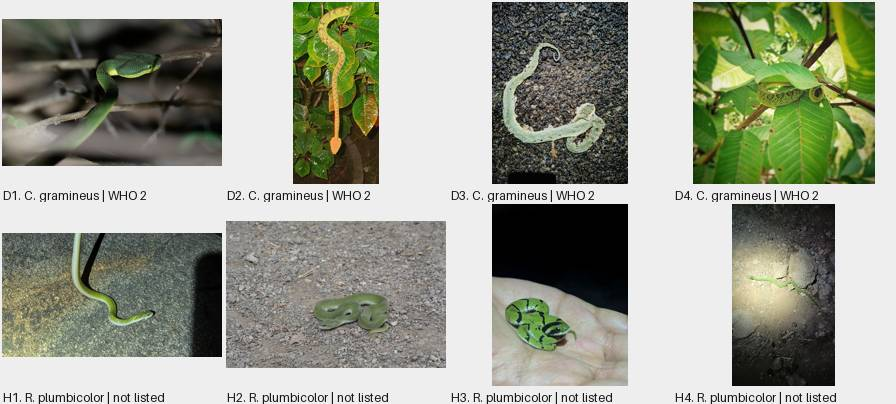

,species,WHO,licence,credit
D1,Craspedocephalus gramineus,WHO category 2,cc-by,"(c) Tom Field, some rights reserved (CC BY)"
D2,Craspedocephalus gramineus,WHO category 2,cc-by-nc,"(c) Ravi Naidu, some rights reserved (CC BY-NC)"
D3,Craspedocephalus gramineus,WHO category 2,cc-by-nc,"(c) Ashit Parida, some rights reserved (CC BY-NC)"
D4,Craspedocephalus gramineus,WHO category 2,cc-by-nc,"(c) avinashnair75, some rights reserved (CC BY-NC)"
H1,Rhabdophis plumbicolor,Not listed,cc-by,"(c) Tom Field, some rights reserved (CC BY)"
H2,Rhabdophis plumbicolor,Not listed,cc-by-nc,"(c) Aakash Raut, some rights reserved (CC BY-NC)"
H3,Rhabdophis plumbicolor,Not listed,cc-by-nc,"(c) Chayant Gonsalves, some rights reserved (CC BY-NC)"
H4,Rhabdophis plumbicolor,Not listed,cc-by-nc,"(c) Dr. Chinmay kishor Pathak, some rights reserved (CC BY-NC)"


note: too few CC0 / CC BY photos here, so some CC BY-NC photos were added (marked in the licence column)


In [138]:
for k, (dang, harm, text) in enumerate(LOOKALIKES):
    img_pair(dang, harm, text, k)

Two pairs where both species are dangerous (A on top, B below). Here the question is whether the two can still be told apart by eye.

**Hypnale hypnale** (WHO 1) on top, **Craspedocephalus malabaricus** (WHO 2) below: hump-nosed and Malabar pit viper

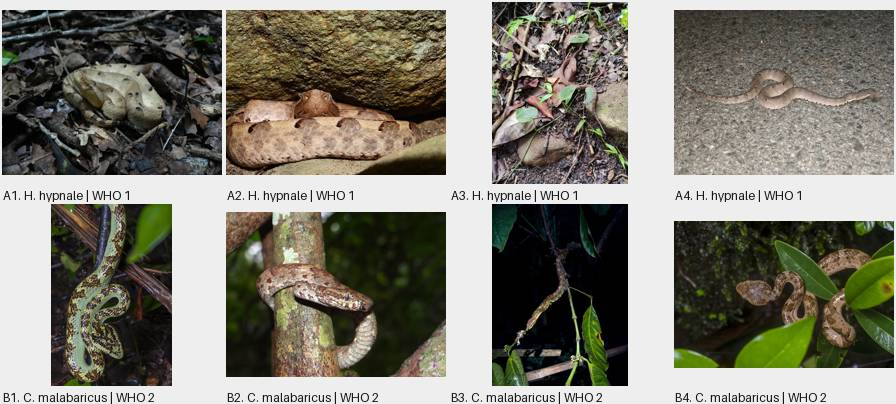

,species,WHO,licence,credit
A1,Hypnale hypnale,WHO category 1,cc-by,"(c) T R Shankar Raman, some rights reserved (CC BY)"
A2,Hypnale hypnale,WHO category 1,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
A3,Hypnale hypnale,WHO category 1,cc-by,"(c) Ashwin Viswanathan, some rights reserved (CC BY)"
A4,Hypnale hypnale,WHO category 1,cc-by,"(c) Rohit Naniwadekar, some rights reserved (CC BY)"
B1,Craspedocephalus malabaricus,WHO category 2,cc-by,"(c) Ramesh Shenai, some rights reserved (CC BY)"
B2,Craspedocephalus malabaricus,WHO category 2,cc-by,"(c) Ansil B.R., some rights reserved (CC BY)"
B3,Craspedocephalus malabaricus,WHO category 2,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
B4,Craspedocephalus malabaricus,WHO category 2,cc-by,"(c) Ramesh Shenai, some rights reserved (CC BY)"


**Hypnale hypnale** (WHO 1) on top, **Echis carinatus** (WHO 1) below: hump-nosed pit viper and saw-scaled viper

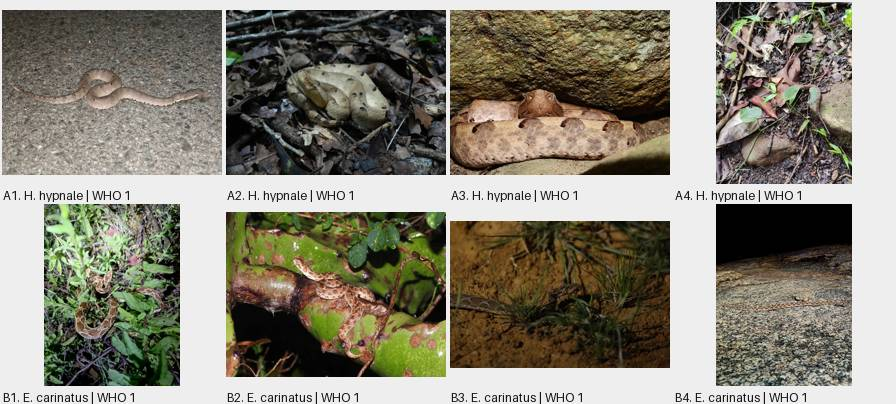

,species,WHO,licence,credit
A1,Hypnale hypnale,WHO category 1,cc-by,"(c) Rohit Naniwadekar, some rights reserved (CC BY)"
A2,Hypnale hypnale,WHO category 1,cc-by,"(c) T R Shankar Raman, some rights reserved (CC BY)"
A3,Hypnale hypnale,WHO category 1,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
A4,Hypnale hypnale,WHO category 1,cc-by,"(c) Ashwin Viswanathan, some rights reserved (CC BY)"
B1,Echis carinatus,WHO category 1,cc-by,"(c) Ashwin Viswanathan, some rights reserved (CC BY)"
B2,Echis carinatus,WHO category 1,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
B3,Echis carinatus,WHO category 1,cc-by,"(c) Teja Yantrapalli, some rights reserved (CC BY)"
B4,Echis carinatus,WHO category 1,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"


In [139]:
for k, (first, second, text) in enumerate(DANGEROUS):
    img_pair(first, second, text, k, "AB")

### 5.12 What section 5 cost
A size check on the photo grids embedded in this section, so the notebook stays small enough to open everywhere.

In [140]:
img_mb = sum(IMG_BYTES) / 1e6
check("photo grids of section 5 stay under 2.5 MB together", img_mb <= 2.5, f"{len(IMG_BYTES)} grids, {img_mb:.2f} MB")
print(f"read {len(quality):,} photos in {img_secs:.0f} s ({per_1000:.0f} s per 1,000 with 4 threads)")

PASS  photo grids of section 5 stay under 2.5 MB together  (17 grids, 1.27 MB)
read 6,784 photos in 106 s (16 s per 1,000 with 4 threads)


### 5.13 Colour channels: the numbers a model will normalise with
Before training, a model usually subtracts a mean and divides by a standard deviation for each colour channel. Those two numbers have to come from the training photos only. If val or test photos feed into them, a little of the test set leaks into the training setup.

So here the numbers are worked out on the training part of the sample, and then we look at whether val, test and test_extra are coloured the same way.

Every photo is shrunk to 128 by 128 pixels first, which keeps this fast. Shrinking hardly changes a channel mean and lowers the standard deviation a little, so these are close estimates and not final constants. For the real training run they get recomputed on the full training set.

In [141]:
def rgb_measure(row):
    try:
        pic = Image.open(img_file(row.path)).convert("RGB").resize((128, 128), Image.BILINEAR)
        arr = np.asarray(pic, dtype=np.float32) / 255
        out = {"photo_id": row.photo_id}
        out.update({f"mean_{c}": float(arr[:, :, i].mean()) for i, c in enumerate("rgb")})
        out.update({f"var_{c}": float(arr[:, :, i].var()) for i, c in enumerate("rgb")})
        return out
    except Exception as err:
        return {"photo_id": row.photo_id, "error": str(err)[:80]}

In [142]:
rgb_rows = list(quality.itertuples())
rgb_start = time.time()
with ThreadPoolExecutor(max_workers=4) as pool:
    rgb_out = list(tqdm(pool.map(rgb_measure, rgb_rows), total=len(rgb_rows), mininterval=10))
rgb_failed = sum("error" in o for o in rgb_out)
rgb_df = pd.DataFrame([o for o in rgb_out if "error" not in o]).merge(
    quality[["photo_id", "split", "who_category", "species"]], on="photo_id")
print(f"{len(rgb_df):,} photos done in {time.time() - rgb_start:.0f} s, {rgb_failed} could not be read")

100%|██████████| 6784/6784 [00:17<00:00, 387.32it/s]

6,784 photos done in 18 s, 0 could not be read


For a set of photos the mean of a channel is the average of the photo means. The variance of all pixels is the average of the variance inside each photo plus the variance of the photo means, and the standard deviation is its square root. All photos have 128 by 128 pixels now, so every photo counts the same.

In [143]:
RGB_MEAN = ["mean_r", "mean_g", "mean_b"]
RGB_VAR = ["var_r", "var_g", "var_b"]

def rgb_fit(frame):
    mean = frame[RGB_MEAN].mean().to_numpy()
    var = frame[RGB_VAR].mean().to_numpy() + frame[RGB_MEAN].var(ddof=0).to_numpy()
    return mean, np.sqrt(var)

The training row is the one to use. For comparison, the table also shows the numbers most pretrained models were trained with (the ImageNet values), which is what you get if you copy the usual defaults.

In [144]:
rgb_train = rgb_df[rgb_df["split"] == "train"]
rgb_mean, rgb_std = rgb_fit(rgb_train)
RGB_IMAGENET = (np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225]))
rgb_ref = pd.DataFrame({"train mean": rgb_mean, "ImageNet mean": RGB_IMAGENET[0],
                        "train std": rgb_std, "ImageNet std": RGB_IMAGENET[1]}, index=["red", "green", "blue"])
rgb_ref.round(3)

,train mean,ImageNet mean,train std,ImageNet std
red,0.456,0.485,0.235,0.229
green,0.439,0.456,0.224,0.224
blue,0.375,0.406,0.225,0.225


Now the same numbers for every split. The second table says how far each split sits from the training numbers, measured in training standard deviations, so a value of 0.1 means one tenth of the normal spread of that channel.

In [145]:
rgb_parts = {}
for name in SPLIT_ORDER:
    part = rgb_df[rgb_df["split"] == name]
    if len(part):
        mean, std = rgb_fit(part)
        rgb_parts[name] = [len(part), *mean, *std]
rgb_split = pd.DataFrame(rgb_parts, index=["photos", "mean R", "mean G", "mean B", "std R", "std G", "std B"]).T
rgb_split["photos"] = rgb_split["photos"].astype(int)
rgb_split.round(3)

,photos,mean R,mean G,mean B,std R,std G,std B
train,4402,0.456,0.439,0.375,0.235,0.224,0.225
val,911,0.447,0.427,0.357,0.233,0.221,0.223
test,405,0.450,0.432,0.359,0.241,0.229,0.226
test_extra,410,0.419,0.399,0.323,0.237,0.223,0.220
unknown_pool,656,0.482,0.451,0.372,0.223,0.213,0.216


In [146]:
rgb_shift = pd.DataFrame((rgb_split[["mean R", "mean G", "mean B"]].to_numpy() - rgb_mean) / rgb_std,
                         index=rgb_split.index, columns=["red", "green", "blue"])
rgb_shift.round(3)

,red,green,blue
train,0.000,0.000,0.000
val,-0.037,-0.054,-0.080
test,-0.026,-0.033,-0.069
test_extra,-0.158,-0.181,-0.231
unknown_pool,0.110,0.055,-0.013


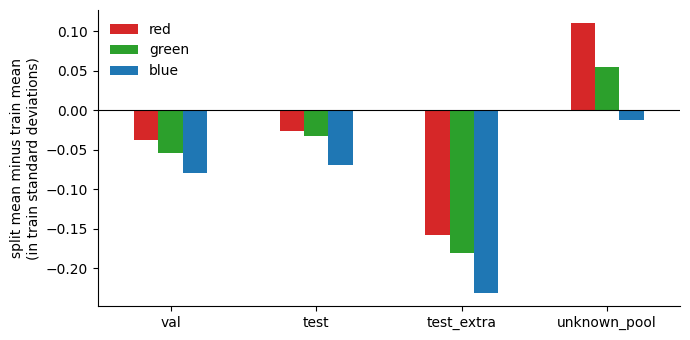

In [147]:
rgb_shift.drop(index="train").plot(kind="bar", color=["#d62728", "#2ca02c", "#1f77b4"], figsize=(7, 3.5))
plt.axhline(0, color="black", lw=0.8)
plt.ylabel("split mean minus train mean\n(in train standard deviations)")
plt.xticks(rotation=0)
plt.legend(frameon=False)
savefig("05c_rgb_shift")
plt.close()

A difference can come from chance, since each split here is only a few hundred to a few thousand photos. The Kruskal-Wallis test asks whether the photo means differ between splits more than chance would allow, the same test used in 5.8.

In [148]:
rgb_p = {c: img_kruskal([g[c] for _, g in rgb_df.groupby("split")]) for c in RGB_MEAN}
rgb_far = rgb_shift.drop(index="train").abs().stack()
print("Kruskal-Wallis p across splits:", {c[5:]: float(f"{p:.2g}") for c, p in rgb_p.items()})
print(f"largest gap to train: {rgb_far.max():.3f} train std ({rgb_far.idxmax()[0]}, {rgb_far.idxmax()[1]})")
print("train mean minus ImageNet mean:", np.round(rgb_mean - RGB_IMAGENET[0], 3).tolist())

Kruskal-Wallis p across splits: {'r': 4.4e-08, 'g': 7.4e-08, 'b': 1.8e-09}
largest gap to train: 0.231 train std (test_extra, blue)
train mean minus ImageNet mean: [-0.029, -0.017, -0.031]


In [149]:
check("a colour value exists for every photo in the sample", len(rgb_df) == len(quality), f"{rgb_failed} unreadable")
check("train channel means sit between 0 and 1 and the stds are positive", ((rgb_mean > 0) & (rgb_mean < 1) & (rgb_std > 0)).all())
check("the standard deviation of all pixels is at least the spread inside a photo", (rgb_std ** 2 >= rgb_train[RGB_VAR].mean().to_numpy()).all())

PASS  a colour value exists for every photo in the sample  (0 unreadable)
PASS  train channel means sit between 0 and 1 and the stds are positive
PASS  the standard deviation of all pixels is at least the spread inside a photo


On this sample the training photos are a little darker than the ImageNet defaults: the channel means are lower by about 0.02 to 0.03, so a model fed the ImageNet numbers would be given brighter photos than the ones it trains on. Val and test are close to train, within 0.1 of a training standard deviation. The odd split is test_extra, which is darker in all three channels (0.16 to 0.23 training standard deviations), most of all in blue, while unknown_pool leans the other way in red. The three p values are tiny, so this is not chance. For the model: normalise with the training numbers and not the ImageNet ones, and keep brightness and contrast augmentation, since test_extra is what a darker set of photos looks like.

### 5.14 Embeddings: how the photos sit next to each other
Every number so far describes one photo on its own. An embedding turns a photo into a list of numbers so that photos that look alike end up close together. That lets us ask new questions: do val and test photos sit in the same places as training photos, are there copies the picture hash missed, and which photos look unlike their own species?

The model is DINOv2 small (Apache-2.0 licence, downloaded from Hugging Face). It was trained without our labels, so it shows what the photos look like and is not tuned to our classes. Each photo is squeezed to 224 by 224 pixels whole, without cropping, so nothing at the edges is cut off.

A forward pass of the model costs only a few photos per second on a CPU, so not every photo of the sample goes in. The notebook uses the graphics card when the Kaggle session has one (the run on Kaggle took well under a minute) and falls back to the processor when it does not. The embedding uses up to 8 training photos per species and every val, test and test_extra photo of the sample, because the splits are what we want to compare. Photos of species outside the 208 classes (the unknown pool) are left out.

This part needs a download from Hugging Face. If the model cannot be loaded, for example without internet, the cells say so, the embedding cells after it do nothing, and the rest of the notebook runs as usual. The embeddings are saved to `embeddings.npz` so a second run does not have to compute them again.

In [150]:
import subprocess
import sys

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [151]:
EMB_MODEL = "facebook/dinov2-small"
EMB_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
EMB_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
EMB_TRAIN_CAP = 8
emb_all = quality[quality["split"] != "unknown_pool"]
emb_train = emb_all[emb_all["split"] == "train"].groupby("species", group_keys=False).head(EMB_TRAIN_CAP)
emb_pick = pd.concat([emb_train, emb_all[emb_all["split"] != "train"]]).merge(
    meta[["photo_id", "observer_id", "in_india"]], on="photo_id", how="left").reset_index(drop=True)
print(f"{len(emb_pick):,} photos from {emb_pick['species'].nunique()} species go into the embedding")
emb_pick["split"].value_counts()

3,390 photos from 208 species go into the embedding


split
train         1664
val            911
test_extra     410
test           405
Name: count, dtype: int64

In [152]:
def emb_load():
    try:
        if os.environ.get("EMB_OFF") == "1":
            raise ImportError("switched off with EMB_OFF=1")
        import torch
        from transformers import AutoModel
        torch.set_num_threads(os.cpu_count() or 1)
        return torch, AutoModel.from_pretrained(EMB_MODEL).eval()
    except Exception as err:
        print("could not load the model, so the embedding cells are skipped:", str(err)[:150])
        return None, None

In [153]:
emb_torch, emb_model = emb_load()
if emb_model is not None:
    print("torch", emb_torch.__version__, "| weights:", round(sum(p.numel() for p in emb_model.parameters()) / 1e6, 1), "million")

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

torch 2.11.0+cu128 | weights: 22.1 million


In [154]:
emb_dev = "cpu"
if emb_model is not None and emb_torch.cuda.is_available():
    try:
        emb_model.to("cuda")
        with emb_torch.inference_mode():
            emb_model(pixel_values=emb_torch.zeros(2, 3, 224, 224, device="cuda")).pooler_output.cpu()
        emb_dev = "cuda"
    except Exception as err:
        emb_model.to("cpu")
        print("the graphics card could not run the model, so it runs on the processor:", str(err)[:120])
print("embedding device:", emb_dev)

embedding device: cuda


In [155]:
def emb_prep(path):
    pic = Image.open(img_file(path)).convert("RGB").resize((224, 224), Image.BILINEAR)
    return ((np.asarray(pic, dtype=np.float32) / 255 - EMB_MEAN) / EMB_STD).transpose(2, 0, 1)

def emb_run(paths, batch=64):
    feats = []
    with ThreadPoolExecutor(max_workers=4) as pool:
        for i in tqdm(range(0, len(paths), batch), mininterval=15):
            x = np.stack(list(pool.map(emb_prep, paths[i:i + batch])))
            with emb_torch.inference_mode():
                x = emb_torch.from_numpy(x).to(emb_dev)
                feats.append(emb_model(pixel_values=x).pooler_output.cpu().numpy())
    return np.concatenate(feats)

In [156]:
def emb_get(ids, paths):
    cache = WORK / "embeddings.npz"
    if cache.exists():
        saved = np.load(cache)
        if saved["ids"].tolist() == ids:
            return saved["x"]
    x = emb_run(paths)
    np.savez(cache, x=x, ids=np.array(ids))
    return x

In [157]:
emb_X = None
emb_start = time.time()
if emb_model is not None:
    try:
        emb_X = emb_get(emb_pick["photo_id"].tolist(), emb_pick["path"].tolist())
    except Exception as err:
        print("the embedding run stopped:", str(err)[:150])
EMB_OK = emb_X is not None
if EMB_OK:
    print(f"{emb_X.shape[0]:,} photos x {emb_X.shape[1]} numbers each, {time.time() - emb_start:.0f} s")

100%|██████████| 53/53 [00:23<00:00,  2.27it/s]

3,390 photos x 384 numbers each, 23 s


In [158]:
check("the embeddings could be computed", EMB_OK)
if EMB_OK:
    check("one finite row of numbers per photo", emb_X.shape[0] == len(emb_pick) and bool(np.isfinite(emb_X).all()))

PASS  the embeddings could be computed
PASS  one finite row of numbers per photo


#### PCA and t-SNE
A photo is 384 numbers, which cannot be drawn. PCA keeps the directions along which the photos differ most. t-SNE then squeezes those into two axes so that neighbours stay neighbours. Distances between far-apart blobs mean little, but a blob is a group of photos that look alike.

In [159]:
if EMB_OK:
    emb_Xn = emb_X / np.linalg.norm(emb_X, axis=1, keepdims=True)
    emb_pca = PCA(50, random_state=SEED).fit(emb_Xn)
    emb_Z = emb_pca.transform(emb_Xn)
    emb_var = emb_pca.explained_variance_ratio_
    print(f"2 components keep {emb_var[:2].sum():.1%} of the spread, 10 keep {emb_var[:10].sum():.1%}, 50 keep {emb_var.sum():.1%}")

2 components keep 13.9% of the spread, 10 keep 36.5%, 50 keep 68.6%


In [160]:
emb_xy = None
if EMB_OK:
    tsne_start = time.time()
    try:
        emb_xy = TSNE(2, init="pca", perplexity=30, random_state=SEED, n_jobs=4).fit_transform(emb_Z)
        print(f"t-SNE of {len(emb_xy):,} photos took {time.time() - tsne_start:.0f} s")
    except Exception as err:
        print("t-SNE did not run, the map is skipped:", str(err)[:120])

t-SNE of 3,390 photos took 18 s


In [161]:
EMB_SPLIT = {"train": "#c8d0da", "val": "#4c78a8", "test": "#e45756", "test_extra": "#f2a900", "unknown_pool": "#7f7f7f"}
EMB_WHO = {WHO_LABEL[k]: v for k, v in WHO_COLORS.items()}

def emb_panel(ax, title, labels, colours, order):
    labels = np.asarray(labels)
    for name in order:
        hit = labels == name
        if not hit.any():
            continue
        ax.scatter(emb_xy[hit, 0], emb_xy[hit, 1], s=4, c=colours[name], label=name, alpha=0.7, linewidths=0)
    ax.set(title=title, xticks=[], yticks=[])
    ax.legend(markerscale=3, frameon=False, fontsize=8)

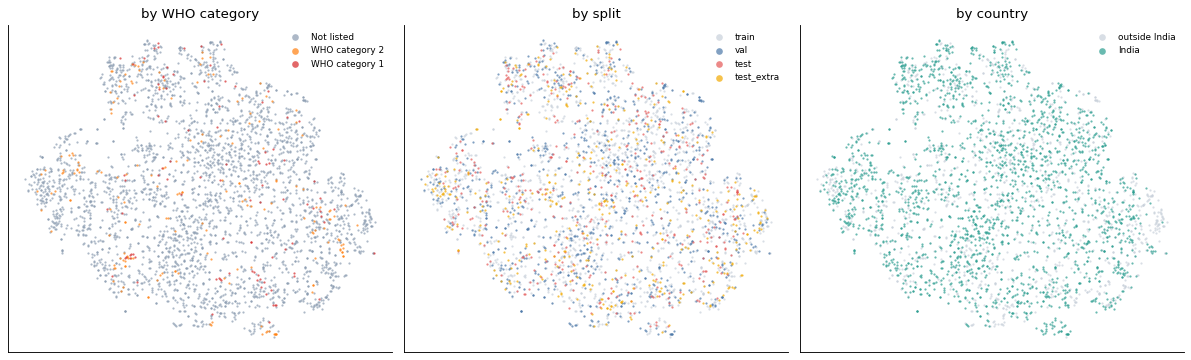

In [162]:
if emb_xy is not None:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), dpi=80)
    emb_panel(axes[0], "by WHO category", emb_pick["who_category"].map(WHO_LABEL), EMB_WHO, ["Not listed", "WHO category 2", "WHO category 1"])
    emb_panel(axes[1], "by split", emb_pick["split"], EMB_SPLIT, list(EMB_SPLIT))
    where = np.where(emb_pick["in_india"].astype(bool), "India", "outside India")
    emb_panel(axes[2], "by country", where, {"India": "#2a9d8f", "outside India": "#c8d0da"}, ["outside India", "India"])
    savefig("05d_tsne")
    plt.close()

The map is one mixed cloud. The WHO category 1 and 2 photos (red and orange) are spread through it and do not form a region of their own, and the splits overlap everywhere, which is what a fair split should look like. Photos from outside India are fewer and mostly sit among the Indian ones, with a small group at the right edge. The small tight groups are probably several photos of one species or one sighting. Only points that sit close together mean anything on a t-SNE map.

#### Do val and test look like training?
If the splits are drawn from the same kind of photo, a model should not be able to tell which split a photo came from. To test that, I train a small classifier to separate training photos from val, test and test_extra photos in turn. Its score is an AUC: 0.5 means it cannot tell them apart, 1.0 means it always can.

Two details make this fair. First, each photo's species average is subtracted, so the classifier cannot just learn that the splits contain different species and has to use what is left, such as background, camera and style. Second, the folds are grouped by photographer, so it is judged on photographers it has not seen. Val is the control: it was drawn the same way as train.

In [163]:
def emb_domain_auc(other):
    rows = emb_pick["split"].isin(["train", other]).to_numpy()
    y = (emb_pick.loc[rows, "split"] == other).astype(int).to_numpy()
    model = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=300, class_weight="balanced"))
    try:
        score = cross_val_predict(model, emb_centred[rows], y, cv=GroupKFold(5), groups=emb_group[rows], method="decision_function")
        return roc_auc_score(y, score)
    except Exception as err:
        print(f"no AUC for {other}:", str(err)[:100])
        return np.nan

In [164]:
if EMB_OK:
    emb_centred = emb_Xn - pd.DataFrame(emb_Xn).groupby(emb_pick["species"].to_numpy()).transform("mean").to_numpy()
    emb_group = pd.factorize(emb_pick["observer_id"])[0]
    emb_auc = pd.Series({s: emb_domain_auc(s) for s in ["val", "test", "test_extra"] if (emb_pick["split"] == s).sum() >= 30})
    display(emb_auc.rename("AUC against train").round(3))

val           0.542
test          0.507
test_extra    0.491
Name: AUC against train, dtype: float64

All three scores sit close to 0.5. Val, the control, scores about 0.54, and test and test_extra score about the same as the control or lower. So once the species effect is removed, this classifier cannot tell test photos from training photos, not even test_extra, which the colour numbers in 5.13 showed to be darker. The colour shift is real but small next to how much photos differ anyway. This does not prove there is no shift, only that a simple classifier on these features cannot find one.

#### Copies the picture hash missed
For every photo, find the most similar photo taken by a different photographer. A cosine similarity of 1 would be the same picture. The picture hash only catches copies that are nearly pixel-identical, the embedding also catches the same scene shot from a slightly different place.

In [165]:
def emb_neighbours(Xn, groups, step=512):
    idx = np.zeros(len(Xn), dtype=int)
    sim = np.zeros(len(Xn), dtype=np.float32)
    for i in range(0, len(Xn), step):
        block = Xn[i:i + step] @ Xn.T
        block[groups[i:i + step, None] == groups[None, :]] = -1
        idx[i:i + step], sim[i:i + step] = block.argmax(axis=1), block.max(axis=1)
    return idx, sim

In [166]:
if EMB_OK:
    emb_nn, emb_sim = emb_neighbours(emb_Xn, emb_group)
    emb_kin = emb_pick["species"].to_numpy()[emb_nn] == emb_pick["species"].to_numpy()
    print(f"the closest photo from another photographer is the same species for {emb_kin.mean():.1%} of the photos")
    print(f"similarity of that closest photo: median {np.median(emb_sim):.3f}, 99th percentile {np.quantile(emb_sim, 0.99):.3f}")
    for cut in (0.9, 0.95):
        print(f"{(emb_sim >= cut).sum():,} photos have a photo from another photographer at similarity {cut} or more")

the closest photo from another photographer is the same species for 19.1% of the photos
similarity of that closest photo: median 0.686, 99th percentile 0.865
14 photos have a photo from another photographer at similarity 0.9 or more
2 photos have a photo from another photographer at similarity 0.95 or more


In [167]:
if EMB_OK:
    emb_chance = 1 / emb_pick["species"].nunique()
    check("the closest photo of another photographer is the same species at least five times as often as chance",
          emb_kin.mean() > 5 * emb_chance, f"{emb_kin.mean():.1%} against about {emb_chance:.1%} by chance")

PASS  the closest photo of another photographer is the same species at least five times as often as chance  (19.1% against about 0.5% by chance)


In [168]:
if EMB_OK:
    emb_pair = pd.DataFrame({"a": np.arange(len(emb_nn)), "b": emb_nn, "similarity": emb_sim})
    emb_pair["key"] = [tuple(sorted(p)) for p in zip(emb_pair["a"], emb_pair["b"])]
    emb_pair = emb_pair.drop_duplicates("key").sort_values("similarity", ascending=False).reset_index(drop=True)
    for side, col in (("a", "a"), ("b", "b")):
        for name in ("photo_id", "species", "split"):
            emb_pair[f"{name}_{side}"] = emb_pick[name].to_numpy()[emb_pair[col]]
    emb_close = emb_pair[emb_pair["similarity"] >= 0.95]
    print(f"{len(emb_close)} pairs at 0.95 or more, {(emb_close['split_a'] != emb_close['split_b']).sum()} of them across two splits")
    display(emb_pair[["photo_id_a", "photo_id_b", "species_a", "species_b", "split_a", "split_b", "similarity"]].head(10).round(3))

1 pairs at 0.95 or more, 1 of them across two splits


,photo_id_a,photo_id_b,species_a,species_b,split_a,split_b,similarity
0,410877710,409262158,Platyceps ladacensis,Platyceps ladacensis,test,val,1.000
1,14022542,418897619,Rhabdops olivaceus,Rhabdops olivaceus,train,test,0.934
2,414182842,421944529,Ferania sieboldii,Ferania sieboldii,train,val,0.919
3,387692152,386801388,Hebius clerki,Hebius clerki,train,train,0.913
4,543312553,315484841,Trimerodytes yunnanensis,Trimerodytes yunnanensis,test_extra,test_extra,0.907
5,81415397,83013571,Bungarus niger,Bungarus niger,train,test_extra,0.901
6,405717419,409650697,Gongylosoma calamaria,Gongylosoma calamaria,train,train,0.901
7,711437468,695755467,Trimeresurus medoensis,Trimeresurus medoensis,val,test_extra,0.898
8,57070627,440331507,Hydrophis spiralis,Hydrophis spiralis,train,val,0.882
9,498580636,153102162,Plectrurus perroteti,Plectrurus perroteti,train,test_extra,0.879


For about one photo in five the closest photo from another photographer is of the same species. That is around forty times the chance rate of one in 208, so the embedding clearly knows what a species looks like. Most photos have no near twin: the median closest similarity is below 0.7. A handful do. The closest pair has a similarity of 1.000 and sits across test and val: two near-identical photos from different photographers, which the picture hash did not flag. Several other pairs at 0.9 or more link a training photo to a val, test or test_extra photo of the same species. They are not proof of leakage, but they are the first photos to look at before the split is frozen.

#### Photos far from their own species
For each species with at least five photos in the embedding, the average embedding is its centre. The photos farthest from their own centre are the odd ones: a different life stage, a skin on the ground, a photo of the wrong animal. This is a rough first screen and the next section sharpens it.

In [169]:
if EMB_OK:
    emb_size = emb_pick.groupby("species")["photo_id"].transform("size").to_numpy()
    emb_centre = pd.DataFrame(emb_Xn).groupby(emb_pick["species"].to_numpy()).transform("mean").to_numpy()
    emb_off = 1 - (emb_Xn * emb_centre).sum(axis=1) / np.linalg.norm(emb_centre, axis=1)
    emb_far = emb_pick.assign(distance=emb_off)[emb_size >= 5].nlargest(10, "distance")
    display(emb_far[["photo_id", "species", "who_category", "split", "distance"]].round(3).reset_index(drop=True))

,photo_id,species,who_category,split,distance
0,284106442,Lycodon nympha,not_listed,train,0.901
1,578411329,Coelognathus radiatus,not_listed,train,0.897
2,532980185,Boiga multifasciata,not_listed,train,0.889
3,529851120,Lycodon fasciolatus,not_listed,train,0.877
4,585946796,Pareas monticola,not_listed,train,0.858
5,282675300,Oligodon arnensis,not_listed,train,0.851
6,486845133,Sibynophis collaris,not_listed,train,0.850
7,613623763,Spalerosophis atriceps,not_listed,test_extra,0.843
8,330764418,Xenopeltis unicolor,not_listed,val,0.838
9,680183914,Ophiophagus hannah,2,train,0.837


Most of the farthest photos are of not-listed species, which is simply most species. The one WHO-listed species among them is the king cobra, *Ophiophagus hannah* (category 2). I have not opened these photos here. The next section looks at photos instead.

### 5.15 Photos that may carry the wrong label
Label noise is one of the risks listed in the milestone 1 report. The method here is confident learning: train a simple classifier on the embeddings, but always predict each photo with a model that has not seen that photographer, then flag the photos whose own label gets a low probability while another species gets a high one. The flagged photos are candidates to look at, not proven mistakes. A hard pose or a young snake can be flagged too.

In [170]:
def cl_get():
    try:
        from cleanlab.filter import find_label_issues
        return find_label_issues
    except ImportError:
        pass
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cleanlab"], capture_output=True, text=True, timeout=300)
        import importlib
        importlib.invalidate_caches()
        from cleanlab.filter import find_label_issues
        return find_label_issues
    except Exception as err:
        print("cleanlab is not available, so the label-issue list is skipped:", str(err)[:120])
        return None

In [171]:
cl_find = cl_get() if EMB_OK else None
CL_OK = cl_find is not None
check("the label-issue finder could be loaded", CL_OK or not EMB_OK)
if CL_OK:
    import cleanlab
    print("cleanlab", cleanlab.__version__)

PASS  the label-issue finder could be loaded
cleanlab 2.9.0


Species with fewer than ten photos in the embedding are left out of this step, because a classifier cannot learn them well and every photo would look suspicious. Each of the five folds keeps whole photographers together.

In [172]:
if CL_OK:
    cl_keep = emb_size >= (2 if SMOKE else 10)
    cl_rows = emb_pick[cl_keep].reset_index(drop=True)
    cl_codes, cl_names = pd.factorize(cl_rows["species"])
    cl_folds = StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
    cl_model = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=200))
    cl_start = time.time()
    try:
        cl_probs = cross_val_predict(cl_model, emb_Xn[cl_keep], cl_codes, cv=cl_folds, groups=emb_group[cl_keep], method="predict_proba")
        print(f"{len(cl_rows):,} photos, {len(cl_names)} species, out-of-fold predictions in {time.time() - cl_start:.0f} s")
        print(f"accuracy of the simple classifier on unseen photographers: {(cl_probs.argmax(axis=1) == cl_codes).mean():.1%}")
    except Exception as err:
        print("the out-of-fold predictions failed, the label-issue list is skipped:", str(err)[:120])
        CL_OK = False

3,382 photos, 207 species, out-of-fold predictions in 48 s
accuracy of the simple classifier on unseen photographers: 24.8%


In [173]:
if CL_OK:
    cl_idx = cl_find(cl_codes, cl_probs, return_indices_ranked_by="self_confidence")
    cl_table = cl_rows.iloc[cl_idx].assign(rank=range(1, len(cl_idx) + 1))
    cl_table["guess"] = cl_names[cl_probs[cl_idx].argmax(axis=1)]
    cl_table["p_label"] = cl_probs[cl_idx, cl_codes[cl_idx]]
    cl_table["p_guess"] = cl_probs[cl_idx].max(axis=1)
    cl_table["guess_who"] = cl_table["guess"].map(who_of)
    print(f"{len(cl_table):,} of {len(cl_rows):,} photos flagged ({len(cl_table) / len(cl_rows):.1%})")
    print(f"{int((cl_table['p_label'] < 0.01).sum()):,} of them give their own label a probability under 1%")
    display(cl_table[["rank", "photo_id", "species", "guess", "p_label", "p_guess", "who_category", "split"]].head(15).round(3).reset_index(drop=True))

2,251 of 3,382 photos flagged (66.6%)
824 of them give their own label a probability under 1%


,rank,photo_id,species,guess,p_label,p_guess,who_category,split
0,1,586046033,Ptyas nigromarginata,Coelognathus flavolineatus,0.0,0.159,not_listed,train
1,2,285176575,Platyplectrurus madurensis,Chrysopelea ornata,0.0,0.211,not_listed,test
2,3,307306283,Oligodon affinis,Craspedocephalus gramineus,0.0,0.150,not_listed,train
3,4,532980185,Boiga multifasciata,Ahaetulla malabarica,0.0,0.099,not_listed,train
4,5,154980377,Uropeltis ocellata,Protobothrops mucrosquamatus,0.0,0.156,not_listed,test_extra
5,6,719708842,Craspedocephalus macrolepis,Trimeresurus septentrionalis,0.0,0.451,not_listed,val
6,7,580941886,Boiga stoliczkae,Xenopeltis unicolor,0.0,0.170,not_listed,train
7,8,212947912,Psammophis condanarus,Lycodon fasciolatus,0.0,0.128,not_listed,train
8,9,708842111,Uropeltis shorttii,Elaphe hodgsonii,0.0,0.098,not_listed,train
9,10,611385855,Chrysopelea taprobanica,Naja naja,0.0,0.613,not_listed,train


In [174]:
if CL_OK:
    cl_table.to_csv(WORK / "label_issue_candidates.csv", index=False)
    cl_flag = cl_rows["photo_id"].isin(cl_table["photo_id"])
    print("share flagged by WHO category (%):", cl_rows.assign(flag=cl_flag).groupby("who_category")["flag"].mean().mul(100).round(1).to_dict())
    print(f"flagged photos where the guess is in another WHO category: {(cl_table['guess_who'] != cl_table['who_category']).mean():.1%}")
    cl_pairs = {frozenset(p[:2]) for p in LOOKALIKES + DANGEROUS}
    cl_hits = [frozenset((a, b)) in cl_pairs for a, b in zip(cl_table["species"], cl_table["guess"])]
    print(f"flagged photos whose label and guess are a known look-alike pair: {sum(cl_hits)}")

share flagged by WHO category (%): {'1': 69.7, '2': 69.4, 'not_listed': 66.3}
flagged photos where the guess is in another WHO category: 15.2%
flagged photos whose label and guess are a known look-alike pair: 12


Two thirds of the photos flagged is far too many to be a list of mistakes. The simple classifier has 207 species and about 16 photos of each, and on photographers it has not seen it gets only about a quarter of the photos right, so it disagrees with the label most of the time. What is useful is the order. The photos at the top give their own label a probability close to zero and are the ones to check first. Every WHO group is flagged at about the same rate, so no group is singled out, which is what a weak classifier produces. Two parts are worth a hand check: the flagged photos whose guess is in another WHO category, and the flagged photos whose label and guess are a known look-alike pair, because a dangerous snake taken for a harmless one, or the other way round, is the costliest label mistake. The whole list is saved as `label_issue_candidates.csv`, ready for the hand check planned in Milestone 3.

The most suspicious photos that can be shown (CC0 or CC BY first, no detected face). The caption reads *label > what the classifier thinks it is*.

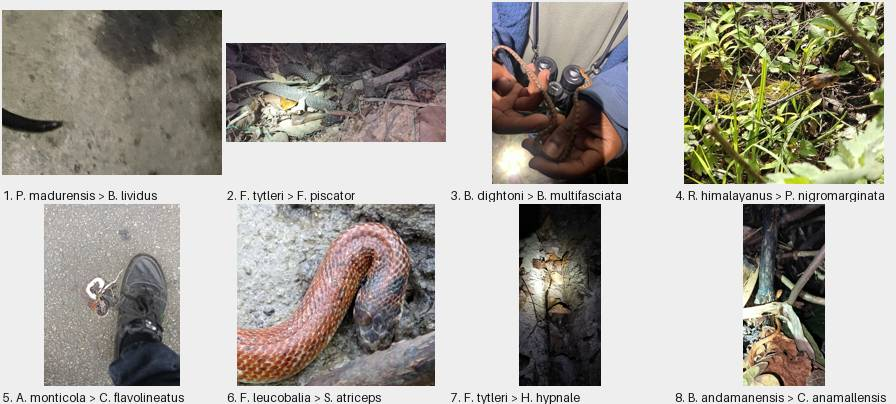

,species,WHO,guess,p_label,licence,credit
1,Platyplectrurus madurensis,Not listed,Bungarus lividus,0.0,cc-by,"(c) Nandini Rajamani, some rights reserved (CC BY)"
2,Fowlea tytleri,Not listed,Fowlea piscator,0.0,cc-by,"(c) Jyotsna Nag, some rights reserved (CC BY)"
3,Boiga dightoni,Not listed,Boiga multifasciata,0.0,cc-by,"(c) Ronith Urs, some rights reserved (CC BY)"
4,Rhabdophis himalayanus,Not listed,Ptyas nigromarginata,0.0,cc-by,"(c) Jigu, some rights reserved (CC BY)"
5,Amphiesma monticola,Not listed,Coelognathus flavolineatus,0.0,cc-by,"(c) renjus box, some rights reserved (CC BY)"
6,Fordonia leucobalia,Not listed,Spalerosophis atriceps,0.0,cc-by,"(c) Andrew Parker, some rights reserved (CC BY)"
7,Fowlea tytleri,Not listed,Hypnale hypnale,0.0,cc-by,"(c) Jyotsna Nag, some rights reserved (CC BY)"
8,Boiga andamanensis,Not listed,Craspedocephalus anamallensis,0.0,cc-by,"(c) Jyotsna Nag, some rights reserved (CC BY)"


In [175]:
if CL_OK:
    cl_view = img_label(img_pick(cl_table, 8, ("rank", True)))
    cl_entries = [(r.path, f"{r.label}. {img_short(r.species)} > {img_short(r.guess)}") for r in cl_view.itertuples()]
    img_show(img_grid(cl_entries))
    img_credits(cl_view, extra=("guess", "p_label"))

Most of these eight show a snake that is tiny, half hidden in leaves or lit by a torch at night, and a few have a boot, a hand or binoculars in the frame. So the classifier is mostly unsure because the snake is hard to see, which is a photo-quality problem more than a wrong label. This fits the masks in 7b, where the detector found no snake in some photos. A clear photo such as number 6 is the kind worth a hand check. Nothing should be deleted or relabelled from this list before someone has looked at the photo.

## 6. Context: where, when, who and under which licence
The pictures are only part of the story. The table also says where and when each photo was taken, who took it and what licence it has. All of this changes how far the data can be trusted to cover the real world.

### 6.1 Geography
Only photos with coordinates can go on a map. Let's plot the ones inside India, coloured by WHO category, and draw the dangerous categories last so they stay visible.

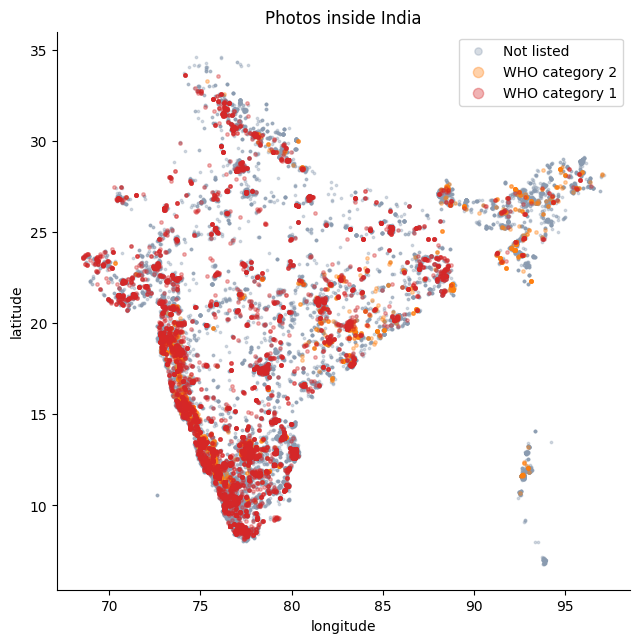

In [176]:
tab_geo = meta.dropna(subset=["latitude", "longitude"])
tab_ind = tab_geo[tab_geo["in_india"]]
fig, ax = plt.subplots(figsize=(6.5, 7))
for cat, size in [("not_listed", 3), ("2", 6), ("1", 6)]:
    d = tab_ind[tab_ind["who_category"] == cat]
    ax.scatter(d["longitude"], d["latitude"], s=size, alpha=0.35, color=WHO_COLORS[cat], label=WHO_LABEL[cat], rasterized=True)
ax.set(xlabel="longitude", ylabel="latitude", title="Photos inside India"); ax.set_aspect("equal")
ax.legend(markerscale=3, loc="upper right")
savefig("06_india_map"); plt.close()

The photos are densest along the Western Ghats, in the north-east and around the big cities, and thin in the centre and the north-west. So the data shows where snakes are photographed, not where they live, and the empty areas are not proof that a species is absent there.

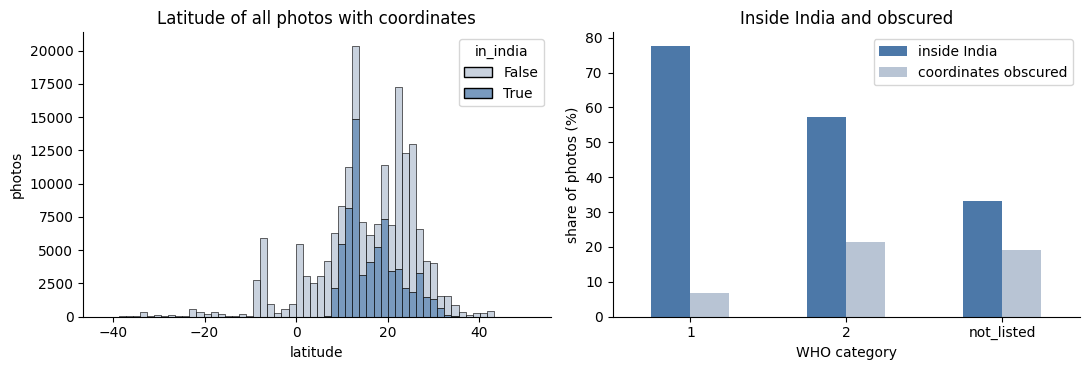

In [177]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(data=tab_geo, x="latitude", hue="in_india", multiple="stack", bins=60, palette={True: "#4c78a8", False: "#b8c4d4"}, ax=ax[0])
ax[0].set(xlabel="latitude", ylabel="photos", title="Latitude of all photos with coordinates")
tab_geo_rate = (100 * meta.groupby("who_category")[["in_india", "obscured"]].mean()).reindex(["1", "2", "not_listed"])
tab_geo_rate.plot.bar(ax=ax[1], rot=0, color=["#4c78a8", "#b8c4d4"])
ax[1].set(xlabel="WHO category", ylabel="share of photos (%)", title="Inside India and obscured"); ax[1].legend(["inside India", "coordinates obscured"])
savefig("06_latitude"); plt.close()

Only part of the photos are inside India, and outside India the latitude range is much wider than inside it. So the data mixes Indian photos with the same species photographed elsewhere. On the right, category 1 has the largest share of photos inside India, and the share of obscured coordinates differs between the categories.

In [178]:
print(f"{meta['in_india'].mean():.1%} of the photos are inside India and {meta['obscured'].mean():.1%} have obscured coordinates")
print("inside India by split (%):", (100 * meta.groupby("split")["in_india"].mean()).round(1).to_dict())
print("latitude outside India, 5th / median / 95th percentile:", tab_geo.loc[~tab_geo["in_india"], "latitude"].quantile([0.05, 0.5, 0.95]).round(1).tolist())
print("latitude inside India, 5th / median / 95th percentile:", tab_ind["latitude"].quantile([0.05, 0.5, 0.95]).round(1).tolist())

37.7% of the photos are inside India and 18.2% have obscured coordinates
inside India by split (%): {'test': 100.0, 'test_extra': 12.7, 'train': 37.6, 'unknown_pool': 83.8, 'val': 37.2}
latitude outside India, 5th / median / 95th percentile: [-7.8, 18.5, 30.2]
latitude inside India, 5th / median / 95th percentile: [9.8, 15.4, 28.0]


### 6.2 Time
Two dates are stored: the day the snake was seen (`observed_on`, date only) and the time the photo was uploaded (`created_at`). Let's compare them.

In [179]:
tab_up = meta["created_at"].dt.tz_convert(None).dt.normalize()
tab_lag = (tab_up - meta["observed_on"]).dt.days
print(f"observed {meta['year'].min()} to {meta['year'].max()}, uploaded {meta['created_at'].dt.year.min()} to {meta['created_at'].dt.year.max()}")
print(f"median gap between seeing and uploading: {tab_lag.median():.0f} days; {(tab_lag <= 1).mean():.1%} within a day, {(tab_lag > 365).mean():.1%} after more than a year")
print(f"negative gaps (the upload time is in UTC, the observed date is local): {(tab_lag < 0).sum():,}")

observed 1968 to 2026, uploaded 2010 to 2026
median gap between seeing and uploading: 2 days; 47.5% within a day, 13.5% after more than a year
negative gaps (the upload time is in UTC, the observed date is local): 1,920


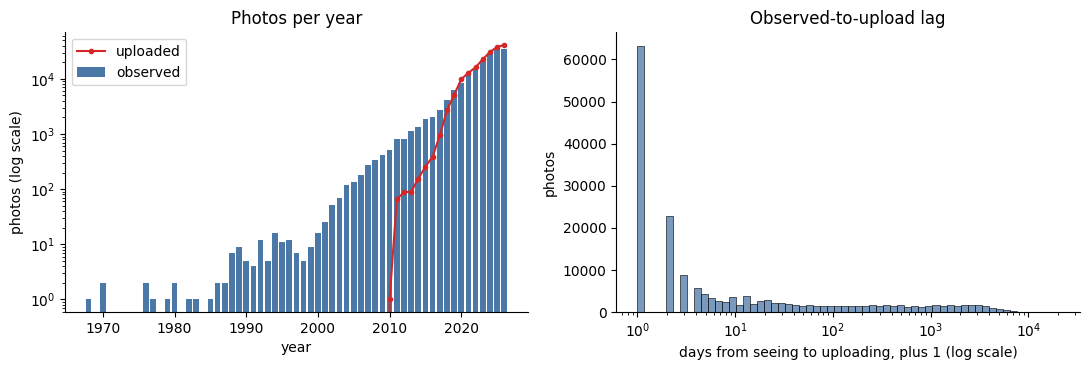

In [180]:
tab_yr = pd.DataFrame({"observed": meta["year"].value_counts(), "uploaded": meta["created_at"].dt.year.value_counts()}).fillna(0).sort_index()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(tab_yr.index, tab_yr["observed"], color="#4c78a8", label="observed")
ax[0].plot(tab_yr.index, tab_yr["uploaded"], color="#d62728", marker="o", ms=3, label="uploaded"); ax[0].legend()
ax[0].set(yscale="log", xlabel="year", ylabel="photos (log scale)", title="Photos per year")
sns.histplot(tab_lag.clip(lower=0) + 1, log_scale=True, bins=60, color="#4c78a8", ax=ax[1])
ax[1].set(xlabel="days from seeing to uploading, plus 1 (log scale)", ylabel="photos", title="Observed-to-upload lag")
savefig("06_time"); plt.close()

Uploads grow strongly over the years, and the observation years reach further back because some photos were taken long before they were uploaded. Most photos are uploaded within days, with a long tail of old pictures that were digitised later.

Next, the seasons. For each WHO category we take the share of its photos taken in each month, so the lines are comparable even though the categories have very different sizes.

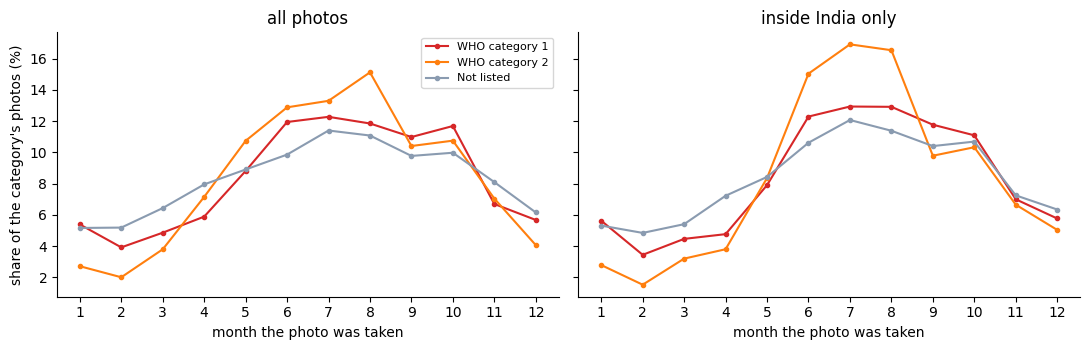

In [181]:
tab_in_ind = meta[meta["in_india"]]
tab_mo = [pd.crosstab(d["month"], d["who_category"], normalize="columns") * 100 for d in (meta, tab_in_ind)]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, tb, title in zip(ax, tab_mo, ["all photos", "inside India only"]):
    for cat in ["1", "2", "not_listed"]:
        a.plot(tb.index, tb[cat], marker="o", ms=3, color=WHO_COLORS[cat], label=WHO_LABEL[cat])
    a.set(xticks=range(1, 13), xlabel="month the photo was taken", title=title)
ax[0].set_ylabel("share of the category's photos (%)"); ax[0].legend(fontsize=8)
savefig("06_seasons"); plt.close()

All three categories peak in the middle of the year, which is the monsoon in India, and are lowest in the winter months. Category 2 has the sharpest peak. The curves for all photos are flatter than for India alone, since photos from other parts of the world have other seasons.

### 6.3 Photographers
`observer_id` is the account that took the photo. We only look at counts per photographer here, never at who they are. A few very active people can dominate the data, so let's measure how concentrated it is.

In [182]:
tab_obs = meta.groupby("observer_id").size().sort_values()
tab_top1 = tab_obs.tail(int(0.01 * len(tab_obs))).sum() / tab_obs.sum()
print(f"{len(tab_obs):,} photographers, median {tab_obs.median():.0f} photos each, {(tab_obs == 1).mean():.1%} of them with a single photo")
print(f"Gini of photos per photographer: {tab_gini(tab_obs):.2f}; the top 1% took {tab_top1:.1%} of the photos; the busiest took {tab_obs.max():,} photos")
check("25,041 photographers", len(tab_obs) == 25041, f"{len(tab_obs):,}")
check("the top 1% of photographers took 26.6% of the photos", round(100 * tab_top1, 1) == 26.6, f"{tab_top1:.1%}")
check("the busiest photographer took 2,189 photos", tab_obs.max() == 2189, f"{tab_obs.max():,}")

25,041 photographers, median 2 photos each, 38.4% of them with a single photo
Gini of photos per photographer: 0.72; the top 1% took 26.6% of the photos; the busiest took 2,189 photos
PASS  25,041 photographers  (25,041)
PASS  the top 1% of photographers took 26.6% of the photos  (26.6%)
PASS  the busiest photographer took 2,189 photos  (2,189)


PASS  Gini from the Lorenz curve matches the direct formula  (0.715)


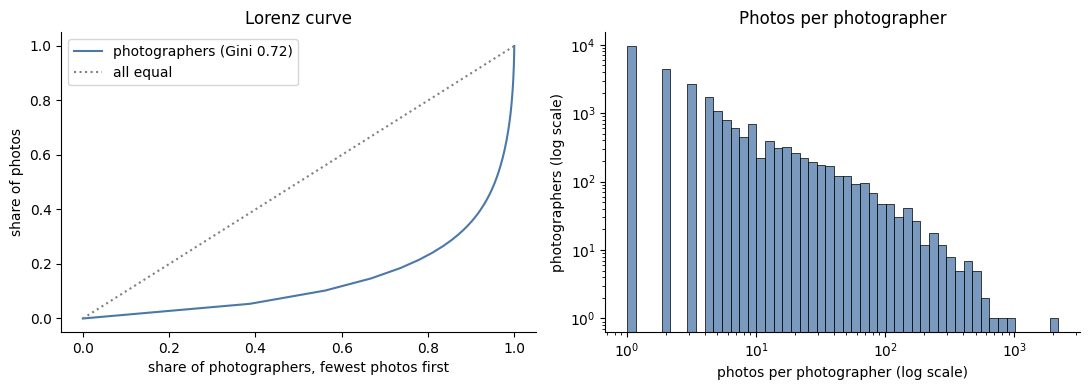

In [183]:
tab_lz = np.insert(tab_obs.cumsum().values / tab_obs.sum(), 0, 0)
tab_xs = np.linspace(0, 1, len(tab_lz))
tab_g2 = 1 - 2 * np.trapezoid(tab_lz, tab_xs)
check("Gini from the Lorenz curve matches the direct formula", abs(tab_g2 - tab_gini(tab_obs)) < 0.01, f"{tab_g2:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(tab_xs, tab_lz, color="#4c78a8", label=f"photographers (Gini {tab_g2:.2f})"); ax[0].plot([0, 1], [0, 1], ls=":", color="grey", label="all equal"); ax[0].legend()
ax[0].set(xlabel="share of photographers, fewest photos first", ylabel="share of photos", title="Lorenz curve")
sns.histplot(tab_obs, log_scale=True, bins=50, color="#4c78a8", ax=ax[1])
ax[1].set(yscale="log", xlabel="photos per photographer (log scale)", ylabel="photographers (log scale)", title="Photos per photographer")
savefig("06_photographers"); plt.close()

The curve bends far below the diagonal: most photographers contribute a handful of photos while a small group contributes a large part. A model can pick up the habits of one photographer (the same garden, the same camera) instead of the snake, which is why train, val and test are split by observer.

How concentrated is it inside each class? For every class we take its training photos and add up the share taken by its three most active photographers.

In [184]:
tab_tr = meta[meta["split"] == "train"]
tab_per = tab_tr.groupby(["species", "observer_id"]).size().sort_values(ascending=False)
tab_top3 = tab_per.groupby("species").head(3).groupby("species").sum()
tab_phc = pd.DataFrame({"photos": tab_tr.groupby("species").size(), "photographers": tab_per.groupby("species").size(), "top3_share_pct": 100 * tab_top3 / tab_tr.groupby("species").size()})
tab_phc = tab_phc.join(classes.set_index("species")["who_category"]).dropna(subset=["who_category"])
print(f"median share of a class's training photos taken by its top 3 photographers: {tab_phc['top3_share_pct'].median():.1f}%")
tab_phc.sort_values("top3_share_pct", ascending=False).head(8).round(1)

median share of a class's training photos taken by its top 3 photographers: 26.2%


,photos,photographers,top3_share_pct,who_category
species,,,,
Wallaceophis gujaratensis,24,2,100.0,not_listed
Uropeltis shorttii,20,5,90.0,not_listed
Melanophidium punctatum,26,6,88.5,not_listed
Melanophidium bilineatum,21,6,85.7,not_listed
Uropeltis maculata,18,5,83.3,not_listed
Ahaetulla perroteti,29,6,82.8,not_listed
Platyceps ladacensis,17,6,82.4,not_listed
Platyceps josephi,23,6,78.3,not_listed


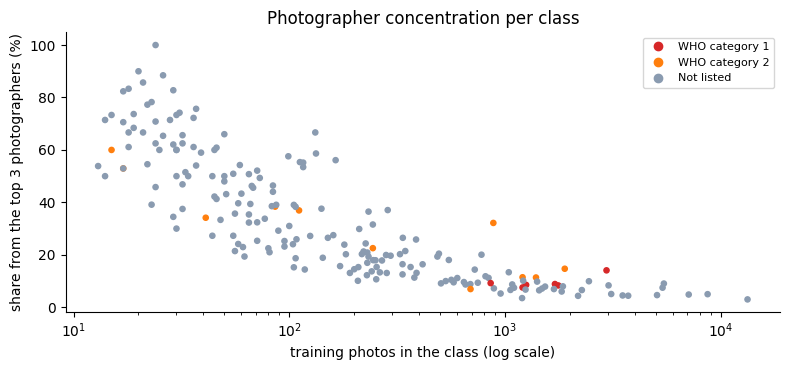

In [185]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(tab_phc["photos"], tab_phc["top3_share_pct"], c=[WHO_COLORS[w] for w in tab_phc["who_category"]], s=14)
ax.set(xscale="log", xlabel="training photos in the class (log scale)", ylabel="share from the top 3 photographers (%)", title="Photographer concentration per class")
tab_who_legend(ax, loc="upper right", fontsize=8)
savefig("06_top3_share"); plt.close()

Small classes lean on a few photographers, and the top-3 share falls as classes get bigger. For the smallest classes a handful of people took a large part of the training photos, so those classes carry the most risk of learning a photographer instead of a snake.

### 6.4 Licences
The licence decides which photos we can show in this notebook. The rule used throughout: CC0 and CC BY photos are shown first, CC BY-NC only as a labelled fallback, and photos under any other licence (no-derivatives, share-alike, all rights reserved) are used for statistics only.

In [186]:
tab_rule_map = {"cc0": "show first", "cc-by": "show first", "cc-by-nc": "show with label"}
tab_show = meta["license"].map(tab_rule_map).fillna("statistics only")
tab_lic = meta["license"].value_counts().to_frame("photos")
tab_lic["share %"] = (100 * tab_lic["photos"] / len(meta)).round(1)
tab_lic["use in the notebook"] = pd.Series(tab_rule_map).reindex(tab_lic.index).fillna("statistics only")
print("share of photos by use (%):", (100 * tab_show.value_counts(normalize=True)).round(1).to_dict())
tab_lic

share of photos by use (%): {'show with label': 55.9, 'statistics only': 35.0, 'show first': 9.1}


,photos,share %,use in the notebook
license,,,
cc-by-nc,101308,55.9,show with label
all-rights-reserved,56662,31.3,statistics only
cc-by,14964,8.3,show first
cc-by-nc-nd,2902,1.6,statistics only
cc-by-nc-sa,2628,1.5,statistics only
cc0,1471,0.8,show first
cc-by-sa,1185,0.7,statistics only
cc-by-nd,111,0.1,statistics only


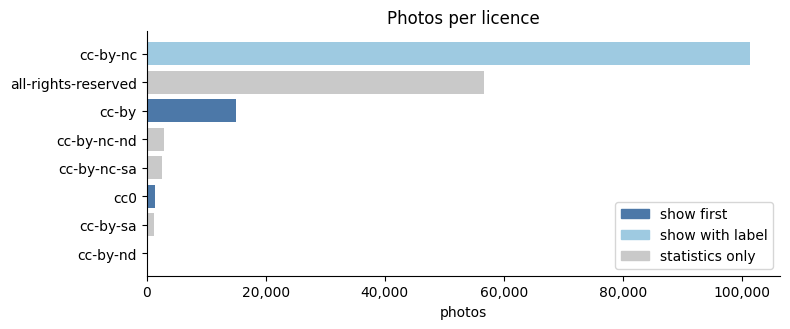

In [187]:
tab_col = {"show first": "#4c78a8", "show with label": "#9ecae1", "statistics only": "#c9c9c9"}
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(tab_lic.index, tab_lic["photos"], color=[tab_col[u] for u in tab_lic["use in the notebook"]])
ax.set(xlabel="photos", title="Photos per licence"); ax.xaxis.set_major_formatter(FMT); ax.invert_yaxis()
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in tab_col.values()], labels=list(tab_col), loc="lower right")
savefig("06_licences"); plt.close()

One licence dominates, and the licences that allow showing a photo without extra conditions are a small part of the data. Let's see how this differs by split and by WHO category. A mix that is close across splits and categories means the licence rule does not bias what we show.

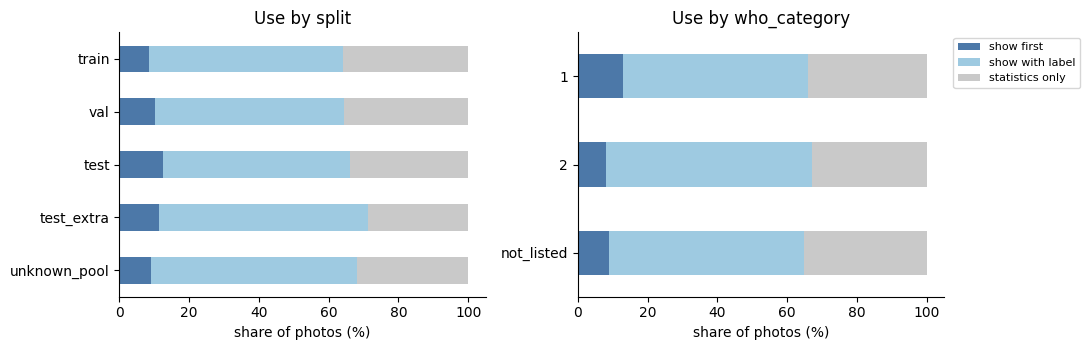

In [188]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for a, key, order in zip(ax, ["split", "who_category"], [SPLIT_ORDER, ["1", "2", "not_listed"]]):
    tb = (100 * pd.crosstab(meta[key], tab_show, normalize="index")).reindex(order)[list(tab_col)]
    tb.plot.barh(stacked=True, color=list(tab_col.values()), ax=a, legend=False); a.invert_yaxis()
    a.set(xlabel="share of photos (%)", ylabel="", title=f"Use by {key}")
ax[1].legend(list(tab_col), bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
savefig("06_licence_groups"); plt.close()

How many classes can actually be shown? If a class has no CC0 or CC BY photo at all, its pictures can only come from the labelled fallback.

In [189]:
tab_sp_show = pd.crosstab(meta["species"], tab_show).reindex(index=classes["species"], columns=list(tab_col), fill_value=0)
tab_few = pd.Series({f"under {n} CC0 or CC BY photos": int((tab_sp_show["show first"] < n).sum()) for n in (1, 5, 10, 20)})
print(f"{len(classes)} classes in total")
print(tab_few.to_string())
print("classes with no photo at all that can be shown, first or labelled:", int(((tab_sp_show["show first"] + tab_sp_show["show with label"]) == 0).sum()))
tab_lw = tab_sp_show.join(classes.set_index("species")["who_category"]).query("who_category != 'not_listed'")
tab_lw.sort_values("show first").head(6)

208 classes in total
under 1 CC0 or CC BY photos      24
under 5 CC0 or CC BY photos      56
under 10 CC0 or CC BY photos     79
under 20 CC0 or CC BY photos    104
classes with no photo at all that can be shown, first or labelled: 0


,show first,show with label,statistics only,who_category
species,,,,
Bungarus walli,0,25,5,2
Naja oxiana,0,44,13,2
Bungarus sindanus,0,15,8,2
Bungarus niger,18,66,36,2
Ophiophagus kaalinga,44,60,51,2
Naja kaouthia,45,697,459,1


## 7. Safety lookalikes
Some harmless snakes are easy to mistake for dangerous ones, and the mistake that matters most is calling a dangerous snake harmless. The pairs come from the list defined at the start, and the WHO category of each species is read from `classes.csv`. Let's count the photos each side of every pair has in every split.

In [190]:
tab_cnt = pd.crosstab(meta["species"], meta["split"]).reindex(columns=SPLIT_ORDER[:4], fill_value=0)

def tab_pair_rows(pairs, roles):
    rows = []
    for first, second, desc in pairs:
        for role, sp in zip(roles, (first, second)):
            rows.append({"pair": desc, "role": role, "species": sp, "WHO": who_of[sp], **tab_cnt.loc[sp].to_dict(), "total": int(tab_cnt.loc[sp].sum())})
    return pd.DataFrame(rows)

tab_pairs = tab_pair_rows(LOOKALIKES, ("dangerous side", "look-alike side"))
tab_pairs.set_index(["pair", "role"])

species  \
pair                                      role                                          
spectacled cobra and oriental rat snake   dangerous side                    Naja naja   
                                          look-alike side                Ptyas mucosa   
common krait and Indian wolf snake        dangerous side           Bungarus caeruleus   
                                          look-alike side             Lycodon aulicus   
common krait and Travancore wolf snake    dangerous side           Bungarus caeruleus   
                                          look-alike side       Lycodon travancoricus   
common krait and Russell's wolf snake     dangerous side           Bungarus caeruleus   
                                          look-alike side         Lycodon fasciolatus   
Russell's viper and rough-scaled sand boa dangerous side              Daboia russelii   
                                          look-alike side                Eryx conicus   
Russell's viper and Indian rock python    dangerous side              Daboia russelii   
                                          look-alike side              Python molurus   
saw-scaled viper and common cat snake     dangerous side              Echis carinatus   
                                          look-alike side             Boiga trigonata   
spectacled cobra and checkered keelback   dangerous side                    Naja naja   
                                          look-alike side             Fowlea piscator   
bamboo pit viper and green keelback       dangerous side   Craspedocephalus gramineus   
                                          look-alike side      Rhabdophis plumbicolor   

                                                                  WHO  train  \
pair                                      role                                 
spectacled cobra and oriental rat snake   dangerous side            1   2955   
                                          look-alike side  not_listed   7105   
common krait and Indian wolf snake        dangerous side            1   1253   
                                          look-alike side  not_listed   1686   
common krait and Travancore wolf snake    dangerous side            1   1253   
                                          look-alike side  not_listed    691   
common krait and Russell's wolf snake     dangerous side            1   1253   
                                          look-alike side  not_listed    656   
Russell's viper and rough-scaled sand boa dangerous side            1   1704   
                                          look-alike side  not_listed    954   
Russell's viper and Indian rock python    dangerous side            1   1704   
                                          look-alike side  not_listed   1245   
saw-scaled viper and common cat snake     dangerous side            1   1766   
                                          look-alike side  not_listed    564   
spectacled cobra and checkered keelback   dangerous side            1   2955   
                                          look-alike side  not_listed   5375   
bamboo pit viper and green keelback       dangerous side            2   1206   
                                          look-alike side  not_listed    531   

                                                            val  test  \
pair                                      role                          
spectacled cobra and oriental rat snake   dangerous side    586   385   
                                          look-alike side  1418   555   
common krait and Indian wolf snake        dangerous side    251   192   
                                          look-alike side   336   190   
common krait and Travancore wolf snake    dangerous side    251   192   
                                          look-alike side   138   100   
common krait and Russell's wolf snake     dangerous side    251   192   
                                       

Some species appear in more than one pair, for example the same dangerous snake with several harmless ones, so the table repeats their counts. A pair can only be tested if both sides have test photos, so let's read the test counts on their own.

In [191]:
tab_wide = pd.DataFrame([{"dangerous": d, "harmless": s, "dangerous_who": who_of[d], "harmless_who": who_of[s],
                          **{f"dangerous_{c}": int(tab_cnt.loc[d, c]) for c in tab_cnt.columns}, **{f"harmless_{c}": int(tab_cnt.loc[s, c]) for c in tab_cnt.columns}} for d, s, _ in LOOKALIKES])
tab_wide.to_csv(WORK / "lookalike_pairs.csv", index=False)
print(f"wrote {WORK / 'lookalike_pairs.csv'} with {len(tab_wide)} pairs and {tab_wide.shape[1]} columns")
tab_wide[["dangerous", "harmless", "dangerous_test", "harmless_test"]]

wrote /kaggle/working/lookalike_pairs.csv with 9 pairs and 12 columns


,dangerous,harmless,dangerous_test,harmless_test
0,Naja naja,Ptyas mucosa,385,555
1,Bungarus caeruleus,Lycodon aulicus,192,190
2,Bungarus caeruleus,Lycodon travancoricus,192,100
3,Bungarus caeruleus,Lycodon fasciolatus,192,70
4,Daboia russelii,Eryx conicus,225,146
5,Daboia russelii,Python molurus,225,164
6,Echis carinatus,Boiga trigonata,113,86
7,Naja naja,Fowlea piscator,385,707
8,Craspedocephalus gramineus,Rhabdophis plumbicolor,339,101


In [192]:
check("all 9 look-alike pairs are in classes.csv", len(LOOKALIKES) == 9, f"{len(LOOKALIKES)} found")
check("the dangerous side of every pair is in WHO category 1 or 2", all(who_of[d] in ("1", "2") for d, _, _ in LOOKALIKES))
check("the look-alike side of every pair is not listed", all(who_of[s] == "not_listed" for _, s, _ in LOOKALIKES))
tab_notest = tab_pairs[tab_pairs["test"] == 0]
tab_both = [d for d, s, _ in LOOKALIKES if tab_cnt.loc[d, "test"] > 0 and tab_cnt.loc[s, "test"] > 0]
print(f"{len(tab_both)} of {len(LOOKALIKES)} pairs have test photos on both sides; the fewest test photos on one species is {int(tab_pairs['test'].min())}")
print("species with no test photos:", ", ".join(tab_notest["species"].unique()) or "none")
print("species with fewer than 10 test photos:", ", ".join(tab_pairs.loc[tab_pairs["test"] < 10, "species"].unique()) or "none")

PASS  all 9 look-alike pairs are in classes.csv  (9 found)
PASS  the dangerous side of every pair is in WHO category 1 or 2
PASS  the look-alike side of every pair is not listed
9 of 9 pairs have test photos on both sides; the fewest test photos on one species is 70
species with no test photos: none
species with fewer than 10 test photos: none


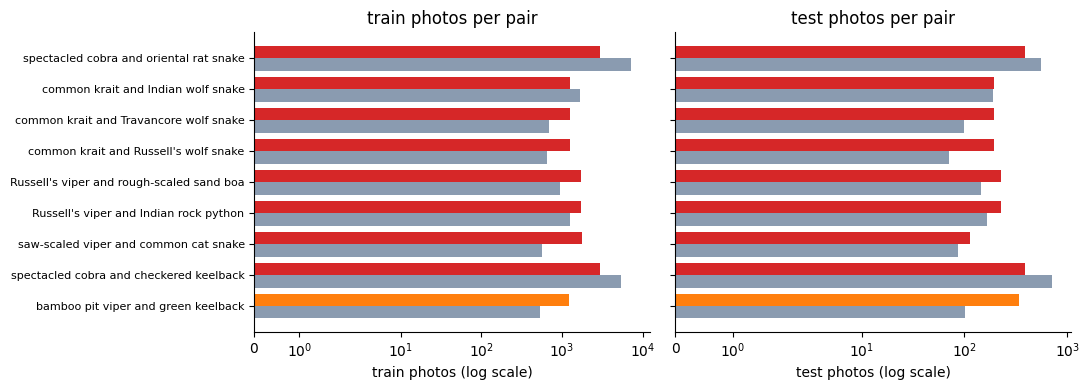

In [193]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
tab_pos = np.arange(len(LOOKALIKES))
for a, col in zip(ax, ["train", "test"]):
    for role, off in [("dangerous side", -0.2), ("look-alike side", 0.2)]:
        d = tab_pairs[tab_pairs["role"] == role]
        a.barh(tab_pos + off, d[col].values, height=0.4, color=[WHO_COLORS[w] for w in d["WHO"]])
    a.set(xscale="symlog", xlabel=f"{col} photos (log scale)", title=f"{col} photos per pair")
ax[0].set_yticks(tab_pos, [desc for _, _, desc in LOOKALIKES], fontsize=8); ax[0].invert_yaxis()
savefig("07_lookalike_counts"); plt.close()

In each pair the upper bar is the dangerous snake (red or orange) and the lower bar the look-alike (grey), on a log scale. A species with no photos in a split has no bar. The two sides are rarely balanced, in train or in test, and the smaller side of a pair sets how well that pair can be scored: with few test photos on one side, a test score for the pair is noisy.

### 7.1 Do the two sides of a pair look equally sharp and bright?
If the dangerous snake is photographed in a different way from its look-alike (blurrier, darker), a model might learn the photo style instead of the pattern on the skin. Here we use the quality table from section 5, which covers a sample of photos per class.

In [194]:
tab_qp = []
for dang, safe, desc in (LOOKALIKES if "quality" in globals() else []):
    a, b = quality[quality["species"] == dang], quality[quality["species"] == safe]
    if min(len(a), len(b)) >= 5:
        p = stats.mannwhitneyu(a["sharpness"], b["sharpness"]).pvalue
        tab_qp.append({"pair": desc, "n_dangerous": len(a), "n_lookalike": len(b), "sharp_dangerous": a["sharpness"].median(), "sharp_lookalike": b["sharpness"].median(),
                       "bright_dangerous": a["brightness"].median(), "bright_lookalike": b["brightness"].median(), "p_sharpness": p})
tab_qp = pd.DataFrame(tab_qp)
print(f"{len(tab_qp)} of {len(LOOKALIKES)} pairs have at least 5 sampled photos on both sides")
tab_qp.round(3).set_index("pair") if len(tab_qp) else None

9 of 9 pairs have at least 5 sampled photos on both sides


,n_dangerous,n_lookalike,sharp_dangerous,sharp_lookalike,bright_dangerous,bright_lookalike,p_sharpness
pair,,,,,,,
spectacled cobra and oriental rat snake,30,30,1085.422,1800.758,120.308,126.252,0.082
common krait and Indian wolf snake,30,30,2496.314,928.135,100.635,136.713,0.006
common krait and Travancore wolf snake,30,30,2496.314,1915.150,100.635,107.217,0.420
common krait and Russell's wolf snake,30,30,2496.314,1137.201,100.635,133.941,0.009
Russell's viper and rough-scaled sand boa,30,30,2558.967,1897.811,116.095,123.639,0.277
Russell's viper and Indian rock python,30,30,2558.967,2529.025,116.095,106.848,0.673
saw-scaled viper and common cat snake,30,30,2643.303,1380.145,105.882,114.602,0.234
spectacled cobra and checkered keelback,30,30,1085.422,1658.725,120.308,125.399,0.842
bamboo pit viper and green keelback,30,30,1193.624,2353.089,65.607,125.501,0.075


In [195]:
for r in tab_qp.itertuples():
    word = "sharper" if r.sharp_dangerous > r.sharp_lookalike else "blurrier"
    print(f"{r.pair}: the dangerous snake's photos are {word} (median {r.sharp_dangerous:.0f} against {r.sharp_lookalike:.0f}, p = {r.p_sharpness:.3f}) and {'brighter' if r.bright_dangerous > r.bright_lookalike else 'darker'} ({r.bright_dangerous:.0f} against {r.bright_lookalike:.0f})")
if tab_qp.empty:
    print("no pair has enough sampled photos in this run")

spectacled cobra and oriental rat snake: the dangerous snake's photos are blurrier (median 1085 against 1801, p = 0.082) and darker (120 against 126)
common krait and Indian wolf snake: the dangerous snake's photos are sharper (median 2496 against 928, p = 0.006) and darker (101 against 137)
common krait and Travancore wolf snake: the dangerous snake's photos are sharper (median 2496 against 1915, p = 0.420) and darker (101 against 107)
common krait and Russell's wolf snake: the dangerous snake's photos are sharper (median 2496 against 1137, p = 0.009) and darker (101 against 134)
Russell's viper and rough-scaled sand boa: the dangerous snake's photos are sharper (median 2559 against 1898, p = 0.277) and darker (116 against 124)
Russell's viper and Indian rock python: the dangerous snake's photos are sharper (median 2559 against 2529, p = 0.673) and brighter (116 against 107)
saw-scaled viper and common cat snake: the dangerous snake's photos are sharper (median 2643 against 1380, p = 

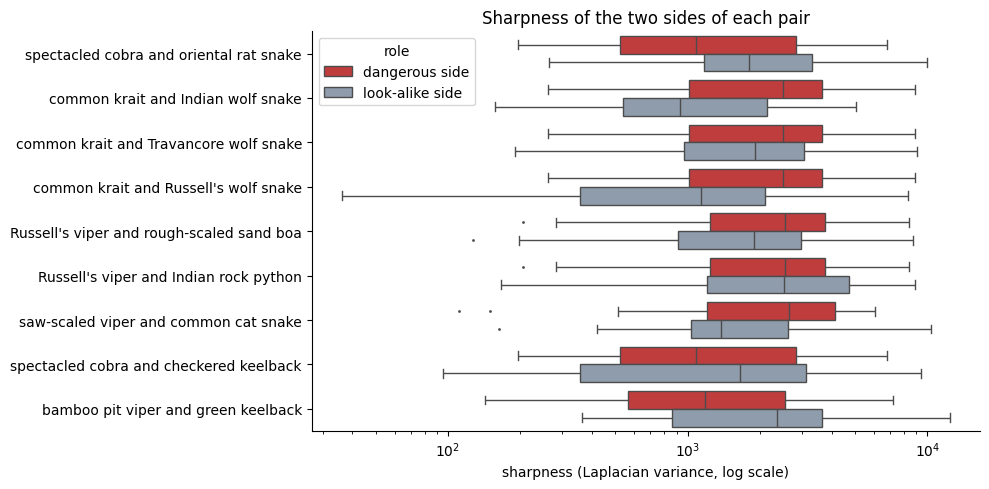

In [196]:
if len(tab_qp):
    tab_ql = quality[quality["species"].isin(tab_pairs["species"])].merge(tab_pairs[["species", "pair", "role"]], on="species")
    tab_ql = tab_ql[tab_ql["pair"].isin(tab_qp["pair"])]
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.boxplot(data=tab_ql, y="pair", x="sharpness", hue="role", hue_order=["dangerous side", "look-alike side"], order=list(tab_qp["pair"]), log_scale=True, fliersize=1, palette=["#d62728", "#8a9bb0"], ax=ax)
    ax.set(xlabel="sharpness (Laplacian variance, log scale)", ylabel="", title="Sharpness of the two sides of each pair")
    savefig("07_lookalike_sharpness"); plt.close()

The boxes show whether the two sides of a pair sit at a similar sharpness. If a dangerous snake is clearly blurrier or sharper than its look-alike, a model could separate them by image quality alone, so the printed comparison above is worth a look before drawing conclusions from the confusion matrix.

### 7.2 Pairs where both snakes are dangerous
Two pairs are different: both snakes are dangerous, so a mix-up inside the pair is not harmless-versus-dangerous but still a wrong answer. They get their own short table.

In [197]:
tab_dd = tab_pair_rows(DANGEROUS, ("first snake", "second snake"))
check("both snakes of the dangerous pairs are in WHO category 1 or 2", all(who_of[a] in ("1", "2") and who_of[b] in ("1", "2") for a, b, _ in DANGEROUS))
print(f"{len(DANGEROUS)} pairs with two dangerous snakes")
tab_dd.set_index(["pair", "role"]) if len(tab_dd) else None

PASS  both snakes of the dangerous pairs are in WHO category 1 or 2
2 pairs with two dangerous snakes


species  \
pair                                      role                                         
hump-nosed and Malabar pit viper          first snake                Hypnale hypnale   
                                          second snake  Craspedocephalus malabaricus   
hump-nosed pit viper and saw-scaled viper first snake                Hypnale hypnale   
                                          second snake               Echis carinatus   

                                                       WHO  train  val  test  \
pair                                      role                                 
hump-nosed and Malabar pit viper          first snake    1   1206  241   176   
                                          second snake   2   1892  377   330   
hump-nosed pit viper and saw-scaled viper first snake    1   1206  241   176   
                                          second snake   1   1766  354   113   

                                                        test_extra  total  
pair                                      role                             
hump-nosed and Malabar pit viper          first snake           65   1688  
                                          second snake          62   2661  
hump-nosed pit viper and saw-scaled viper first snake           65   1688  
                                          second snake         240   2473

### 7a. Cleaning funnel
The cleaning notebook started from all downloaded photos, dropped some for clear reasons (`excluded.csv`), split the rest, and then removed near-duplicates from val and test. Let's rebuild that funnel from the files.

In [198]:
tab_raw = len(splits_all) + len(excluded)
tab_red = excluded["drop_reason"].value_counts()
print(f"raw rows: {len(splits_all):,} in splits.csv + {len(excluded):,} in excluded.csv = {tab_raw:,}")
if tab_split_rep:
    check("raw rows equal raw_photos in split_report.json", tab_raw == tab_split_rep.get("raw_photos"), f"{tab_split_rep.get('raw_photos')}")
check("excluded.csv has 994 rows", len(excluded) == 994, f"{len(excluded)}")
for reason, n in {"exact_duplicate": 928, "duplicate_conflicting_species": 30, "too_small": 36}.items():
    check(f"excluded for {reason}: {n}", tab_red.get(reason, 0) == n, f"{tab_red.get(reason, 0)} found")

raw rows: 181,503 in splits.csv + 994 in excluded.csv = 182,497
PASS  raw rows equal raw_photos in split_report.json  (182497)
PASS  excluded.csv has 994 rows  (994)
PASS  excluded for exact_duplicate: 928  (928 found)
PASS  excluded for duplicate_conflicting_species: 30  (30 found)
PASS  excluded for too_small: 36  (36 found)


In [199]:
tab_why = excluded.assign(short_side=excluded[["width", "height"]].min(axis=1)).groupby("drop_reason").agg(rows=("photo_id", "size"), shortest_side=("short_side", "min"), median_KB=("bytes", lambda s: s.median() / 1024), cc_licensed=("license", lambda s: s.str.startswith("cc").mean()))
tab_rl, tab_ts = tab_split_rep.get("rules", {}), excluded[excluded["drop_reason"] == "too_small"]
print("size rules in split_report.json:", {k: tab_rl.get(k) for k in ("min_bytes", "min_side_px")})
print(f"of {len(tab_ts)} too_small rows, {(tab_ts['bytes'] < tab_rl.get('min_bytes', 0)).sum()} are under the byte limit and {(tab_ts[['width', 'height']].min(axis=1) < tab_rl.get('min_side_px', 0)).sum()} under the side limit")
tab_why.round(2)

size rules in split_report.json: {'min_bytes': 5000, 'min_side_px': 100}
of 36 too_small rows, 19 are under the byte limit and 17 under the side limit


,rows,shortest_side,median_KB,cc_licensed
drop_reason,,,,
duplicate_conflicting_species,30,225,111.44,0.87
exact_duplicate,928,163,128.32,0.72
too_small,36,59,4.84,0.86


From the names: an exact duplicate repeats another photo, a conflicting duplicate shows the same photo under two different species, and a too-small photo breaks the minimum file size or image side. The printout above shows how many break each limit. Next, the near-duplicates: rows that are in `splits.csv` but no longer in the final metadata.

In [200]:
tab_nd = splits_all[~splits_all["photo_id"].isin(meta["photo_id"])]
tab_nd_n = tab_nd["split"].value_counts()
check("272 near-duplicates are in splits.csv but not in metadata.csv", len(tab_nd) == 272, f"{len(tab_nd)}")
check("they are 164 in val, 75 in test_extra and 33 in test", tab_nd_n.to_dict() == {"val": 164, "test_extra": 75, "test": 33}, str(tab_nd_n.to_dict()))
tab_mm = splits_all.merge(meta[["photo_id", "split"]], on="photo_id", suffixes=("", "_meta"))
check("no photo changes split between splits.csv and metadata.csv", (tab_mm["split"] == tab_mm["split_meta"]).all(), f"{(tab_mm['split'] != tab_mm['split_meta']).sum()} differ")
tab_ba = pd.DataFrame({"before": splits_all["split"].value_counts(), "after": meta["split"].value_counts()}).reindex(SPLIT_ORDER)
tab_ba["removed"] = tab_ba["before"] - tab_ba["after"]
tab_ba["removed %"] = (100 * tab_ba["removed"] / tab_ba["before"]).round(2)
tab_ba

PASS  272 near-duplicates are in splits.csv but not in metadata.csv  (272)
PASS  they are 164 in val, 75 in test_extra and 33 in test  ({'val': 164, 'test_extra': 75, 'test': 33})
PASS  no photo changes split between splits.csv and metadata.csv  (0 differ)


,before,after,removed,removed %
split,,,,
train,129241,129241,0,0.00
val,25803,25639,164,0.64
test,7338,7305,33,0.45
test_extra,18465,18390,75,0.41
unknown_pool,656,656,0,0.00


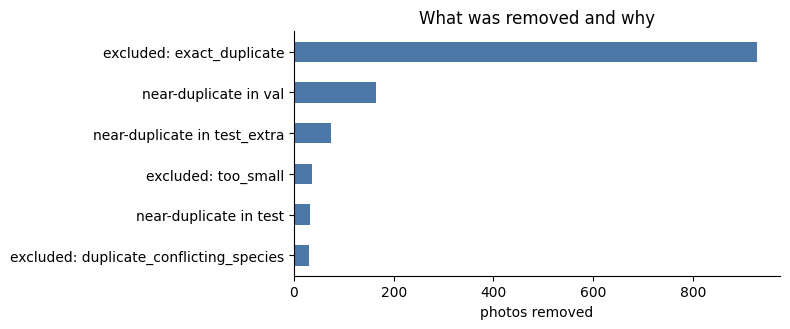

,step,photos,removed in this step
0,raw photos,182497,0
1,after excluded.csv,181503,994
2,after near-duplicates,181231,272


In [201]:
tab_steps = pd.DataFrame({"step": ["raw photos", "after excluded.csv", "after near-duplicates"], "photos": [tab_raw, len(splits_all), len(meta)]})
tab_steps["removed in this step"] = (-tab_steps["photos"].diff()).fillna(0).astype(int)
tab_why_n = pd.concat([tab_red.rename(lambda r: f"excluded: {r}"), tab_nd_n.rename(lambda s: f"near-duplicate in {s}")])
ax = tab_why_n.sort_values().plot.barh(color="#4c78a8", figsize=(8, 3.4))
ax.set(xlabel="photos removed", title="What was removed and why")
savefig("07a_funnel"); plt.close()
tab_steps

Exact duplicates are by far the biggest group of removed photos. The near-duplicates were removed only from val and test, so the splits stay clean without touching the training data. Which species lose the most?

In [202]:
tab_loss = pd.DataFrame({"excluded": excluded.groupby("species").size(), "near_duplicate": tab_nd.groupby("species").size()}).fillna(0).astype(int)
tab_loss["lost"] = tab_loss["excluded"] + tab_loss["near_duplicate"]
tab_loss["kept"] = meta.groupby("species").size().reindex(tab_loss.index).fillna(0).astype(int)
tab_loss["share lost %"] = (100 * tab_loss["lost"] / (tab_loss["lost"] + tab_loss["kept"])).round(1)
check("Indotyphlops braminus has the most photos in excluded.csv (105)", tab_loss["excluded"].idxmax() == "Indotyphlops braminus" and tab_loss["excluded"].max() == 105, f"{tab_loss['excluded'].idxmax()} {tab_loss['excluded'].max()}")
tab_big = tab_loss[tab_loss["lost"] + tab_loss["kept"] >= 50]
print(f"largest share lost: {tab_loss['share lost %'].max()}% ({tab_loss['share lost %'].idxmax()}); among species with 50+ raw photos: {tab_big['share lost %'].max()}%")
tab_loss.sort_values("lost", ascending=False).head(10)

PASS  Indotyphlops braminus has the most photos in excluded.csv (105)  (Indotyphlops braminus 105)
largest share lost: 20.6% (Platyceps josephi); among species with 50+ raw photos: 3.3%


,excluded,near_duplicate,lost,kept,share lost %
species,,,,,
Indotyphlops braminus,105,12,117,18328,0.6
Fowlea piscator,66,13,79,7511,1.0
Ptyas mucosa,52,10,62,9933,0.6
Ahaetulla prasina,33,18,51,12135,0.4
Python bivittatus,22,26,48,3228,1.5
Psammodynastes pulverulentus,33,8,41,7086,0.6
Elaphe taeniura,24,12,36,3417,1.0
Protobothrops mucrosquamatus,27,8,35,7621,0.5
Amphiesma stolatum,24,11,35,4340,0.8


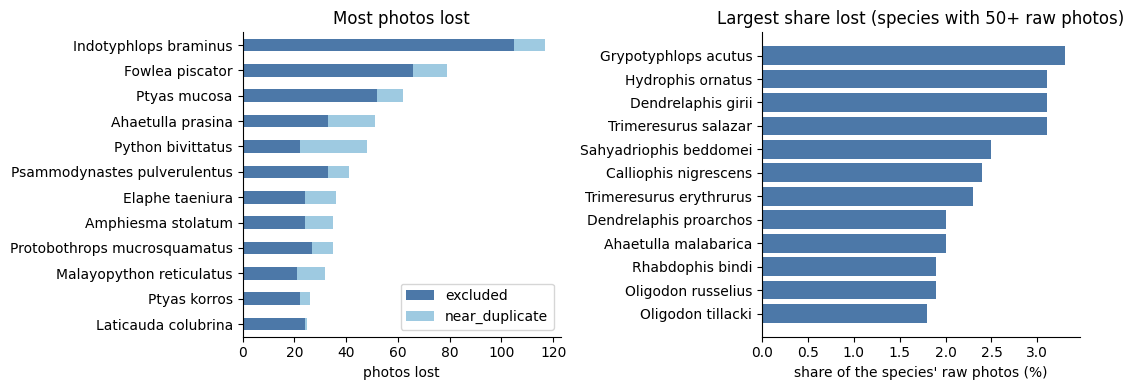

In [203]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
tab_loss.sort_values("lost").tail(12)[["excluded", "near_duplicate"]].plot.barh(stacked=True, ax=ax[0], color=["#4c78a8", "#9ecae1"])
ax[0].set(xlabel="photos lost", ylabel="", title="Most photos lost")
tab_rel = tab_loss[tab_loss["lost"] + tab_loss["kept"] >= 50].sort_values("share lost %").tail(12)
ax[1].barh(tab_rel.index, tab_rel["share lost %"], color="#4c78a8")
ax[1].set(xlabel="share of the species' raw photos (%)", title="Largest share lost (species with 50+ raw photos)")
savefig("07a_species_loss"); plt.close()

The species that lose the most photos are mostly the common ones, simply because they have the most photos and the most repeated uploads. The right panel shows the species that lose the largest share, which is a different group. It only includes species with 50 or more raw photos, because a rare species can lose a big share from just a few removed photos, as the printed line above shows.

Finally, a few of the removed photos. We fetch them from their `url` column, since the files themselves are not part of the datasets. Only CC photos are shown (CC0 and CC BY first, CC BY-NC as a labelled fallback), as small thumbnails, with the photographer credit and the reason they were removed.

In [204]:
import requests
from io import BytesIO
from IPython.display import display, Image as IPImage

tab_pref = {"cc0": 0, "cc-by": 0, "cc-by-nc": 1}
def tab_pick(reason, k):
    pool = excluded[(excluded["drop_reason"] == reason) & excluded["license"].isin(tab_pref) & (excluded["bytes"] < 500_000)]
    return pool.assign(rank=pool["license"].map(tab_pref)).sample(frac=1, random_state=SEED).sort_values("rank", kind="stable").head(k)

tab_quota = {"exact_duplicate": 3, "too_small": 3, "duplicate_conflicting_species": 2}
tab_ex = pd.concat([tab_pick(reason, 1 if SMOKE else k) for reason, k in tab_quota.items()])
print(f"{len(tab_ex)} excluded photos chosen")

8 excluded photos chosen


In [205]:
tab_thumbs = []
for r in tab_ex.itertuples():
    try:
        resp = requests.get(r.url, timeout=10, headers={"User-Agent": "serpentguard-eda"})
        resp.raise_for_status()
        im = Image.open(BytesIO(resp.content)).convert("RGB"); im.thumbnail((256, 256))
        buf = BytesIO(); im.save(buf, "JPEG", quality=70)
        tab_thumbs.append((buf.getvalue(), r)); print(f"ok    {r.photo_id}  {r.drop_reason}")
    except Exception as err:
        print(f"skip  {r.photo_id}  {r.drop_reason}: {type(err).__name__}")

ok    661427458  exact_duplicate
ok    717049255  exact_duplicate
ok    669519363  exact_duplicate
ok    15405857  too_small
ok    15405844  too_small
ok    15405848  too_small
ok    524293371  duplicate_conflicting_species
ok    524293382  duplicate_conflicting_species


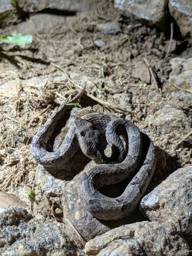

exact_duplicate | Hypnale hypnale | stored file 375 x 500 px, 199,542 bytes | credit: (c) Ahirbudhnyan M, some rights reserved (CC BY)


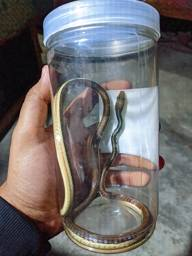

exact_duplicate | Dendrelaphis tristis | stored file 375 x 500 px, 162,134 bytes | credit: (c) HM Emon, some rights reserved (CC BY)


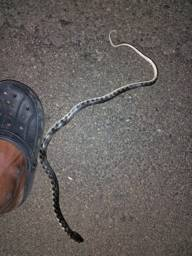

exact_duplicate | Fowlea piscator | stored file 375 x 500 px, 180,828 bytes | credit: (c) renjus box, some rights reserved (CC BY)


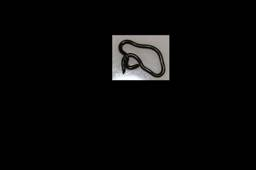

too_small | Indotyphlops braminus | stored file 500 x 333 px, 4,147 bytes | credit: no rights reserved


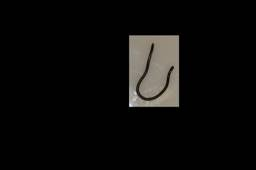

too_small | Indotyphlops braminus | stored file 500 x 333 px, 3,771 bytes | credit: no rights reserved


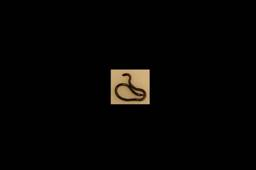

too_small | Indotyphlops braminus | stored file 500 x 333 px, 2,885 bytes | credit: no rights reserved


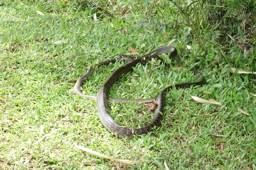

duplicate_conflicting_species | Fowlea piscator | stored file 500 x 333 px, 251,400 bytes | credit: (c) Oleg Kosterin, some rights reserved (CC BY)


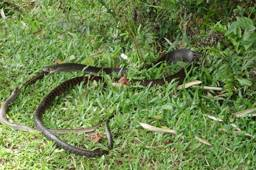

duplicate_conflicting_species | Fowlea piscator | stored file 500 x 333 px, 245,012 bytes | credit: (c) Oleg Kosterin, some rights reserved (CC BY)


In [206]:
for jpeg, r in tab_thumbs:
    display(IPImage(data=jpeg, format="jpeg"))
    print(f"{r.drop_reason} | {r.species} | stored file {r.width} x {r.height} px, {r.bytes:,} bytes | credit: {r.attribution}")
if not tab_thumbs:
    print("no photo could be fetched in this run")

A thumbnail shows what is at the address today, which can differ from the stored file that was excluded, for example when a download was cut short. The credit line is the `attribution` column as it is.

### 7b. Snake masks: the tables
The masks dataset holds a segmentation mask for training photos only, made with a snake detector and a segmentation model. `mask_stats.csv` has one row per photo with the detector score, mask size and a `flagged` column (true means check the mask before using it). Nothing here is typed in: the counts come from the file attached to this notebook, which may grow when a new version is published.

In [207]:
tab_mk = mask_stats.copy()
tab_mk_n = tab_mk.groupby("species").size().rename("masks")
tab_cov = classes.set_index("species")[["train", "who_category"]].join(tab_mk_n).fillna({"masks": 0})
tab_cov["coverage"] = tab_cov["masks"] / tab_cov["train"]
print(f"{len(tab_mk):,} masks for {tab_mk['species'].nunique()} classes; per class: smallest {tab_mk_n.min()}, median {tab_mk_n.median():.0f}, largest {tab_mk_n.max()}")
print(f"the masks cover {len(tab_mk) / tab_cov['train'].sum():.1%} of the training photos")
check("every mask belongs to a train photo", tab_mk["path"].str.startswith("train/").all())
check("every mask photo_id is a photo in metadata.csv", tab_mk["photo_id"].isin(meta["photo_id"]).all())
check("mask_stats has the expected columns", {"n_snake_boxes", "n_removed_boxes", "det_score", "mask_area_fraction", "fill_ratio", "flagged"} <= set(tab_mk.columns))

129,241 masks for 208 classes; per class: smallest 13, median 117, largest 13311
the masks cover 100.0% of the training photos
PASS  every mask belongs to a train photo
PASS  every mask photo_id is a photo in metadata.csv
PASS  mask_stats has the expected columns


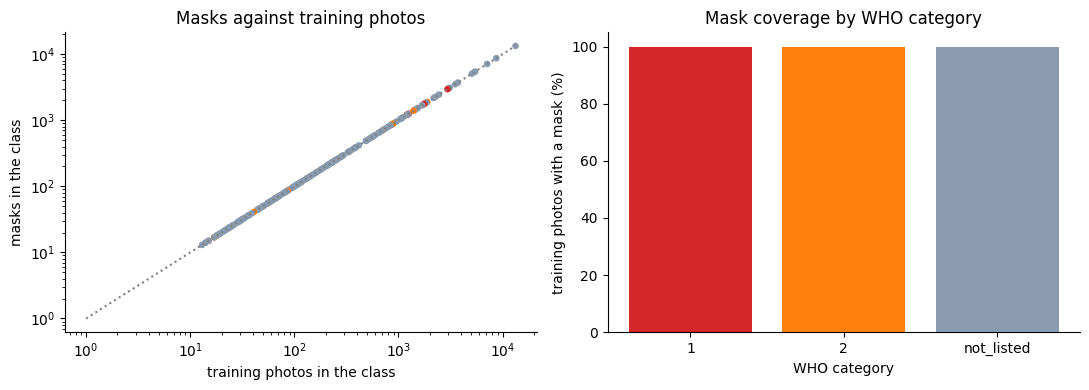

,masks,train,coverage %
who_category,,,
1,9742,9742,100.0
2,6579,6579,100.0
not_listed,112920,112920,100.0


In [208]:
tab_cov_who = tab_cov.groupby("who_category")[["masks", "train"]].sum().reindex(["1", "2", "not_listed"])
tab_cov_who["coverage %"] = (100 * tab_cov_who["masks"] / tab_cov_who["train"]).round(1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(tab_cov["train"], tab_cov["masks"], c=[WHO_COLORS[w] for w in tab_cov["who_category"]], s=14)
ax[0].plot([1, tab_cov["train"].max()], [1, tab_cov["train"].max()], ls=":", color="grey")
ax[0].set(xscale="log", yscale="log", xlabel="training photos in the class", ylabel="masks in the class", title="Masks against training photos")
ax[1].bar(tab_cov_who.index, tab_cov_who["coverage %"], color=[WHO_COLORS[c] for c in tab_cov_who.index])
ax[1].set(xlabel="WHO category", ylabel="training photos with a mask (%)", title="Mask coverage by WHO category")
savefig("07b_coverage"); plt.close()
tab_cov_who

The dotted line is where every training photo would have a mask, and a class below it has fewer masks than training photos. The printed coverage shows how much of the training set the masks reach. If coverage depends on class size, the WHO categories differ partly for that reason.

Now the flagged rate. A flagged mask needs a manual check before use, so let's see how often it happens in each WHO category.

overall flagged rate: 25.0% (32,312 of 129,241)


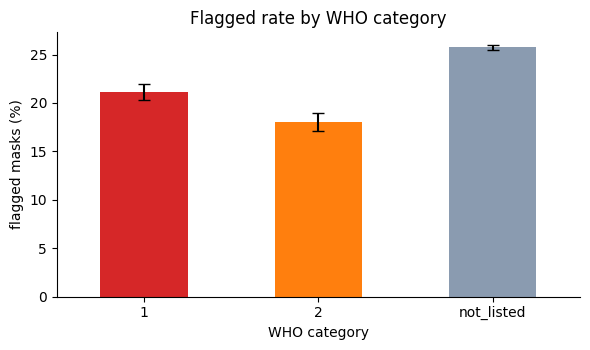

,flagged,masks,rate_pct
who_category,,,
1,2061,9742,21.2
2,1188,6579,18.1
not_listed,29063,112920,25.7


In [209]:
tab_fl = tab_mk.groupby("who_category")["flagged"].agg(flagged="sum", masks="size", rate="mean").reindex(["1", "2", "not_listed"])
tab_fl["error"] = 1.96 * np.sqrt(tab_fl["rate"] * (1 - tab_fl["rate"]) / tab_fl["masks"])
print(f"overall flagged rate: {tab_mk['flagged'].mean():.1%} ({int(tab_mk['flagged'].sum()):,} of {len(tab_mk):,})")
ax = (100 * tab_fl["rate"]).plot.bar(yerr=100 * tab_fl["error"], color=[WHO_COLORS[c] for c in tab_fl.index], rot=0, figsize=(6, 3.6), capsize=4)
ax.set(xlabel="WHO category", ylabel="flagged masks (%)", title="Flagged rate by WHO category")
savefig("07b_flagged_who"); plt.close()
tab_fl[["flagged", "masks"]].assign(rate_pct=(100 * tab_fl["rate"]).round(1))

The bars show the flagged rate with a 95% interval. A flagged mask is not wrong for sure, it only means the automatic checks were not satisfied, so a high flagged rate in one category means more manual review there. Is the flag linked to the detector score?

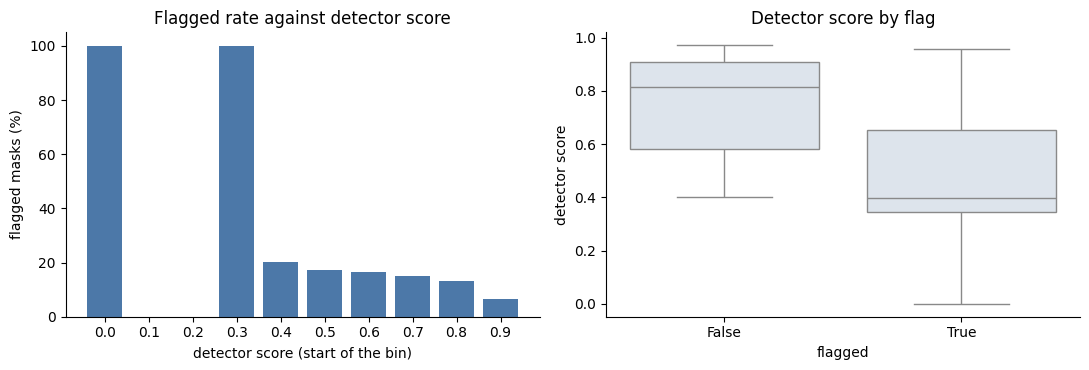

In [210]:
tab_cuts = pd.cut(tab_mk["det_score"], np.arange(0, 1.01, 0.1), include_lowest=True)
tab_fd = tab_mk.groupby(tab_cuts, observed=False).agg(masks=("flagged", "size"), flagged_pct=("flagged", lambda s: 100 * s.mean())).fillna(0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(range(len(tab_fd)), tab_fd["flagged_pct"], color="#4c78a8")
ax[0].set_xticks(range(len(tab_fd)), [f"{max(iv.left, 0):.1f}" for iv in tab_fd.index])
ax[0].set(xlabel="detector score (start of the bin)", ylabel="flagged masks (%)", title="Flagged rate against detector score")
sns.boxplot(data=tab_mk, x="flagged", y="det_score", color="#dbe4ee", ax=ax[1])
ax[1].set(xlabel="flagged", ylabel="detector score", title="Detector score by flag")
savefig("07b_flagged_score"); plt.close()

Low detector scores are flagged much more often, which is what we would expect if the flag partly follows the detector's confidence. The photos with a score of zero are the ones where no snake was found at all. The next lines print the lowest values that still pass, to see whether the flag looks like a set of thresholds.

In [211]:
tab_ok = tab_mk[~tab_mk["flagged"]]
print("lowest values among the unflagged masks:", {c: round(float(tab_ok[c].min()), 3) for c in ["det_score", "mask_area_fraction", "fill_ratio"]})
print("highest values among the unflagged masks:", {c: round(float(tab_ok[c].max()), 3) for c in ["det_score", "mask_area_fraction", "fill_ratio"]})
print(f"fill ratio above 1 (the mask is larger than its box): {(tab_mk['fill_ratio'] > 1).sum():,} masks")

lowest values among the unflagged masks: {'det_score': 0.4, 'mask_area_fraction': 0.01, 'fill_ratio': 0.1}
highest values among the unflagged masks: {'det_score': 0.971, 'mask_area_fraction': 0.6, 'fill_ratio': 0.95}
fill ratio above 1 (the mask is larger than its box): 275 masks


If the unflagged masks stop at round limits on score, area and fill ratio, the flag is a set of thresholds on these numbers. A fill ratio above 1 means the mask is larger than its own box, which should not happen, so those few rows are worth a look. Now the area fraction (how much of the photo the snake covers) and the fill ratio (how much of its box the mask fills).

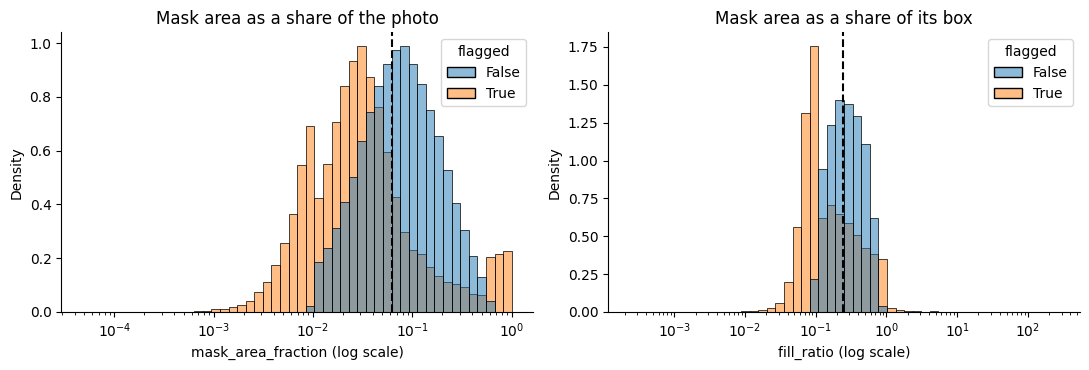

In [212]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, col, title in zip(ax, ["mask_area_fraction", "fill_ratio"], ["Mask area as a share of the photo", "Mask area as a share of its box"]):
    sns.histplot(data=tab_mk.dropna(subset=[col]), x=col, hue="flagged", log_scale=True, bins=50, stat="density", common_norm=False, ax=a)
    a.axvline(tab_mk[col].median(), color="k", ls="--"); a.set(title=title, xlabel=f"{col} (log scale)")
savefig("07b_area_fill"); plt.close()

Most masks cover only a small part of the photo and fill only a fraction of their box, which is normal for a long thin animal that curves. Flagged masks sit further to the left, where the masks are small, and spread out on both sides. The dashed line marks the median of all masks, flagged or not.

Three more kinds of photo are worth counting: two snakes in one photo, hands or gloves that were removed from the mask, and photos where no snake was found.

In [213]:
tab_mk["two_snakes"] = tab_mk["n_snake_boxes"] >= 2
tab_mk["hand_removed"] = tab_mk["n_removed_boxes"] > 0
tab_mk["no_snake"] = tab_mk["n_snake_boxes"] == 0
tab_kinds = ["flagged", "two_snakes", "hand_removed", "no_snake"]
tab_kind_n = pd.DataFrame({"photos": tab_mk[tab_kinds].sum(), "share %": 100 * tab_mk[tab_kinds].mean(), "of which flagged %": [100 * tab_mk.loc[tab_mk[k], "flagged"].mean() for k in tab_kinds]})
tab_kind_n.round(1)

,photos,share %,of which flagged %
flagged,32312,25.0,100.0
two_snakes,5568,4.3,77.4
hand_removed,5843,4.5,45.4
no_snake,3932,3.0,100.0


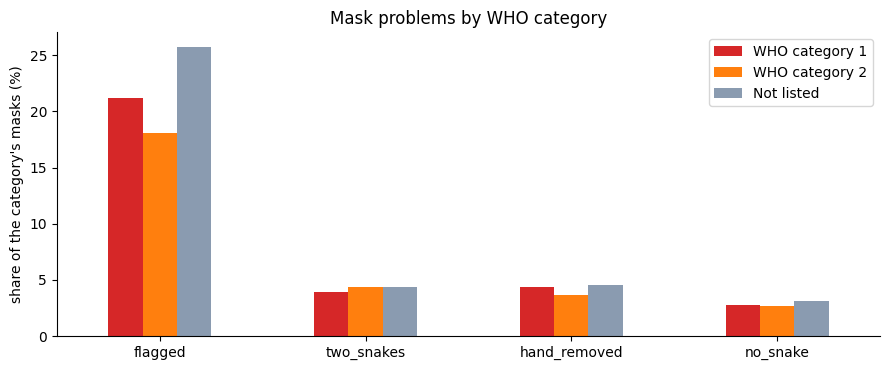

In [214]:
tab_mk_rates = (100 * tab_mk.groupby("who_category")[tab_kinds].mean()).reindex(["1", "2", "not_listed"])
ax = tab_mk_rates.T.plot.bar(color=[WHO_COLORS[c] for c in tab_mk_rates.index], rot=0, figsize=(9, 3.8))
ax.set(ylabel="share of the category's masks (%)", title="Mask problems by WHO category"); ax.legend([WHO_LABEL[c] for c in tab_mk_rates.index])
savefig("07b_kinds"); plt.close()

The table above shows how often each kind of photo is flagged. A photo with no snake has nothing to cut out and one mask cannot describe two animals, so these groups are expected to be flagged more often than the rest. The bars compare the three WHO categories, so we can see whether one of them has more trouble than the others.

In [215]:
tab_ns = tab_mk.groupby("species").agg(masks=("no_snake", "size"), no_snake=("no_snake", "sum"))
tab_ns["no snake %"] = (100 * tab_ns["no_snake"] / tab_ns["masks"]).round(1)
print(f"no snake found in {int(tab_ns['no_snake'].sum()):,} photos; {int((tab_ns['no_snake'] > 0).sum())} classes have at least one")
print("always flagged:", bool(tab_mk.loc[tab_mk["no_snake"], "flagged"].all()))
tab_ns[tab_ns["masks"] >= 20].sort_values("no snake %", ascending=False).head(8)

no snake found in 3,932 photos; 131 classes have at least one
always flagged: True


,masks,no_snake,no snake %
species,,,
Ahaetulla borealis,812,112,13.8
Ahaetulla farnsworthi,486,62,12.8
Ahaetulla isabellina,211,23,10.9
Ahaetulla prasina,8693,933,10.7
Ahaetulla oxyrhynca,1041,107,10.3
Boiga dightoni,29,3,10.3
Ahaetulla malabarica,286,27,9.4
Dendrelaphis andamanensis,71,6,8.5


These are the classes where the detector finds nothing most often. Photos with no snake need a manual look or have to be left out of any step that depends on a mask.

### 7b-overlays. Snake mask overlays
The numbers above say how many masks are flagged. Here we look at the masks themselves. Each mask is a black and white PNG with the same size as its photo (white is snake). The file sits under `masks/<split>/<species>/` in the masks dataset, with the same name as the photo.

In the pictures the mask is the orange area with a yellow edge, the blue rectangle is the box the detector found for the snake, and a white rectangle is a hand or glove box that was cut out of the mask. Only CC0 and CC BY photos are shown (CC BY-NC only as a fallback, which the credit table marks). Photos with a detected face are skipped, and a note is printed if there are too few others.

In [216]:
def img_mask_file(mask_path):
    for base in (MASKS / "masks", MASKS):
        if isinstance(mask_path, str) and (base / mask_path).exists():
            return base / mask_path
    return None

img_mask_start = len(IMG_BYTES)
img_mstats = mask_stats.merge(meta[["path", "license", "attribution"]], on="path", how="left")
img_mstats = img_mstats[img_mstats["mask_path"].notna()].copy()
print(f"{len(img_mstats):,} masks have a mask file listed in mask_stats.csv, mask folder found: {(MASKS / 'masks').exists()}")

125,309 masks have a mask file listed in mask_stats.csv, mask folder found: True


A mask is flagged when there is no snake, the detector score is low, the mask fills too little or too much of its box, or it covers too little or too much of the photo. I rebuild that rule here to label every flagged mask with a reason, and check it against the `flagged` column.

In [217]:
def img_flag_reason(d):
    conds = [d["n_snake_boxes"] == 0, d["det_score"] < 0.40, d["fill_ratio"] < 0.10, d["fill_ratio"] > 0.95,
             d["mask_area_fraction"] < 0.01, d["mask_area_fraction"] > 0.60]
    names = ["no snake", "low score", "low fill", "high fill", "tiny area", "huge area"]
    return np.select(conds, names, default="ok")

img_mstats["reason"] = img_flag_reason(img_mstats)
agree = ((img_mstats["reason"] != "ok") == img_mstats["flagged"]).mean()
check("flag reasons rebuilt from the thresholds agree with the flagged column", agree >= 0.99, f"{agree:.2%}")
img_mstats.loc[img_mstats["flagged"], "reason"].value_counts()

PASS  flag reasons rebuilt from the thresholds agree with the flagged column  (100.00%)


reason
low score    13121
low fill     10759
tiny area     3368
huge area      911
high fill      221
Name: count, dtype: int64

Picking the examples: shuffle with the fixed seed, spread over WHO categories (good masks) or over flag reasons (flagged masks), and keep only photos and masks that exist on disk. These photos are not all in the measured sample, so the face detector from section 5 is run on each candidate here (photos from the sample reuse their stored face count).

In [218]:
IMG_FACE_CACHE = dict(zip(quality["path"], quality["face_count"]))

def img_faces(path):
    if path not in IMG_FACE_CACHE:
        IMG_FACE_CACHE[path] = img_face_count(np.asarray(Image.open(img_file(path)).convert("RGB")))
    return IMG_FACE_CACHE[path]

In [219]:
def img_mask_scan(df, spread, n):
    d = df.sample(frac=1, random_state=SEED)
    d = d.assign(r=d.groupby(spread).cumcount()).sort_values("r", kind="stable")
    seen, free = [], 0
    for i, row in zip(d.index, d.itertuples()):
        if img_file(row.path).exists() and img_mask_file(row.mask_path):
            seen.append((i, img_faces(row.path)))
            free += seen[-1][1] == 0
        if free >= n:
            break
    return d.loc[[i for i, c in seen]].assign(face_count=[c for i, c in seen])

In [220]:
def img_mask_rows(df, n, spread):
    got = []
    for faces in (False, True):
        for tier in (["cc0", "cc-by"], ["cc-by-nc"]):
            have = sum(len(g) for g in got)
            if have < n:
                part = img_mask_scan(df[df["license"].isin(tier)], spread, n - have)
                got.append(part[(part["face_count"] > 0) == faces].head(n - have))
    return pd.concat(got)

Now the drawing. Everything is done on the small copy (at most 224 px wide), so the lines stay thin and the file stays small.

In [221]:
def img_paint_mask(arr, mask):
    on = np.asarray(mask) > 127
    arr[on] = (0.55 * arr[on] + 0.45 * np.array([235, 104, 52])).astype(np.uint8)
    edges, _ = cv2.findContours(on.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(arr, edges, -1, (255, 230, 0), 1)

def img_draw_boxes(arr, boxes, scale, colour):
    for x1, y1, x2, y2 in boxes:
        cv2.rectangle(arr, (round(x1 * scale), round(y1 * scale)), (round(x2 * scale), round(y2 * scale)), colour, 1)

In [222]:
def img_overlay(row, show_mask=True, show_boxes=True, w=224, h=170):
    pic = Image.open(img_file(row.path)).convert("RGB")
    scale = min(w / pic.width, h / pic.height)
    size = (round(pic.width * scale), round(pic.height * scale))
    arr = np.array(pic.resize(size))
    if show_mask:
        img_paint_mask(arr, Image.open(img_mask_file(row.mask_path)).convert("L").resize(size, Image.NEAREST))
    if show_boxes:
        img_draw_boxes(arr, json.loads(row.snake_boxes), scale, (42, 120, 214))
        img_draw_boxes(arr, json.loads(row.removed_boxes), scale, (255, 255, 255))
    return Image.fromarray(arr)

In [223]:
def img_mask_grid(rows, kind, text):
    if rows.empty:
        print(f"no {kind} masks with a usable CC photo on disk, skipped")
        return
    rows = img_label(rows, kind[0].upper())
    entries = [(img_overlay(r), f"{r.label}. {img_short(r.species)} | {text(r)}") for r in rows.itertuples()]
    img_show(img_grid(entries + [None] * (-len(entries) % 4)))
    img_credits(rows, ["det_score", "mask_area_fraction", "fill_ratio", "reason"])

#### Good masks
Unflagged masks, mixed over the WHO categories. The number after the species is the detector score.

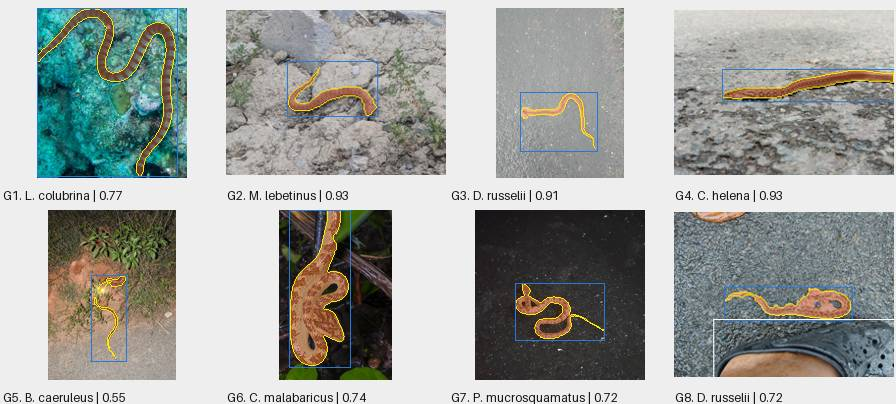

,species,WHO,det_score,mask_area_fraction,fill_ratio,reason,licence,credit
G1,Laticauda colubrina,Not listed,0.77,0.14,0.15,ok,cc-by,"(c) portioid, some rights reserved (CC BY)"
G2,Macrovipera lebetinus,WHO category 2,0.93,0.03,0.24,ok,cc-by,"(c) Marios Thoma, some rights reserved (CC BY)"
G3,Daboia russelii,WHO category 1,0.91,0.03,0.14,ok,cc-by,"(c) vaazhaikumar, some rights reserved (CC BY)"
G4,Coelognathus helena,Not listed,0.93,0.05,0.33,ok,cc-by,"(c) Jagdish Singh Negi, some rights reserved (CC BY)"
G5,Bungarus caeruleus,WHO category 1,0.55,0.02,0.13,ok,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
G6,Craspedocephalus malabaricus,WHO category 2,0.74,0.26,0.52,ok,cc-by,"(c) Ramesh Shenai, some rights reserved (CC BY)"
G7,Protobothrops mucrosquamatus,Not listed,0.72,0.04,0.24,ok,cc-by,"(c) naturalist132890, some rights reserved (CC BY)"
G8,Daboia russelii,WHO category 1,0.72,0.05,0.41,ok,cc-by,"(c) renjus box, some rights reserved (CC BY)"


In [224]:
img_good = img_mask_rows(img_mstats[~img_mstats["flagged"]], 8, "who_category")
img_mask_grid(img_good, "good", lambda r: f"{r.det_score:.2f}")

#### Flagged masks
Flagged masks, mixed over the flag reasons. The text after the species is the reason. The table shows the numbers behind it, so we can judge whether each flag was fair.

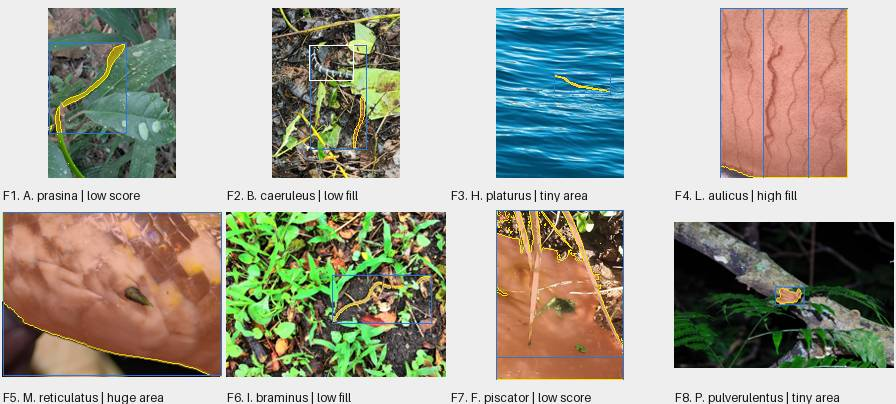

,species,WHO,det_score,mask_area_fraction,fill_ratio,reason,licence,credit
F1,Ahaetulla prasina,Not listed,0.40,0.03,0.09,low score,cc-by,"(c) Steven Bodzin, some rights reserved (CC BY)"
F2,Bungarus caeruleus,WHO category 1,0.57,0.01,0.04,low fill,cc-by,"(c) Ashwin A, some rights reserved (CC BY)"
F3,Hydrophis platurus,Not listed,0.63,0.01,0.11,tiny area,cc-by,"(c) Rob Foster, some rights reserved (CC BY)"
F4,Lycodon aulicus,Not listed,0.41,0.99,0.99,high fill,cc-by,"(c) Viral joshi, some rights reserved (CC BY)"
F5,Malayopython reticulatus,Not listed,0.54,0.82,0.84,huge area,cc-by,"(c) Jay Paroline, some rights reserved (CC BY)"
F6,Indotyphlops braminus,Not listed,0.84,0.01,0.06,low fill,cc0,no rights reserved
F7,Fowlea piscator,Not listed,0.36,0.69,0.80,low score,cc-by,"(c) Navaneeth Sini George, some rights reserved (CC BY)"
F8,Psammodynastes pulverulentus,Not listed,0.65,0.01,0.57,tiny area,cc-by,"(c) Jay Paroline, some rights reserved (CC BY)"


In [225]:
img_flagged = img_mask_rows(img_mstats[img_mstats["flagged"]], 8, "reason")
img_mask_grid(img_flagged, "flagged", lambda r: r.reason)

#### Before and after hand removal
People often hold the snake. The detector looks for hands and gloves in a second pass and cuts them out of the snake mask. On the left the boxes the detector found (blue for the snake, white for the hand or glove), on the right the final mask.

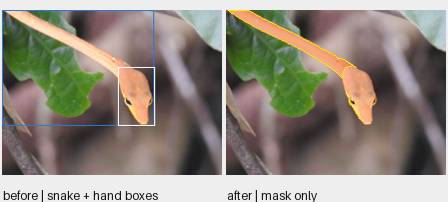

Ahaetulla prasina (cc-by), 1 hand or glove box removed, credit: (c) Artem Abdukakharov, some rights reserved (CC BY)


In [226]:
img_hands = img_mask_rows(img_mstats[img_mstats["n_removed_boxes"] > 0], 1, "who_category")
if img_hands.empty:
    print("no hand-removal example with a usable CC photo on disk, skipped")
else:
    hand = next(img_hands.itertuples())
    pair = [(img_overlay(hand, show_mask=False), "before | snake + hand boxes"), (img_overlay(hand, show_boxes=False), "after | mask only")]
    img_show(img_grid(pair, cols=2))
    print(f"{hand.species} ({hand.license}), {hand.n_removed_boxes} hand or glove box removed, credit: {hand.attribution}")

A last size check for the mask pictures.

In [227]:
img_mask_mb = sum(IMG_BYTES[img_mask_start:]) / 1e6
check("mask overlay pictures stay under 0.8 MB together", img_mask_mb <= 0.8, f"{len(IMG_BYTES) - img_mask_start} pictures, {img_mask_mb:.2f} MB")

PASS  mask overlay pictures stay under 0.8 MB together  (3 pictures, 0.15 MB)


## 9. Summary
The notebook ends with three things: one table of the main numbers, a tally of every check that ran, and what the data means for modelling. All numbers in the table are computed here from the tables above.

### 9.1 Key numbers
First the numbers about the data, the labels and the class balance.

In [228]:
tab_key = []

def tab_add(group, name, value):
    tab_key.append((group, name, round(float(value), 2)))

tab_add("data", "photos", len(meta))
tab_add("data", "classes", len(classes))
tab_add("data", "families", meta["family"].nunique())
tab_add("data", "photos in the unknown pool", (meta["tier"] == "unknown_pool").sum())
tab_add("labels", "WHO category 1 photos (%)", 100 * (meta["who_category"] == "1").mean())
tab_add("labels", "WHO category 2 photos (%)", 100 * (meta["who_category"] == "2").mean())
tab_add("labels", "classes in WHO category 1 or 2", (classes["who_category"] != "not_listed").sum())
tab_add("balance", "share of photos in the 10 largest classes (%)", 100 * tab_n.head(10).sum() / tab_n.sum())
tab_add("balance", "imbalance ratio, largest to smallest class", tab_imb.loc["imbalance ratio (largest / smallest)", "all splits"])
tab_add("balance", "Gini of class counts", tab_imb.loc["Gini of class counts", "all splits"])
tab_add("balance", "effective number of classes (1 / sum p^2)", tab_imb.loc["effective classes (1 / sum p^2)", "all splits"])

Next the splits, the leakage checks and the cleaning funnel.

In [229]:
tab_add("splits", "test photos (% of all photos)", 100 * (meta["split"] == "test").mean())
tab_add("splits", "classes with no test photos", len(tab_zero))
tab_add("splits", "classes with no val photos", (classes["val"] == 0).sum())
tab_add("splits", "keys shared between train, val and test (sum of the leakage table)", tab_leak.values.sum())
tab_add("splits", "test photos that break the test rule", tab_viol.sum())
tab_add("cleaning", "raw rows", tab_raw)
tab_add("cleaning", "rows in excluded.csv", len(excluded))
tab_add("cleaning", "near-duplicates removed from val and test", len(tab_nd))
tab_add("cleaning", "largest share of a species lost (%)", tab_loss["share lost %"].max())

Last the images, the context columns and the masks.

In [230]:
tab_add("images", "median file size (KB)", tab_kb.median())
tab_add("images", "largest file (MB)", tab_img["bytes"].max() / 1e6)
tab_add("images", "photos with the short side below 224 px (%)", 100 * tab_small_share[224])
tab_add("images", "photos with a non-jpg address in the url column", (~tab_img["url_ext"].isin(["jpg", "jpeg"])).sum())
tab_add("context", "photographers", len(tab_obs))
tab_add("context", "share of photos from the top 1% of photographers (%)", 100 * tab_top1)
tab_add("context", "photos inside India (%)", 100 * meta["in_india"].mean())
tab_add("context", "photos that can be shown first, CC0 or CC BY (%)", 100 * (tab_show == "show first").mean())
tab_add("context", "classes with no CC0 or CC BY photo", tab_few.iloc[0])
tab_add("masks", "masks in mask_stats.csv", len(tab_mk))
tab_add("masks", "flagged masks (%)", 100 * tab_mk["flagged"].mean())

In [231]:
tab_keydf = pd.DataFrame(tab_key, columns=["group", "number", "value"]).set_index(["group", "number"])
tab_keydf

value
group    number                                                       
data     photos                                              181231.00
         classes                                                208.00
         families                                                14.00
         photos in the unknown pool                             656.00
labels   WHO category 1 photos (%)                                7.52
         WHO category 2 photos (%)                                5.15
         classes in WHO category 1 or 2                          17.00
balance  share of photos in the 10 largest classes (%)           45.02
         imbalance ratio, largest to smallest class             916.40
         Gini of class counts                                     0.76
         effective number of classes (1 / sum p^2)               32.76
splits   test photos (% of all photos)                            4.03
         classes with no test photos                             28.00
         classes with no val photos                               1.00
         keys shared between train, val and test (sum of...       0.00
         test photos that break the test rule                     0.00
cleaning raw rows                                            182497.00
         rows in excluded.csv                                   994.00
         near-duplicates removed from val and test              272.00
         largest share of a species lost (%)                     20.60
images   median file size (KB)                                  124.96
         largest file (MB)                                       26.16
         photos with the short side below 224 px (%)              0.67
         photos with a non-jpg address in the url column        536.00
context  photographers                                        25041.00
         share of photos from the top 1% of photographer...      26.64
         photos inside India (%)                                 37.68
         photos that can be shown first, CC0 or CC BY (%)         9.07
         classes with no CC0 or CC BY photo                      24.00
masks    masks in mask_stats.csv                             129241.00
         flagged masks (%)                                       25.00

### 9.2 How the checks went
Every `check()` call in the notebook prints PASS or FAIL and keeps its result. Here is the tally.

In [232]:
tab_pass = sum(ok for _, ok in CHECKS)
print(f"{len(CHECKS)} checks ran: {tab_pass} passed, {len(CHECKS) - tab_pass} failed")
for label, ok in CHECKS:
    if not ok:
        print("FAIL  ", label)
if tab_pass == len(CHECKS):
    print("no check failed")

80 checks ran: 80 passed, 0 failed
no check failed


A failed check means the data differs from what the earlier reports said, so it is a finding and not an error in the notebook. Each one is worth reading next to the cell that printed it.

### 9.3 What this means for modelling
These points follow from the tables and charts above. They refer to the tables instead of repeating the numbers, so they stay true when the data is refreshed.

- **Class imbalance.** The imbalance table in section 2.2 shows a very large ratio between the largest and smallest class, and an effective number of classes far below the real one. Plain accuracy would mostly reflect a few big species. Use macro-averaged scores, per-class recall and per-tier results, and try class-balanced sampling or loss weights.
- **Tiny classes.** Many classes have only a few dozen photos (2.2 and 2.5). Training them from scratch is not realistic: use a pretrained backbone, strong augmentation, and consider grouping the rarest classes under a coarser label such as the genus. Scores on these classes rest on very few val and test photos, so they move a lot.
- **Classes with no test photos.** Some classes, including some in WHO categories 1 and 2, have no test photos (3.3). They can only be checked on val or test_extra, which do not follow the test rule. Report them separately instead of calling the test score a score over all classes.
- **Near-duplicates and repeated uploads.** Exact duplicates were dropped everywhere, and near-duplicates only from val and test (7a). Copies can still sit inside train, which inflates its size without adding information, so it is worth looking for them before choosing a model size.
- **Look-alikes.** The dangerous and harmless sides of each pair are rarely balanced, and the smaller side of a pair limits how well it can be tested (7). A dangerous snake called harmless costs far more than the reverse, so report the confusion between the two sides of every pair, favour recall for WHO categories 1 and 2, and check that photo style does not separate the pairs (7.1). The pairs with two dangerous snakes (7.2) deserve their own confusion counts too.
- **Photographers and place.** A few photographers take a large share of the photos, and small classes lean on a handful of them (6.3). Keep splits grouped by observer, limit how many photos one person adds to a class, and expect a gap between val and test, since test is India only and recent while train and val mix many countries (3.4 and 6.1).
- **Licences.** Only a minority of photos are CC0 or CC BY, some classes have none, and many photos are all rights reserved or no-derivatives (6.4). Those photos serve for statistics here but must not be shown or passed on. Any shared dataset, demo or figure has to follow the licence of each photo and credit the photographer, and the non-commercial licences need a check before commercial use.
- **Image files.** Every photo is at most 500 px on its long side, many are portrait, and a few files came from .gif or .png addresses and are very large (4.6). Resize while keeping the aspect ratio, take a single frame from animated files, and consider re-encoding or dropping the extreme files.
- **Coordinates.** Some coordinates are missing and many are obscured, so location is a weak feature. The `in_india` flag is filled for every photo and is safer to use.
- **Masks.** Flagged masks need a manual look before use, and photos with no snake or two snakes tend to be flagged (7b). Train mask-based steps on unflagged masks, and check how much of the training set the attached version of the masks covers.

### 9.4 Order of operations: what is done, and where to find it
Image data is usually prepared in a fixed order, because some steps only make sense after others. For example, anything that is learned from the data, like colour statistics, has to wait until the split exists. This table lines up that order with what has been done for this project and where in the notebook it shows.

| # | Step | What it protects against | Status | Where |
|---|---|---|---|---|
| 1 | Keep source, licence and photographer for every photo | Using photos we are not allowed to show or share | Done in the dataset | 4.7, 4.8, 6.4 |
| 2 | Check that every file opens and matches the table | Broken files, wrong sizes | Done, and checked again here | 1.3, 5.4 |
| 3 | One format and one size | Mixed formats and sizes | Done in the dataset (JPEG, long side 500 px) | 4.1 to 4.4 |
| 4 | Remove exact duplicates (file hash and picture hash) | The same photo in train and test | Done | 3.5, 7a |
| 5 | Look for near-duplicates | Near copies that lift the test score | Partly: only exact picture-hash matches were dropped from val and test. The rest is measured here and flagged | 3.6, 5.6, 5.14 |
| 6 | Check the labels | Wrong or mixed-up labels | Checked here: class table, subspecies, label-issue list | 1.4, 3.6, 5.15 |
| 7 | Split first, grouped by photographer | Information leaking from test into training | Done | 3.1 to 3.5 |
| 8 | Work out normalisation numbers on training photos only | Test statistics leaking into training | Estimated here from the sample. To be redone on the full training set | 5.13 |
| 9 | Resize, crop and normalise inside the model input pipeline | Train and test photos treated differently | Next, Milestone 3 | |
| 10 | Augment training photos only | Changing the photos we test on | Next, Milestone 3. Hints: photo shape (3.6), colour (5.13), look-alike pairs (7) | |
| 11 | Deal with class imbalance while training | A model that ignores rare species | Next, Milestone 3 | 2.2 |
| 12 | Keep a record of what was done | Results nobody can reproduce | Done: `processing_report.json`, `excluded.csv`, `splits.csv`, and this notebook with a fixed seed | 1.5, 7a |

Steps 1 to 8 are about the data and are covered by this milestone. Steps 9 to 11 belong to training and are listed so they are not forgotten. Step 5 is the one with an open item: the near-copies counted in 3.6 are a small share of each split, but removing them is cheap, so the team should decide before the final split is frozen.

### 9.5 What sections 5.13 to 5.15 add
- **Colour:** normalise with the training numbers from 5.13 (redone on the full training set) and not the ImageNet defaults. test_extra is darker than train, so keep brightness and contrast augmentation.
- **Do the splits look alike?** On embeddings, a classifier cannot tell val or test photos from training photos (5.14), so there is no large hidden shift. The size and shape gaps found in 3.6 are what is left.
- **Near-copies:** the embedding found photos from different photographers that look almost the same, one pair across test and val. Look at them before the split is frozen.
- **Labels:** the label-issue list in 5.15 is a ranking to check by hand, not a list of errors. Its top is mostly photos where the snake is hard to see.